## 1. 환경 설정 및 한글 폰트 설정
- 시각화 시 한글 깨짐 방지를 위해 `Malgun Gothic` 폰트 및 음수 기호 설정을 적용합니다.

In [11]:
import os
import glob
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# 경고 메시지 무시
warnings.filterwarnings('ignore')

# Matplotlib 한글 폰트 및 마이너스 부호 설정
plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Seaborn 테마 설정
sns.set_theme(style='whitegrid', font='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

print("환경 설정 완료: pandas, numpy, matplotlib, seaborn 로드 성공")

환경 설정 완료: pandas, numpy, matplotlib, seaborn 로드 성공


## 2. 데이터 수집 및 병합 (Data Ingestion)
- `data/` 디렉터리 내의 일반 감귤 데이터(`data/kat*.csv`) 및 만감류 전용 경매 데이터(`data/mkat*.csv`, 총 554개 분할 파일)를 탐색하여 병합합니다.
- 0바이트 빈 파일을 필터링하고 중복 데이터를 제거하여 단일 데이터프레임으로 통합합니다.

In [12]:
# 1) data/ 디렉터리 내 감귤(kat*.csv) 및 만감류(mkat*.csv) 전체 파일 검색 (fallback: output/)
data_dir = Path("../data")
data_files = sorted(list(set(
    glob.glob(str(data_dir / "kat*.csv")) +
    glob.glob(str(data_dir / "mkat*.csv")) +
    glob.glob(str(data_dir / "*kat*.csv"))
)))

if not data_files:
    print("data/ 디렉터리에 데이터 파일이 없어 output/ 디렉터리에서 검색합니다.")
    data_dir = Path("data")
    data_files = sorted(list(set(
        glob.glob(str(data_dir / "kat*.csv")) +
        glob.glob(str(data_dir / "mkat*.csv")) +
        glob.glob(str(data_dir / "*kat*.csv"))
    )))

# 0바이트 파일 및 _all.csv 제외한 유효 CSV 파일 선택
valid_files = [f for f in data_files if '_all.csv' not in f and os.path.getsize(f) > 50]
print(f"발견된 유효한 데이터 파일 수: {len(valid_files)}개 (대상 디렉터리: {data_dir.resolve()})")

# 2) 필요한 핵심 컬럼 선별 로드 (거래구분 trd_se 포함)
target_cols = [
    'trd_clcln_ymd', 'whsl_mrkt_cd', 'whsl_mrkt_nm', 'trd_se',
    'gds_sclsf_cd', 'gds_sclsf_nm', 'grd_cd', 'grd_nm', 'sz_cd', 'sz_nm',
    'pkg_cd', 'pkg_nm', 'unit_nm', 'unit_qty', 'unit_tot_qty', 'avgprc', 'totprc'
]

t0 = time.time()
dfs = []
for file_path in valid_files:
    try:
        df_sub = pd.read_csv(file_path, usecols=lambda c: c in target_cols, low_memory=False, encoding='utf-8-sig')
        dfs.append(df_sub)
    except Exception as exc:
        print(f"파일 로드 오류 건너뜀: {file_path} - {exc}")

df_raw = pd.concat(dfs, ignore_index=True)
elapsed = time.time() - t0
print(f"\n데이터 로드 완료! (소요시간: {elapsed:.2f}초)")
print(f"- 원본 데이터 총 행 수: {len(df_raw):,} 건")
print(f"- 원본 데이터 컬럼 수: {df_raw.shape[1]} 개")

# 중복 레코드 제거
raw_count = len(df_raw)
df_raw = df_raw.drop_duplicates()
print(f"- 중복 제거 후 행 수: {len(df_raw):,} 건 ({raw_count - len(df_raw):,}건 중복 제거됨)")
df_raw.head(3)


발견된 유효한 데이터 파일 수: 566개 (대상 디렉터리: D:\hongdonjoo\ai\project\ugasungsi\data)

데이터 로드 완료! (소요시간: 12.50초)
- 원본 데이터 총 행 수: 1,728,626 건
- 원본 데이터 컬럼 수: 17 개
- 중복 제거 후 행 수: 1,726,915 건 (1,711건 중복 제거됨)


,avgprc,gds_sclsf_cd,gds_sclsf_nm,grd_cd,grd_nm,pkg_cd,pkg_nm,sz_cd,sz_nm,totprc,trd_clcln_ymd,trd_se,unit_nm,unit_qty,unit_tot_qty,whsl_mrkt_cd,whsl_mrkt_nm
0,6519.048,1,조생귤,12,상,101,상자,100,.,6154700.0,2021-01-04,경매,kg,5.0,4485.0,210009,부산반여
1,7994.030,1,조생귤,12,상,101,상자,100,.,21994500.0,2021-01-04,경매,kg,5.0,12630.0,210009,부산반여
2,15383.333,1,조생귤,12,상,101,상자,100,.,5875500.0,2021-01-04,경매,kg,10.0,4140.0,210009,부산반여


## 3. 데이터 정제 및 전처리 (Data Cleaning & Feature Engineering)

### 정제 작업 상세:
1. **날짜 변환 및 파생변수 생성**: `trd_clcln_ymd` 문자열을 `datetime`으로 변환 후 `year`, `month`, `year_month`, `weekday` 생성
2. **거래 무효치 필터링**: 음수/0 거래수량 및 거래금액 정제 (`unit_tot_qty > 0`, `totprc > 0`, `avgprc > 0`)
3. **aT 공영도매시장 공식 표준 품종 코드 매핑**:
   - `gds_sclsf_cd` 07 (7) $
ightarrow$ **한라봉** (정상 복원)
   - `gds_sclsf_cd` 08 (8) $
ightarrow$ **천혜향** (정상 복원)
   - `gds_sclsf_cd` 09 (9) $
ightarrow$ **레드향**
   - `gds_sclsf_cd` 10 $
ightarrow$ **카라향**
   - `gds_sclsf_cd` 11 $
ightarrow$ **황금향**
   - 그 외 기존 소분류명 및 일반 감귤 표준 코드 적용
4. **거래구분(`trd_se`) 정제**: 경매, 수의계약(정가수의), 기타 거래 구분 컬럼(`trd_type`) 생성
5. **등급 및 크기 명칭 표준화**: 잡음 기호(`.`, 공백)를 `무등급/미지정`, `미지정`으로 표준화
6. **핵심 분석 지표 생성**:
   - `volume_kg`: 총 판매물량 (kg)
   - `box_qty`: 환산 판매상자 수 (`unit_tot_qty / unit_qty`)
   - `total_price`: 총 판매금액 (원)
   - `box_price`: 상자(포장)당 평균가격 (원/상자)
   - `unit_price_kg`: kg당 평균 판매단가 (`total_price / volume_kg`, 원/kg)
7. **단가 이상치 필터링**: kg당 단가가 100원 미만이거나 100,000원 초과인 극단 입력오류 정제

In [13]:
df = df_raw.copy()

# 1) 날짜 변환 및 시계열 파생변수
df['date'] = pd.to_datetime(df['trd_clcln_ymd'], errors='coerce')
df = df.dropna(subset=['date']).copy()
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['year_month'] = df['date'].dt.to_period('M').astype(str)
df['day_name'] = df['date'].dt.day_name()
weekday_kor = {'Monday': '월', 'Tuesday': '화', 'Wednesday': '수', 'Thursday': '목', 'Friday': '금', 'Saturday': '토', 'Sunday': '일'}
df['weekday'] = df['day_name'].map(weekday_kor)

# 2) 유효 거래 수량 및 금액 필터링 (음수 및 0 정산내역 제거)
valid_mask = (df['unit_tot_qty'] > 0) & (df['totprc'] > 0) & (df['avgprc'] > 0)
df = df[valid_mask].copy()

# 3) aT 공영도매시장 공식 표준 품종 코드 매핑 (07: 한라봉, 08: 천혜향, 09: 레드향, 10: 카라향, 11: 황금향)
citrus_variety_map = {
    0: '감귤(일반)', '0': '감귤(일반)', '00': '감귤(일반)',
    1: '조생귤', '1': '조생귤', '01': '조생귤',
    2: '중생귤', '2': '중생귤', '02': '중생귤',
    3: '만생귤', '3': '만생귤', '03': '만생귤',
    4: '비가림감귤', '4': '비가림감귤', '04': '비가림감귤',
    5: '하우스감귤', '5': '하우스감귤', '05': '하우스감귤',
    6: '극조생감귤', '6': '극조생감귤', '06': '극조생감귤',
    7: '한라봉', '7': '한라봉', '07': '한라봉',
    8: '천혜향', '8': '천혜향', '08': '천혜향',
    9: '레드향', '9': '레드향', '09': '레드향',
    10: '카라향', '10': '카라향',
    11: '황금향', '11': '황금향',
    12: '하루미', '12': '하루미',
    13: '온주', '13': '온주',
    15: '성전', '15': '성전',
    17: '홍미향', '17': '홍미향',
    19: '타이벡감귤', '19': '타이벡감귤',
    20: '풋귤(청귤)', '20': '풋귤(청귤)',
    23: '미니향', '23': '미니향',
    32: '유라와세', '32': '유라와세',
    34: '산하홍', '34': '산하홍',
    98: '감귤(수입)', '98': '감귤(수입)',
    99: '기타', '99': '기타'
}

# aT 표준 만감류 코드 오버라이드 매핑 (kat 데이터 결측 코드 보정용)
user_override_map = {
    7: '한라봉', '7': '한라봉', '07': '한라봉', 7.0: '한라봉',
    8: '천혜향', '8': '천혜향', '08': '천혜향', 8.0: '천혜향',
    9: '레드향', '9': '레드향', '09': '레드향', 9.0: '레드향',
    10: '카라향', '10': '카라향', 10.0: '카라향',
    11: '황금향', '11': '황금향', 11.0: '황금향'
}

# gds_sclsf_nm(문자열 품종명) 최우선 보존(mkat 및 kat 공통) 후, 결측 시 코드 매핑 적용
df['variety'] = (
    df['gds_sclsf_nm']
    .combine_first(df['gds_sclsf_cd'].map(user_override_map))
    .combine_first(df['gds_sclsf_cd'].map(citrus_variety_map))
    .fillna('기타')
)

# 4) 거래구분(trd_se) 표준화: 경매 vs 수의계약(정가수의)
df['trd_se_raw'] = df['trd_se'].fillna('기타').astype(str)
df['is_negotiated'] = df['trd_se_raw'].str.contains('수의', na=False)
df['is_auction'] = df['trd_se_raw'].str.contains('경매', na=False)
df['trd_type'] = np.where(df['is_negotiated'], '수의계약', np.where(df['is_auction'], '경매', '기타'))

# 5) 등급(Grade) 표준화
df['grade'] = df['grd_nm'].fillna('.').astype(str).str.strip()
df['grade'] = df['grade'].replace({'.': '무등급/미지정', '': '무등급/미지정', 'nan': '무등급/미지정'})

# 6) 크기(Size) 표준화
df['size'] = df['sz_nm'].fillna('.').astype(str).str.strip()
df['size'] = df['size'].replace({'.': '미지정', '': '미지정', 'nan': '미지정'})

# 7) 핵심 분석 수치 지표 계산
df['volume_kg'] = pd.to_numeric(df['unit_tot_qty'], errors='coerce').fillna(0.0)
df['unit_weight'] = pd.to_numeric(df['unit_qty'], errors='coerce').fillna(0.0)
df['box_qty'] = np.where(df['unit_weight'] > 0, df['volume_kg'] / df['unit_weight'], np.nan)
df['total_price'] = pd.to_numeric(df['totprc'], errors='coerce').fillna(0.0)
df['box_price'] = pd.to_numeric(df['avgprc'], errors='coerce').fillna(0.0)
df['unit_price_kg'] = df['total_price'] / (df['volume_kg'] + 1e-8)


# 7-2) 상자 규격(중량 및 포장단위) 표준화 (3kg/5kg/9kg/10kg 파렛트 -> 상자 통합)
df['box_weight'] = df['unit_weight'].apply(lambda w: f"{w:g}kg" if pd.notnull(w) and w > 0 else '기타')
df['pkg_clean'] = df['pkg_nm'].replace({'.': '상자', '': '상자', np.nan: '상자'}).fillna('상자')
df['box_unit'] = (df['box_weight'] + df['pkg_clean']).replace({
    '3kg파렛트': '3kg상자',
    '5kg파렛트': '5kg상자',
    '9kg파렛트': '9kg상자',
    '10kg파렛트': '10kg상자'
})

# 8) kg당 단가 극단 이상치 제거 (정상 도매 단가 범위: 100원/kg ~ 100,000원/kg)
df = df[(df['unit_price_kg'] >= 100) & (df['unit_price_kg'] <= 100000)].copy()

# 9) '감귤(일반)' 및 전체 거래건수 1,000건 미만 소수 품종을 '기타'로 통합
variety_counts = df['variety'].value_counts()
minor_varieties = variety_counts[variety_counts < 1000].index.tolist()
df['variety'] = df['variety'].replace(minor_varieties + ['감귤(일반)'], '기타')

print(f"전처리 완료 최종 데이터 행 수: {len(df):,} 건")
print(f"조회 기간: {df['date'].min().strftime('%Y-%m-%d')} ~ {df['date'].max().strftime('%Y-%m-%d')}")
print(f"포함된 전국 도매시장 수: {df['whsl_mrkt_nm'].nunique()}개 도매시장")
print(f"포함된 감귤 품종 수: {df['variety'].nunique()}개")
print(f"품종별 상위 레코드 수:\n{df['variety'].value_counts().head(8)}")
display(df[['date', 'whsl_mrkt_nm', 'trd_type', 'variety', 'grade', 'size', 'volume_kg', 'box_qty', 'box_price', 'unit_price_kg']].head())


summary_stats = pd.DataFrame({
    '총 거래 건수': [f"{len(df):,} 건"],
    '포함 도매시장 수': [f"{df['whsl_mrkt_nm'].nunique()} 개 시장"],
    '누적 거래물량(톤)': [f"{df['volume_kg'].sum() / 1000:,.1f} 톤"],
    '누적 환산상자수': [f"{df['box_qty'].sum():,.0f} 상자"],
    '총 거래금액(억원)': [f"{df['total_price'].sum() / 1e8:,.1f} 억원"],
    '평균 kg당 단가': [f"{df['total_price'].sum() / df['volume_kg'].sum():,.1f} 원/kg"],
    '평균 상자당 가격': [f"{df['box_price'].mean():,.0f} 원/상자"]
})
display(summary_stats.T.rename(columns={0: '전국 공영도매시장 감귤 거래 요약'}))

전처리 완료 최종 데이터 행 수: 1,722,631 건
조회 기간: 2021-01-02 ~ 2026-11-11
포함된 전국 도매시장 수: 32개 도매시장
포함된 감귤 품종 수: 18개
품종별 상위 레코드 수:
variety
한라봉      328214
하우스감귤    322086
기타       317255
조생귤      316478
천혜향      107971
극조생감귤     92528
레드향       90212
비가림감귤     63145
Name: count, dtype: int64


,date,whsl_mrkt_nm,trd_type,variety,grade,size,volume_kg,box_qty,box_price,unit_price_kg
0,2021-01-04,부산반여,경매,조생귤,상,미지정,4485.0,897.0,6519.048,1372.285396
1,2021-01-04,부산반여,경매,조생귤,상,미지정,12630.0,2526.0,7994.030,1741.448931
2,2021-01-04,부산반여,경매,조생귤,상,미지정,4140.0,414.0,15383.333,1419.202899
3,2021-01-04,부산반여,경매,한라봉,상,미지정,480.0,160.0,17733.333,5982.916667
4,2021-01-04,부산반여,경매,한라봉,상,미지정,1494.0,498.0,18818.182,5959.772423


,전국 공영도매시장 감귤 거래 요약
총 거래 건수,"1,722,631 건"
포함 도매시장 수,32 개 시장
누적 거래물량(톤),"1,171,902.7 톤"
누적 환산상자수,"256,992,080 상자"
총 거래금액(억원),"35,191.2 억원"
평균 kg당 단가,"3,002.9 원/kg"
평균 상자당 가격,"18,765 원/상자"


## 4. 품종별 평균가격 및 거래량 요약
- 전체 거래건수가 1,000건 미만인 소수 품종과 `'감귤(일반)'`은 `'기타'`로 통합하여 품종(`variety`)별 총 거래건수, 거래물량(kg/톤), 거래량 비중(%), 총 거래금액(억원), 평균 가격(가중평균 kg당 단가, 산술평균 kg당 단가, 평균 상자당 가격)을 집계하고 시각화합니다.

취합 후 전체 품종 수: 18개 (1,000건 미만 품종 및 '감귤(일반)' -> '기타' 통합 완료)


,품종명,거래건수,전체 건수비중,거래량(톤),거래량 비중,환산상자수,총 거래금액(억원),가중평균 단가(원/kg),산술평균 단가(원/kg),평균 상자당 가격(원)
0,조생귤,"316,478 건",18.37%,"500,214.2 톤",42.68%,"99,424,727 상자","11,170.8 억원","2,233 원","2,215 원","10,764 원"
1,기타,"317,255 건",18.42%,"236,888.9 톤",20.21%,"49,631,927 상자","6,394.7 억원","2,699 원","4,134 원","18,833 원"
2,한라봉,"328,214 건",19.05%,"107,411.9 톤",9.17%,"21,413,685 상자","5,525.3 억원","5,144 원","5,009 원","26,662 원"
3,극조생감귤,"92,528 건",5.37%,"97,957.6 톤",8.36%,"19,391,601 상자","1,685.4 억원","1,721 원","1,625 원","8,029 원"
4,하우스감귤,"322,086 건",18.70%,"89,987.6 톤",7.68%,"35,699,697 상자","4,381.9 억원","4,869 원","5,365 원","18,674 원"
5,비가림감귤,"63,145 건",3.67%,"36,655.7 톤",3.13%,"8,029,755 상자","1,239.2 억원","3,381 원","3,273 원","15,139 원"
6,천혜향,"107,971 건",6.27%,"34,270.8 톤",2.92%,"7,702,216 상자","1,620.7 억원","4,729 원","4,541 원","22,357 원"
7,레드향,"90,212 건",5.24%,"27,305.4 톤",2.33%,"6,634,663 상자","1,835.3 억원","6,722 원","6,369 원","28,031 원"
8,타이벡감귤,"19,696 건",1.14%,"16,247.4 톤",1.39%,"3,308,314 상자",508.1 억원,"3,127 원","3,064 원","14,447 원"
9,온주,"3,307 건",0.19%,"5,703.4 톤",0.49%,"1,236,597 상자",135.9 억원,"2,383 원","3,336 원","12,877 원"


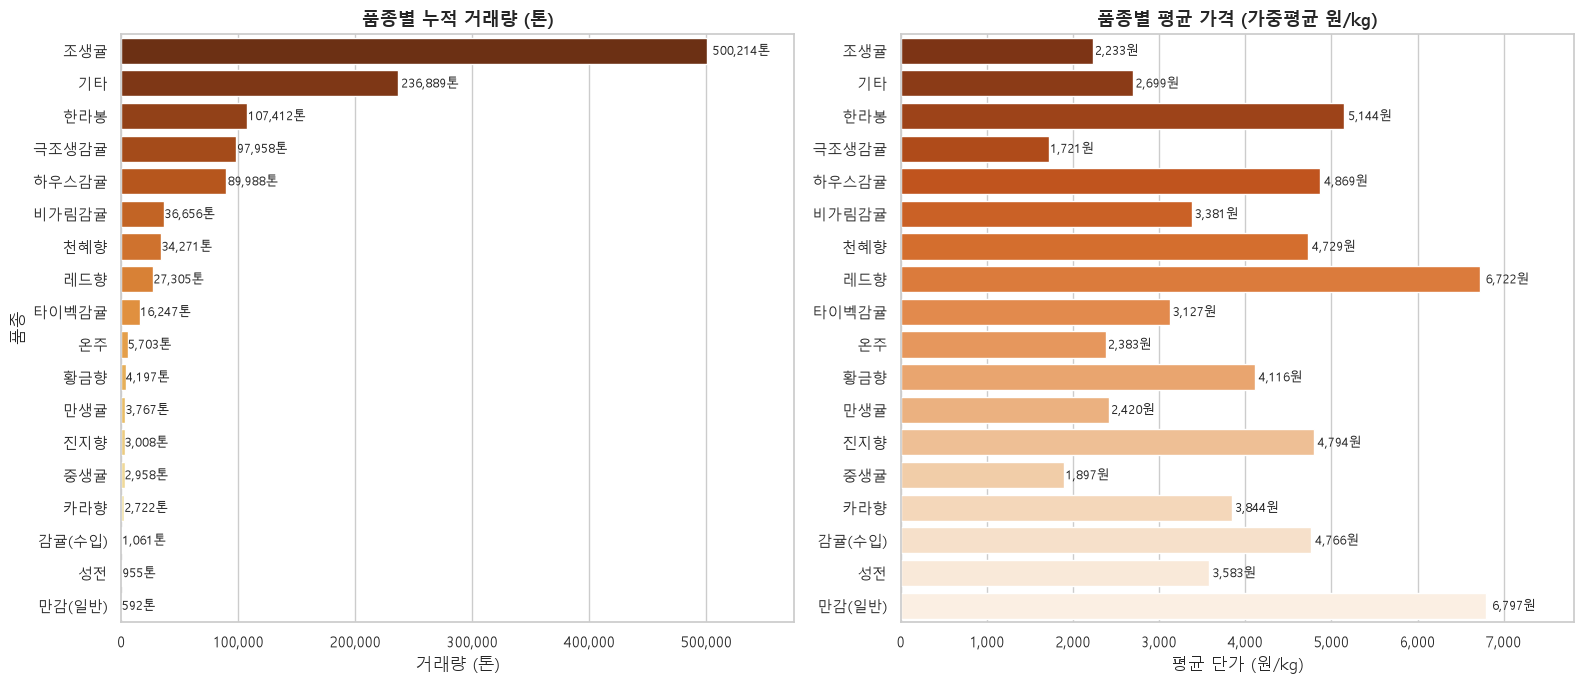

In [14]:
# '감귤(일반)' 및 전체 거래건수 1,000건 미만 소수 품종을 '기타'로 통합
variety_counts = df['variety'].value_counts()
minor_varieties = variety_counts[variety_counts < 1000].index.tolist()
df['variety'] = df['variety'].replace(minor_varieties + ['감귤(일반)'], '기타')

# 품종별 거래량 및 평균가격 집계
variety_stats = (
    df.groupby('variety', as_index=False)
    .agg(
        거래건수=('date', 'count'),
        총거래량_kg=('volume_kg', 'sum'),
        환산상자수=('box_qty', 'sum'),
        총거래금액_원=('total_price', 'sum'),
        산술평균_kg단가=('unit_price_kg', 'mean'),
        평균_상자당가격=('box_price', 'mean')
    )
)

# 파생 지표 계산 (거래건수 비중, 거래량(톤), 물량 비중, 가중평균 kg당 단가, 거래금액(억원))
total_cnt = variety_stats['거래건수'].sum()
total_vol_kg = variety_stats['총거래량_kg'].sum()
variety_stats['거래건수_비중(%)'] = (variety_stats['거래건수'] / total_cnt) * 100
variety_stats['거래량_톤'] = variety_stats['총거래량_kg'] / 1000.0
variety_stats['거래량_비중(%)'] = (variety_stats['총거래량_kg'] / total_vol_kg) * 100
variety_stats['총거래금액_억원'] = variety_stats['총거래금액_원'] / 1e8
variety_stats['가중평균_kg단가'] = variety_stats['총거래금액_원'] / variety_stats['총거래량_kg']

# 거래량 기준 내림차순 정렬
variety_stats = variety_stats.sort_values(by='총거래량_kg', ascending=False).reset_index(drop=True)

# 출력용 포맷팅 테이블 생성
variety_display = pd.DataFrame({
    '품종명': variety_stats['variety'],
    '거래건수': variety_stats['거래건수'].map('{:,.0f} 건'.format),
    '전체 건수비중': variety_stats['거래건수_비중(%)'].map('{:.2f}%'.format),
    '거래량(톤)': variety_stats['거래량_톤'].map('{:,.1f} 톤'.format),
    '거래량 비중': variety_stats['거래량_비중(%)'].map('{:.2f}%'.format),
    '환산상자수': variety_stats['환산상자수'].map('{:,.0f} 상자'.format),
    '총 거래금액(억원)': variety_stats['총거래금액_억원'].map('{:,.1f} 억원'.format),
    '가중평균 단가(원/kg)': variety_stats['가중평균_kg단가'].map('{:,.0f} 원'.format),
    '산술평균 단가(원/kg)': variety_stats['산술평균_kg단가'].map('{:,.0f} 원'.format),
    '평균 상자당 가격(원)': variety_stats['평균_상자당가격'].map('{:,.0f} 원'.format)
})

print(f"취합 후 전체 품종 수: {len(variety_stats)}개 (1,000건 미만 품종 및 '감귤(일반)' -> '기타' 통합 완료)")
display(variety_display)

# 품종별 거래량 및 평균가격 시각화
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1) 품종별 거래량 (톤)
sns.barplot(
    data=variety_stats,
    x='거래량_톤',
    y='variety',
    palette='YlOrBr_r',
    ax=axes[0]
)
axes[0].set_title('품종별 누적 거래량 (톤)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('거래량 (톤)')
axes[0].set_ylabel('품종')
axes[0].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
for bar in axes[0].patches:
    width = bar.get_width()
    axes[0].text(
        width * 1.01,
        bar.get_y() + bar.get_height() / 2,
        f'{width:,.0f}톤',
        va='center',
        fontsize=9
    )
axes[0].margins(x=0.15)

# 2) 품종별 가중평균 kg당 단가 (원/kg)
sns.barplot(
    data=variety_stats,
    x='가중평균_kg단가',
    y='variety',
    palette='Oranges_r',
    ax=axes[1]
)
axes[1].set_title('품종별 평균 가격 (가중평균 원/kg)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('평균 단가 (원/kg)')
axes[1].set_ylabel('')
axes[1].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
for bar in axes[1].patches:
    width = bar.get_width()
    axes[1].text(
        width * 1.01,
        bar.get_y() + bar.get_height() / 2,
        f'{width:,.0f}원',
        va='center',
        fontsize=9
    )
axes[1].margins(x=0.15)

plt.tight_layout()
plt.show()

## 5. 품종별 연도별(2021~2026년) 가격 및 거래량 추이 그래프
- 통합된 18개 품종 각각에 대해 2021년부터 2026년까지 연도별 **거래량(톤, 막대그래프)**과 **가중평균 가격(원/kg, 꺾은선그래프)** 추이를 이중축(Dual-Axis) 그래프로 시각화합니다.

[품종별 연도별 거래량 (단위: 톤)]


year,2021,2022,2023,2024,2025,2026
variety,,,,,,
조생귤,"87,901.5","85,857.2","93,130.7","80,333.4","87,482.6","65,508.8"
기타,"58,525.4","54,312.7","47,353.5","34,940.0","22,366.6","19,390.6"
한라봉,"17,651.5","22,065.2","19,358.7","21,472.2","16,687.8","10,176.5"
극조생감귤,"17,214.1","19,312.2","17,283.9","15,283.0","15,120.6","13,743.8"
하우스감귤,"16,534.1","14,643.2","14,663.9","14,478.3","15,629.0","14,039.0"
비가림감귤,"8,859.9","5,465.5","7,994.3","4,173.1","5,430.8","4,732.2"
천혜향,"2,256.0","2,961.1","3,489.2","2,877.0","8,318.6","14,368.9"
레드향,"2,093.0","3,497.9","3,399.8","4,228.0","6,402.4","7,684.4"
타이벡감귤,0.0,0.0,704.0,"1,780.8","6,353.5","7,409.1"



[품종별 연도별 가중평균 단가 (단위: 원/kg)]


year,2021,2022,2023,2024,2025,2026
variety,,,,,,
조생귤,"1,475","1,712","2,169","2,792","2,876","2,480"
기타,"2,020","2,383","2,715","3,609","3,531","3,001"
한라봉,"5,218","4,869","4,609","6,088","5,449","4,137"
극조생감귤,"1,447","1,484","1,820","1,833","2,041","1,793"
하우스감귤,"3,980","4,772","5,572","4,951","5,079","4,967"
비가림감귤,"2,171","2,854","2,938","4,986","5,043","3,678"
천혜향,"3,797","3,478","3,623","4,228","5,470","5,073"
레드향,"7,362","6,427","6,007","7,469","7,323","6,085"
타이벡감귤,-,-,"2,777","3,364","3,484","2,798"


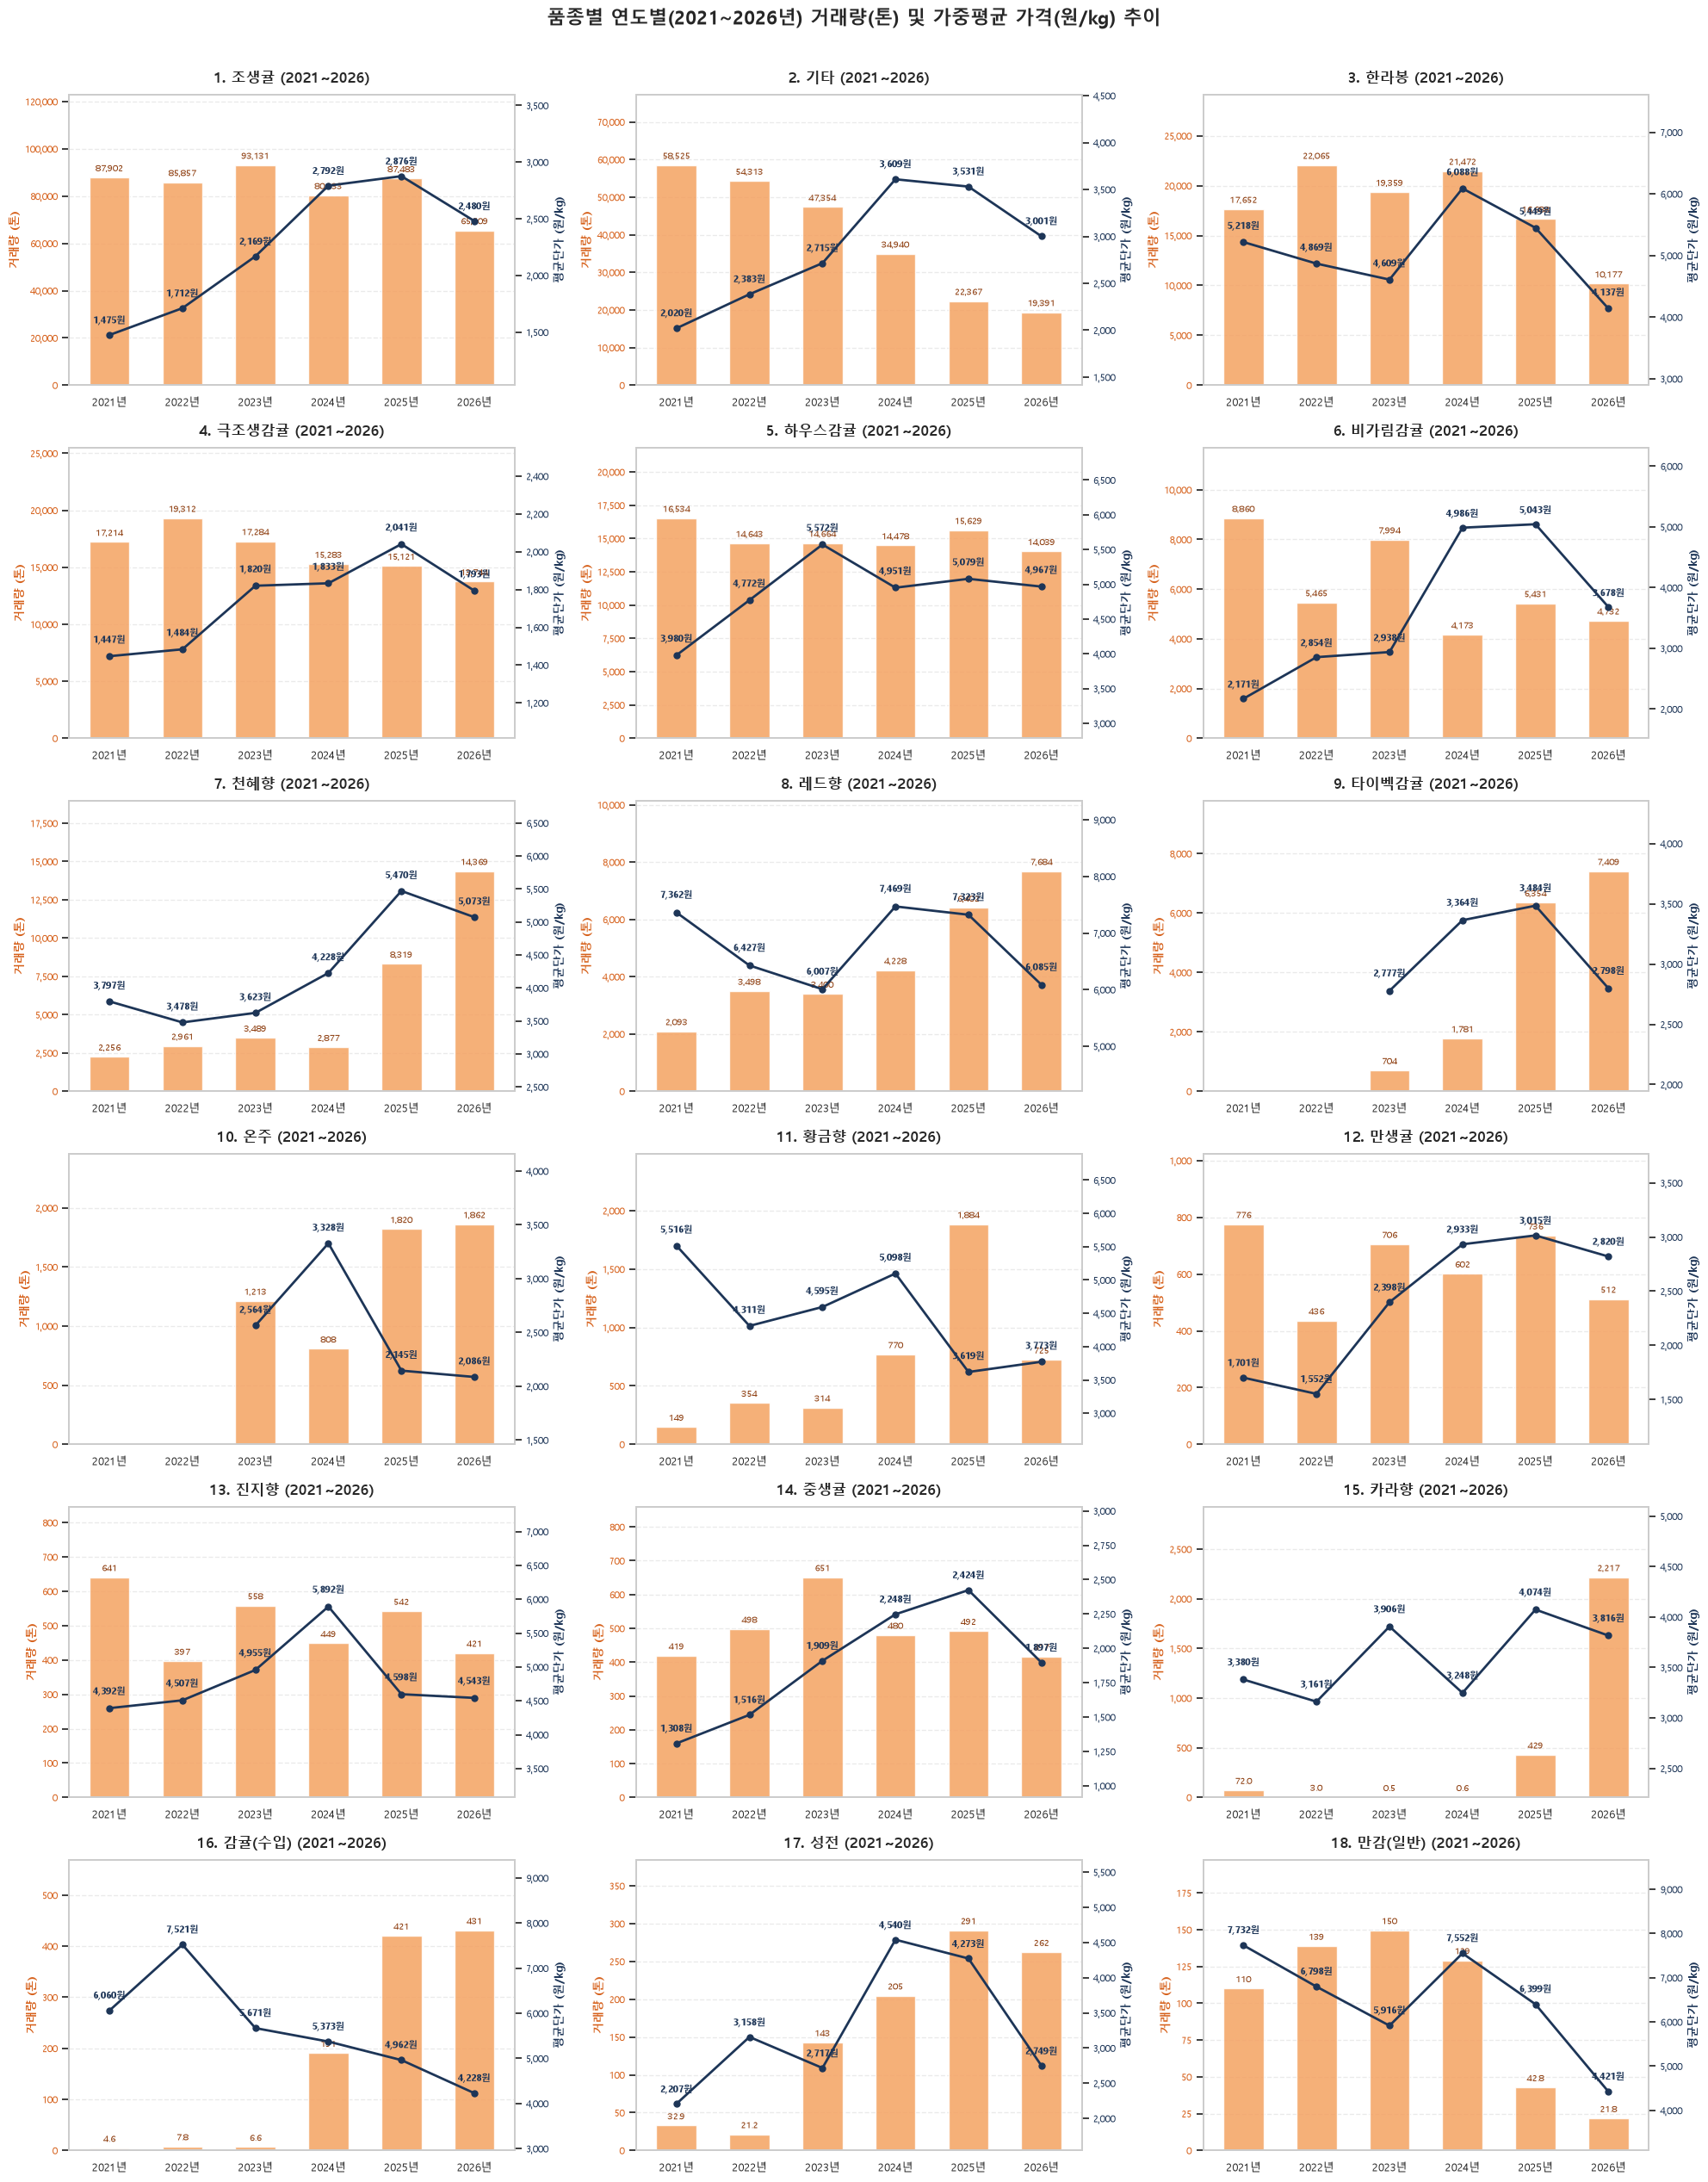

In [15]:
# 1) 2021~2026년 품종별·연도별 거래량 및 평균가격 집계
years = [2021, 2022, 2023, 2024, 2025, 2026]
df_yearly = df[df['year'].isin(years)].copy()

yearly_stats = (
    df_yearly.groupby(['variety', 'year'], as_index=False)
    .agg(
        거래건수=('date', 'count'),
        총거래량_kg=('volume_kg', 'sum'),
        총거래금액_원=('total_price', 'sum'),
        산술평균_kg단가=('unit_price_kg', 'mean'),
        평균_상자당가격=('box_price', 'mean')
    )
)
yearly_stats['거래량_톤'] = yearly_stats['총거래량_kg'] / 1000.0
yearly_stats['가중평균_kg단가'] = np.where(
    yearly_stats['총거래량_kg'] > 0,
    yearly_stats['총거래금액_원'] / yearly_stats['총거래량_kg'],
    np.nan
)

# 품종 순서 (총 거래량 내림차순)
variety_order = variety_stats['variety'].tolist()

# 2) 연도별 거래량(톤) 및 가중평균 단가(원/kg) 요약 피벗 테이블 출력
pivot_vol = (
    yearly_stats.pivot(index='variety', columns='year', values='거래량_톤')
    .reindex(index=variety_order, columns=years)
    .fillna(0.0)
)
pivot_prc = (
    yearly_stats.pivot(index='variety', columns='year', values='가중평균_kg단가')
    .reindex(index=variety_order, columns=years)
)

print("[품종별 연도별 거래량 (단위: 톤)]")
display(pivot_vol.map('{:,.1f}'.format))

print("\n[품종별 연도별 가중평균 단가 (단위: 원/kg)]")
display(pivot_prc.map(lambda v: f"{v:,.0f}" if pd.notnull(v) else "-"))

# 3) 18개 품종별 2021~2026년 거래량(막대) & 평균가격(선) 이중축 그래프
n_Audio = len(variety_order)
ncols = 3
nrows = int(np.ceil(n_Audio / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 4.2))
axes = axes.flatten()

for idx, var_name in enumerate(variety_order):
    ax1 = axes[idx]
    sub = (
        yearly_stats[yearly_stats['variety'] == var_name]
        .set_index('year')
        .reindex(years)
        .reset_index()
    )
    sub['거래량_톤'] = sub['거래량_톤'].fillna(0.0)

    x_pos = np.arange(len(years))
    bars = ax1.bar(x_pos, sub['거래량_톤'], color='#F4A261', alpha=0.85, width=0.55, label='거래량(톤)')
    ax1.set_title(f"{idx + 1}. {var_name} (2021~2026)", fontsize=12, fontweight='bold', pad=10)
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels([f"{y}년" for y in years], fontsize=9)
    ax1.set_ylabel('거래량 (톤)', color='#D6601A', fontsize=9, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='#D6601A', labelsize=8)
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax1.grid(axis='y', linestyle='--', alpha=0.4)
    ax1.grid(axis='x', visible=False)

    max_vol = sub['거래량_톤'].max()
    ax1.set_ylim(0, max_vol * 1.32 if max_vol > 0 else 1)

    for bar in bars:
        h = bar.get_height()
        if h > 0:
            label_str = f"{h:,.0f}" if h >= 100 else f"{h:,.1f}"
            ax1.text(
                bar.get_x() + bar.get_width() / 2,
                h + (max_vol * 0.02),
                label_str,
                ha='center',
                va='bottom',
                fontsize=7.5,
                color='#8C3B0C'
            )

    # 우측 Y축: 가중평균 단가 (원/kg)
    ax2 = ax1.twinx()
    valid_prc = sub['가중평균_kg단가'].dropna()
    ax2.plot(
        x_pos,
        sub['가중평균_kg단가'],
        color='#1D3557',
        marker='o',
        linewidth=2.0,
        markersize=5,
        label='평균단가(원/kg)'
    )
    ax2.set_ylabel('평균단가 (원/kg)', color='#1D3557', fontsize=9, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#1D3557', labelsize=8)
    ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax2.grid(False)

    if len(valid_prc) > 0:
        min_p, max_p = valid_prc.min(), valid_prc.max()
        ax2.set_ylim(max(0, min_p * 0.7), max_p * 1.25)
        for xi, p_val in zip(x_pos, sub['가중평균_kg단가']):
            if pd.notnull(p_val):
                ax2.text(
                    xi,
                    p_val + (max_p * 0.03),
                    f"{p_val:,.0f}원",
                    ha='center',
                    va='bottom',
                    fontsize=8,
                    fontweight='bold',
                    color='#1D3557'
                )

# 남는 서브플롯 숨김 처리
for j in range(len(variety_order), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('품종별 연도별(2021~2026년) 거래량(톤) 및 가중평균 가격(원/kg) 추이', fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

## 6. 품종별 월별(2021.01 ~ 2026.11) 거래량 및 가격 추이 분석
- 2021년 1월부터 2026년 11월까지 **월별(`year_month`) 거래량(톤)**과 **월별 가중평균 단가(원/kg)**의 시계열 추이를 품종별로 분석하고 시각화합니다.
- 막대(면) 영역은 월별 거래량(좌측 축)을, 꺾은선은 월별 가중평균 가격(우측 축)을 나타내며, 연도 구분선(점선)을 통해 품종별 출하 계절성(Seasonality)과 가격 변동을 함께 확인할 수 있습니다.

[품종별 월별(2021.01~2026.11) 거래량 및 가격 추이 핵심 요약]


,품종명,거래 발생 월수,주요 집중 출하월(Top 3),월 최대 거래량(연월),월 최고 평균단가(연월),월 최저 평균단가(연월)
0,조생귤,71 / 71개월,"12월, 1월, 11월","38,671.2톤 (2025-12)","9,212원 (2023-05)","1,394원 (2021-01)"
1,기타,71 / 71개월,"1월, 12월, 11월","17,853.1톤 (2022-01)","6,928원 (2023-06)","1,618원 (2021-10)"
2,한라봉,66 / 71개월,"1월, 2월, 3월","9,067.0톤 (2022-01)","7,422원 (2021-06)","1,031원 (2021-07)"
3,극조생감귤,33 / 71개월,"10월, 11월, 9월","12,989.5톤 (2023-10)","8,000원 (2026-06)","1,025원 (2022-12)"
4,하우스감귤,71 / 71개월,"9월, 10월, 8월","4,754.8톤 (2021-09)","10,778원 (2026-05)","1,880원 (2021-12)"
5,비가림감귤,59 / 71개월,"2월, 3월, 1월","4,121.4톤 (2023-02)","12,000원 (2024-06)","1,725원 (2022-06)"
6,천혜향,70 / 71개월,"2월, 3월, 1월","5,954.2톤 (2026-02)","16,667원 (2023-07)","1,295원 (2026-11)"
7,레드향,38 / 71개월,"1월, 2월, 12월","4,516.6톤 (2026-02)","11,655원 (2025-11)","3,277원 (2025-05)"
8,타이벡감귤,25 / 71개월,"1월, 12월, 11월","3,322.5톤 (2026-01)","5,689원 (2025-05)","2,118원 (2026-11)"
9,온주,32 / 71개월,"10월, 11월, 12월","1,056.2톤 (2026-10)","10,000원 (2025-07)","1,175원 (2025-02)"


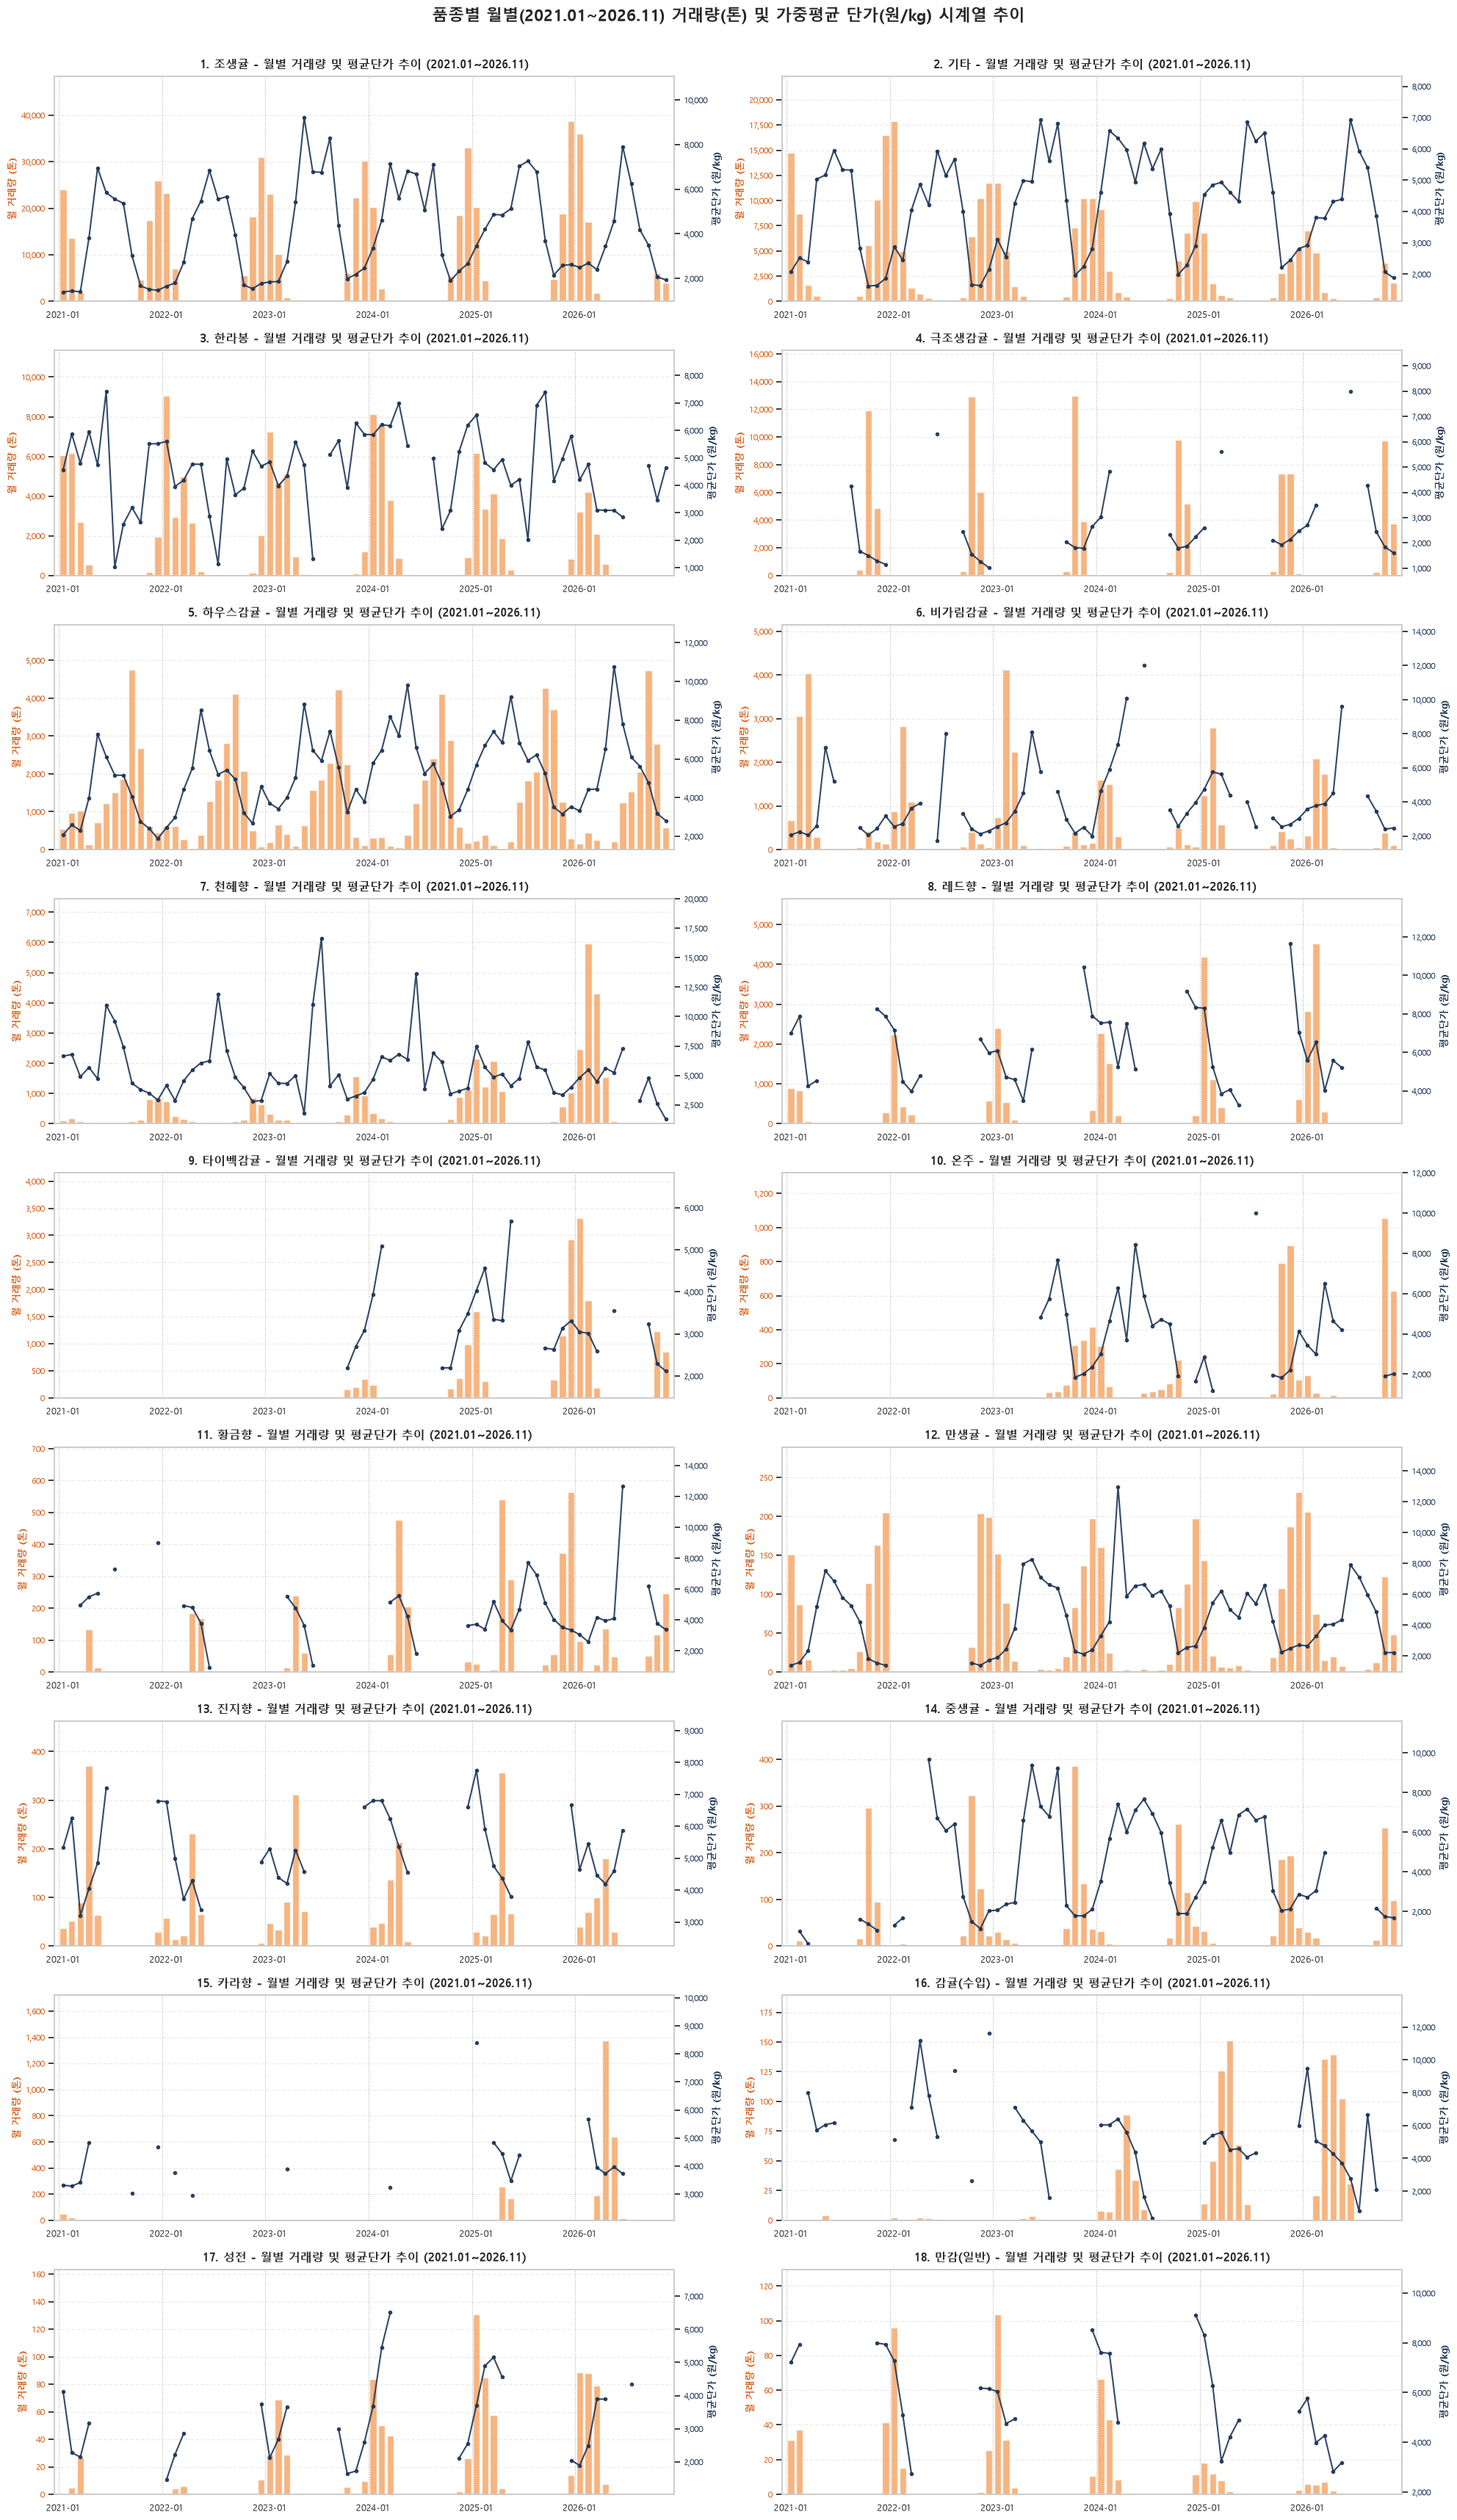

In [16]:
# 1) 2021-01 ~ 2026-11 전체 월별 타임라인 생성 및 품종별·월별 집계
all_months = pd.period_range(
    start='2021-01',
    end=df['date'].max().to_period('M'),
    freq='M'
).astype(str).tolist()

monthly_stats = (
    df[df['year'] >= 2021]
    .groupby(['variety', 'year_month'], as_index=False)
    .agg(
        거래건수=('date', 'count'),
        총거래량_kg=('volume_kg', 'sum'),
        총거래금액_원=('total_price', 'sum'),
        산술평균_kg단가=('unit_price_kg', 'mean'),
        평균_상자당가격=('box_price', 'mean')
    )
)
monthly_stats['거래량_톤'] = monthly_stats['총거래량_kg'] / 1000.0
monthly_stats['가중평균_kg단가'] = np.where(
    monthly_stats['총거래량_kg'] > 0,
    monthly_stats['총거래금액_원'] / monthly_stats['총거래량_kg'],
    np.nan
)

# 2) 품종별 월별 추이 핵심 요약 테이블 (최대 거래월, 최고/최저 단가월 등)
monthly_summary_rows = []
for var_name in variety_order:
    sub_m = monthly_stats[monthly_stats['variety'] == var_name].copy()
    if len(sub_m) == 0:
        continue
    max_vol_row = sub_m.loc[sub_m['거래량_톤'].idxmax()]
    max_prc_row = sub_m.loc[sub_m['가중평균_kg단가'].idxmax()]
    min_prc_row = sub_m.loc[sub_m['가중평균_kg단가'].idxmin()]

    # 연중 주 출하월 (월별 합계 상위 3개 월)
    sub_m['month_num'] = sub_m['year_month'].str.slice(5, 7).astype(int)
    top_months = (
        sub_m.groupby('month_num')['거래량_톤'].sum()
        .sort_values(ascending=False)
        .head(3).index.tolist()
    )
    top_months_str = ", ".join([f"{m}월" for m in top_months])

    monthly_summary_rows.append({
        '품종명': var_name,
        '거래 발생 월수': f"{len(sub_m)} / {len(all_months)}개월",
        '주요 집중 출하월(Top 3)': top_months_str,
        '월 최대 거래량(연월)': f"{max_vol_row['거래량_톤']:,.1f}톤 ({max_vol_row['year_month']})",
        '월 최고 평균단가(연월)': f"{max_prc_row['가중평균_kg단가']:,.0f}원 ({max_prc_row['year_month']})",
        '월 최저 평균단가(연월)': f"{min_prc_row['가중평균_kg단가']:,.0f}원 ({min_prc_row['year_month']})"
    })

monthly_summary_df = pd.DataFrame(monthly_summary_rows)
print("[품종별 월별(2021.01~2026.11) 거래량 및 가격 추이 핵심 요약]")
display(monthly_summary_df)

# 3) 18개 품종별 월별 거래량(막대) 및 가중평균 단가(선) 시계열 추이 그래프 (9행 x 2열)
ncols_m = 2
nrows_m = int(np.ceil(len(variety_order) / ncols_m))
fig, axes = plt.subplots(nrows_m, ncols_m, figsize=(20, nrows_m * 3.8))
axes = axes.flatten()

x_idx = np.arange(len(all_months))
jan_indices = [i for i, ym in enumerate(all_months) if ym.endswith('-01')]
jan_labels = [all_months[i] for i in jan_indices]

for idx, var_name in enumerate(variety_order):
    ax1 = axes[idx]
    sub_m = (
        monthly_stats[monthly_stats['variety'] == var_name]
        .set_index('year_month')
        .reindex(all_months)
        .reset_index()
    )
    sub_m['거래량_톤'] = sub_m['거래량_톤'].fillna(0.0)

    # 좌측 Y축: 월별 거래량 (톤)
    ax1.bar(x_idx, sub_m['거래량_톤'], color='#F4A261', alpha=0.8, width=0.8, label='월별 거래량(톤)')
    ax1.set_title(f"{idx + 1}. {var_name} - 월별 거래량 및 평균단가 추이 (2021.01~2026.11)", fontsize=11.5, fontweight='bold', pad=8)
    ax1.set_xticks(jan_indices)
    ax1.set_xticklabels(jan_labels, fontsize=8.5)
    ax1.set_xlim(-1, len(all_months))
    ax1.set_ylabel('월 거래량 (톤)', color='#D6601A', fontsize=9, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='#D6601A', labelsize=8)
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax1.grid(axis='y', linestyle='--', alpha=0.35)
    ax1.grid(axis='x', visible=False)

    # 연도 경계선 표시
    for j_idx in jan_indices:
        ax1.axvline(j_idx - 0.5, color='gray', linestyle=':', linewidth=0.8, alpha=0.6)

    max_v = sub_m['거래량_톤'].max()
    ax1.set_ylim(0, max_v * 1.25 if max_v > 0 else 1)

    # 우측 Y축: 월별 가중평균 단가 (원/kg)
    ax2 = ax1.twinx()
    ax2.plot(
        x_idx,
        sub_m['가중평균_kg단가'],
        color='#1D3557',
        marker='o',
         markersize=3.0,
        linewidth=1.5,
        alpha=0.9,
        label='월 가중평균 단가(원/kg)'
    )
    ax2.set_ylabel('평균단가 (원/kg)', color='#1D3557', fontsize=9, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#1D3557', labelsize=8)
    ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax2.grid(False)

    valid_p = sub_m['가중평균_kg단가'].dropna()
    if len(valid_p) > 0:
        ax2.set_ylim(max(0, valid_p.min() * 0.7), valid_p.max() * 1.2)

for j in range(len(variety_order), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('품종별 월별(2021.01~2026.11) 거래량(톤) 및 가중평균 단가(원/kg) 시계열 추이', fontsize=16, fontweight='bold', y=1.003)
plt.tight_layout()
plt.show()

## 7. 품종별 상위 최대 5개 거래단위(거래건수 1,000건 이상) 정리 및 시각화
- `'3kg상자'`+`'3kg파렛트'` $\rightarrow$ **`'3kg상자'`**, `'5kg상자'`+`'5kg파렛트'` $\rightarrow$ **`'5kg상자'`**, `'9kg상자'`+`'9kg파렛트'` $\rightarrow$ **`'9kg상자'`**, `'10kg상자'`+`'10kg파렛트'` $\rightarrow$ **`'10kg상자'`**로 통합합니다.
- 각 품종(`variety`)별로 통합된 거래단위(`box_unit`) 기준 **거래건수가 1,000건 이상**인 규격만 필터링한 뒤, 품종별 **상위 최대 5개 거래단위**의 거래건수, 전체/품종내 비중(%), 거래량(톤), 평균 상자당 가격(원/상자), 가중평균 단가(원/kg)를 정리하고 시각화합니다.

[품종별 상위 최대 5개 거래단위 요약 (거래건수 1,000건 이상 & 품종내 비중 1% 이상, 총 48개 행)]


,품종명,순위,거래단위,거래건수,전체 건수비중,품종내 건수비중,거래량(톤),전체 물량비중,품종내 물량비중,환산상자수,총 거래금액(억원),평균 상자당 가격,가중평균 단가(원/kg)
0,조생귤,1위,5kg상자,"274,198 건",15.92%,86.6%,"467,094.8 톤",39.86%,93.4%,"93,418,970 상자","10,386.9 억원","10,155 원","2,224 원"
1,조생귤,2위,10kg상자,"19,545 건",1.13%,6.2%,"15,558.1 톤",1.33%,3.1%,"1,555,810 상자",195.5 억원,"13,560 원","1,257 원"
2,조생귤,3위,3kg상자,"12,330 건",0.72%,3.9%,"5,983.6 톤",0.51%,1.2%,"1,994,522 상자",290.2 억원,"15,788 원","4,850 원"
3,기타,1위,5kg상자,"166,430 건",9.66%,52.5%,"199,782.8 톤",17.05%,84.3%,"39,956,561 상자","4,560.4 억원","14,582 원","2,283 원"
4,기타,2위,3kg상자,"95,152 건",5.52%,30.0%,"17,767.2 톤",1.52%,7.5%,"5,922,390 상자","1,095.6 억원","17,910 원","6,166 원"
5,기타,3위,10kg상자,"21,960 건",1.27%,6.9%,"9,467.2 톤",0.81%,4.0%,"946,717 상자",246.3 억원,"30,406 원","2,602 원"
6,기타,4위,9kg상자,"20,149 건",1.17%,6.4%,"5,334.5 톤",0.46%,2.3%,"592,723 상자",287.9 억원,"45,048 원","5,396 원"
7,한라봉,1위,3kg상자,"133,080 건",7.73%,40.5%,"33,742.4 톤",2.88%,31.4%,"11,247,459 상자","1,952.3 억원","16,495 원","5,786 원"
8,한라봉,2위,9kg상자,"77,619 건",4.51%,23.6%,"32,734.2 톤",2.79%,30.5%,"3,637,131 상자","1,525.0 억원","37,441 원","4,659 원"
9,한라봉,3위,5kg상자,"62,693 건",3.64%,19.1%,"17,949.5 톤",1.53%,16.7%,"3,589,903 상자","1,075.0 억원","28,674 원","5,989 원"



[품종별 상위 1~5위 거래단위 한눈에 보기 (품종내 1% 이상)]


,품종명,대상 규격 수,1위 거래단위 (건수 / 품종내비중 / 물량 / 평균가),2위 거래단위 (건수 / 품종내비중 / 물량 / 평균가),3위 거래단위 (건수 / 품종내비중 / 물량 / 평균가),4위 거래단위 (건수 / 품종내비중 / 물량 / 평균가),5위 거래단위 (건수 / 품종내비중 / 물량 / 평균가)
0,조생귤,3개,"5kg상자 (274,198건, 품종내 86.6% | 467,094.8톤, 상자당 1...","10kg상자 (19,545건, 품종내 6.2% | 15,558.1톤, 상자당 13,...","3kg상자 (12,330건, 품종내 3.9% | 5,983.6톤, 상자당 15,78...",-,-
1,기타,4개,"5kg상자 (166,430건, 품종내 52.5% | 199,782.8톤, 상자당 1...","3kg상자 (95,152건, 품종내 30.0% | 17,767.2톤, 상자당 17,...","10kg상자 (21,960건, 품종내 6.9% | 9,467.2톤, 상자당 30,4...","9kg상자 (20,149건, 품종내 6.4% | 5,334.5톤, 상자당 45,04...",-
2,한라봉,4개,"3kg상자 (133,080건, 품종내 40.5% | 33,742.4톤, 상자당 16...","9kg상자 (77,619건, 품종내 23.6% | 32,734.2톤, 상자당 37,...","5kg상자 (62,693건, 품종내 19.1% | 17,949.5톤, 상자당 28,...","10kg상자 (44,532건, 품종내 13.6% | 20,260.0톤, 상자당 36...",-
3,극조생감귤,3개,"5kg상자 (85,192건, 품종내 92.1% | 91,995.6톤, 상자당 7,8...","10kg상자 (3,515건, 품종내 3.8% | 2,144.0톤, 상자당 9,765...","3kg상자 (1,197건, 품종내 1.3% | 564.8톤, 상자당 9,755원 |...",-,-
4,하우스감귤,5개,"3kg상자 (160,819건, 품종내 49.9% | 39,168.1톤, 상자당 18...","5kg상자 (86,257건, 품종내 26.8% | 30,253.0톤, 상자당 16,...","0.5kg상자 (27,893건, 품종내 8.7% | 5,329.5톤, 상자당 2,8...","6kg상자 (11,677건, 품종내 3.6% | 4,349.5톤, 상자당 34,19...","10kg상자 (10,885건, 품종내 3.4% | 3,436.5톤, 상자당 50,0..."
5,비가림감귤,3개,"5kg상자 (50,989건, 품종내 80.7% | 32,764.8톤, 상자당 14,...","3kg상자 (5,270건, 품종내 8.3% | 1,729.3톤, 상자당 15,293...","10kg상자 (2,248건, 품종내 3.6% | 843.7톤, 상자당 22,114원...",-,-
6,천혜향,4개,"3kg상자 (53,078건, 품종내 49.2% | 12,015.5톤, 상자당 14,...","9kg상자 (22,418건, 품종내 20.8% | 10,129.3톤, 상자당 40,...","5kg상자 (21,228건, 품종내 19.7% | 7,934.2톤, 상자당 20,5...","10kg상자 (5,125건, 품종내 4.7% | 2,484.9톤, 상자당 38,32...",-
7,레드향,5개,"3kg상자 (44,619건, 품종내 49.5% | 12,099.5톤, 상자당 19,...","5kg상자 (28,209건, 품종내 31.3% | 8,954.7톤, 상자당 33,4...","9kg상자 (10,147건, 품종내 11.2% | 3,501.3톤, 상자당 42,5...","10kg상자 (4,291건, 품종내 4.8% | 1,898.2톤, 상자당 42,47...","4.5kg상자 (1,211건, 품종내 1.3% | 403.8톤, 상자당 34,665..."
8,타이벡감귤,1개,"5kg상자 (17,320건, 품종내 87.9% | 15,217.0톤, 상자당 14,...",-,-,-,-
9,온주,1개,"5kg상자 (2,382건, 품종내 72.0% | 5,310.3톤, 상자당 11,72...",-,-,-,-


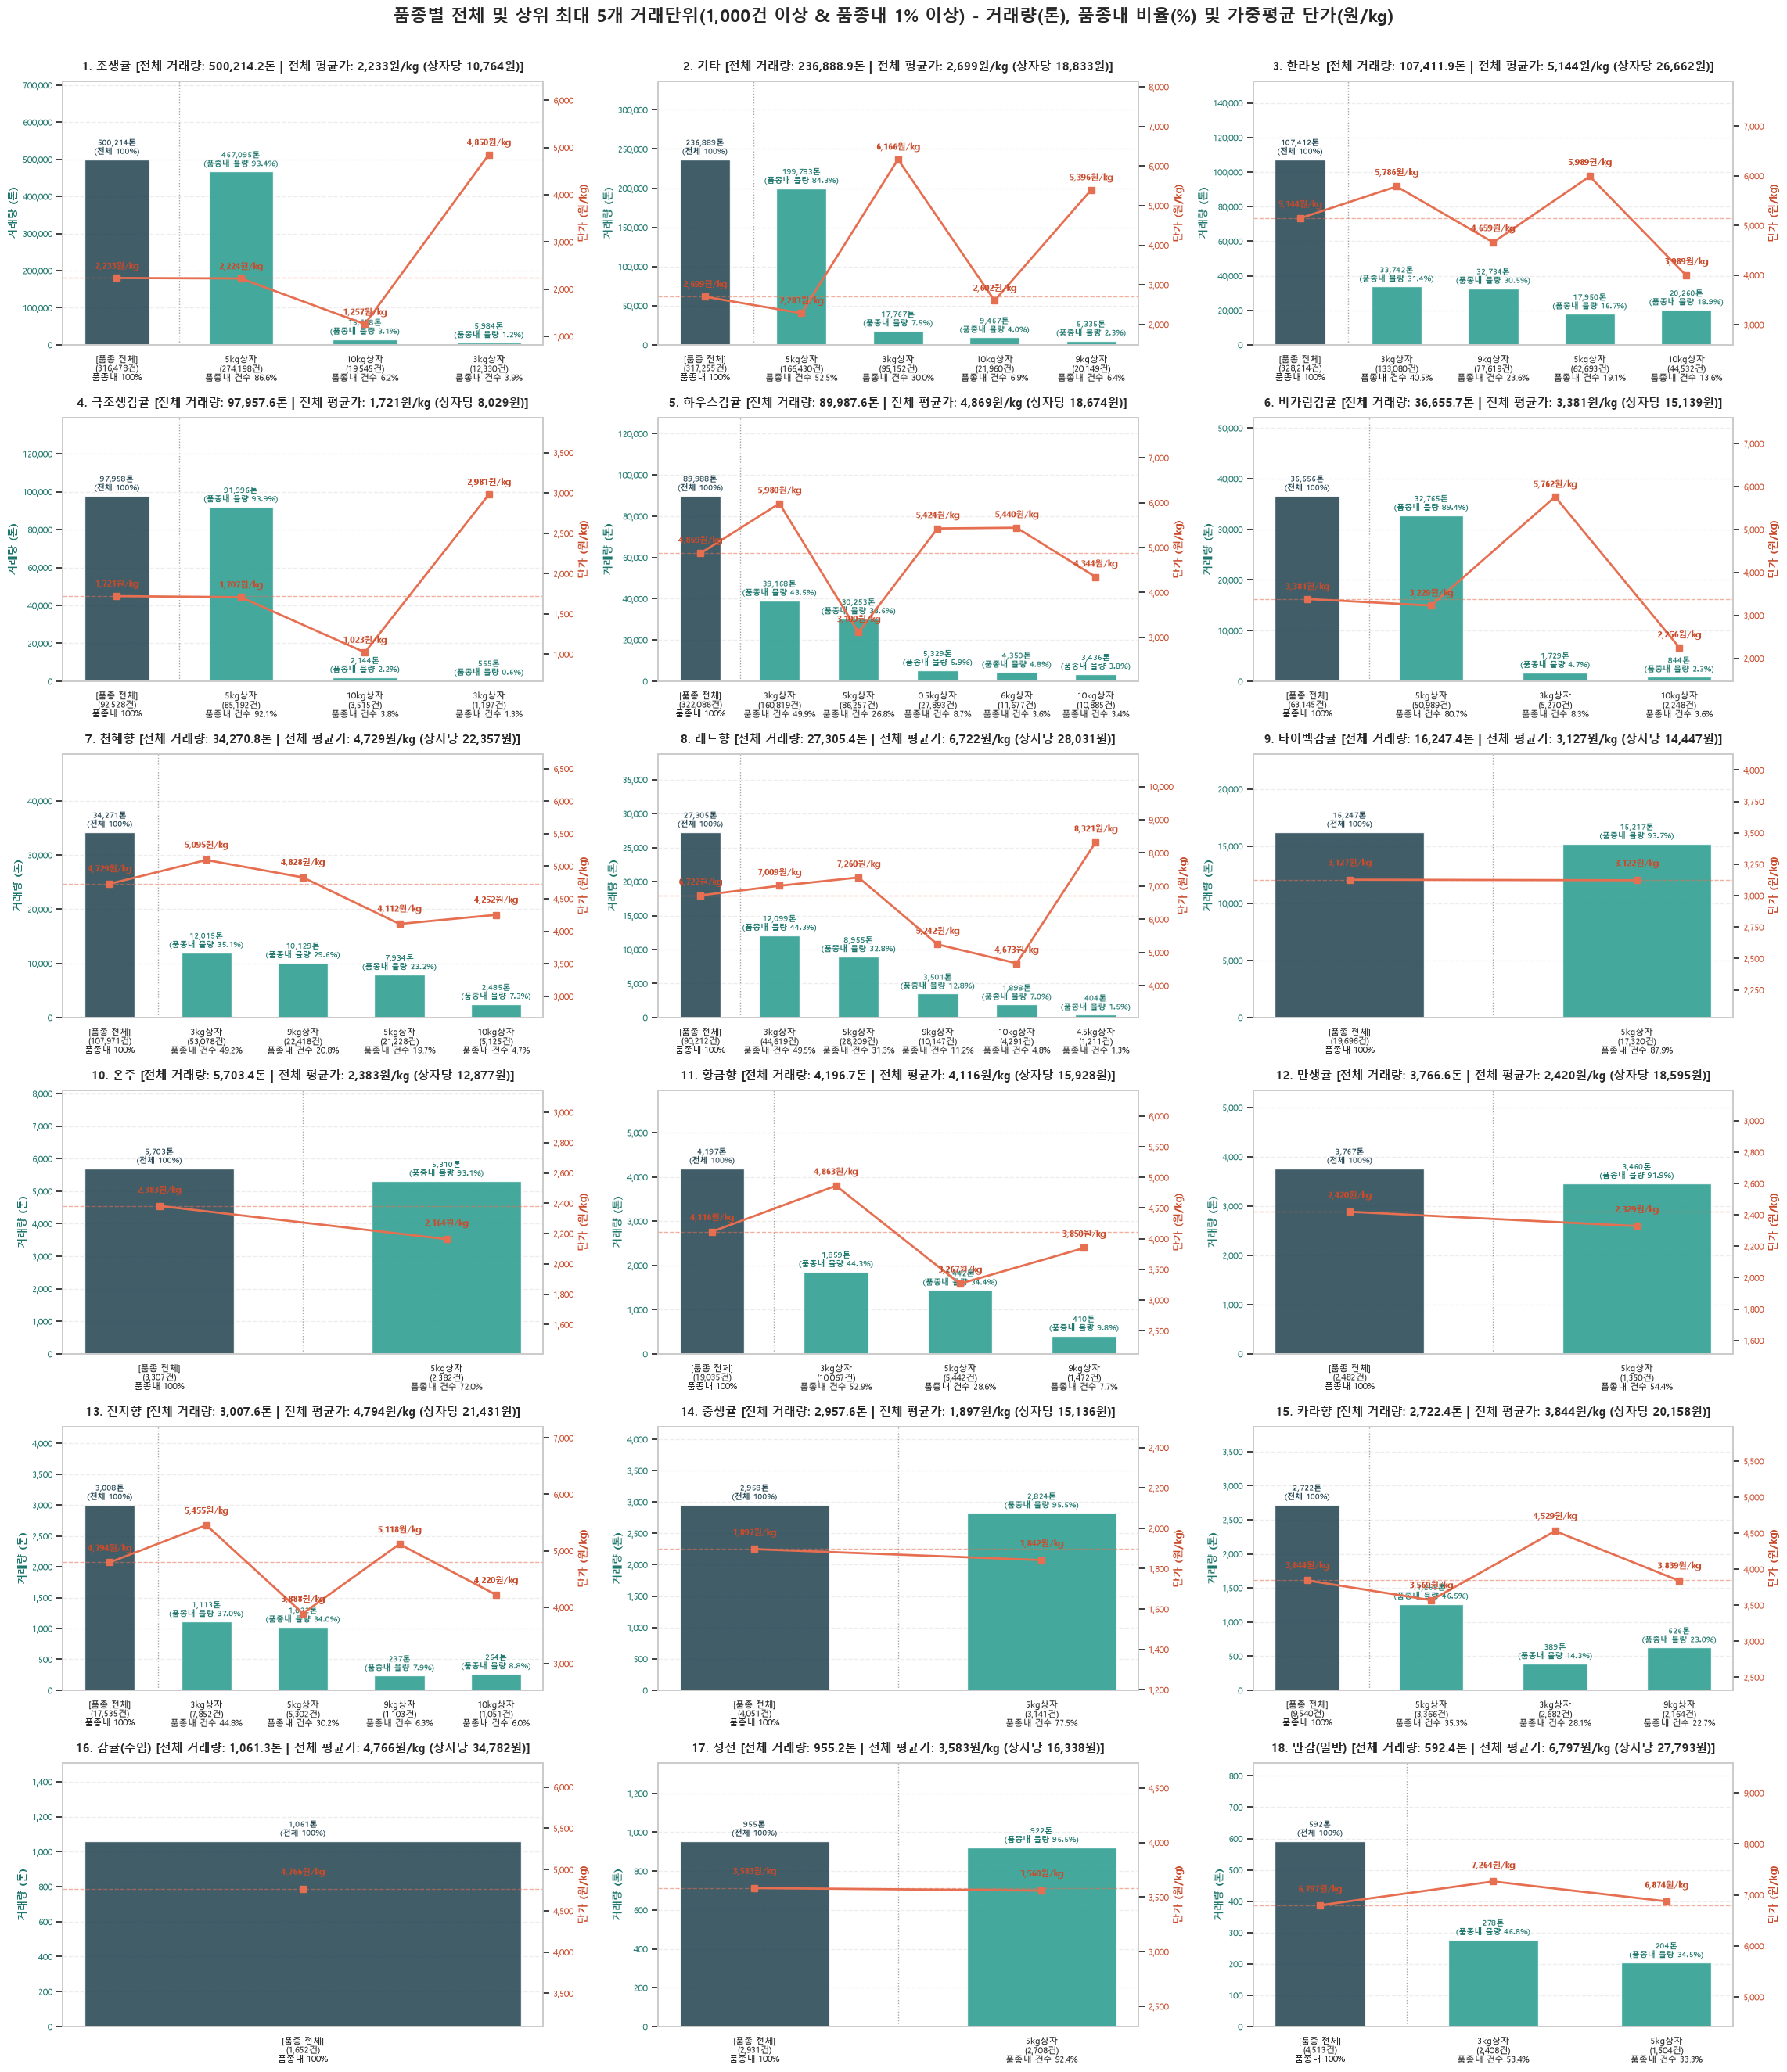

In [17]:
# 1) 3kg/5kg/9kg/10kg 파렛트 -> 상자 통합 후 품종별 · 거래단위(box_unit)별 거래 현황 집계
df['box_unit'] = df['box_unit'].replace({
    '3kg파렛트': '3kg상자',
    '5kg파렛트': '5kg상자',
    '9kg파렛트': '9kg상자',
    '10kg파렛트': '10kg상자'
})

unit_stats = (
    df.groupby(['variety', 'box_unit'], as_index=False)
    .agg(
        거래건수=('date', 'count'),
        총거래량_kg=('volume_kg', 'sum'),
        환산상자수=('box_qty', 'sum'),
        총거래금액_원=('total_price', 'sum'),
        평균_상자당가격=('box_price', 'mean'),
        산술평균_kg단가=('unit_price_kg', 'mean')
    )
)

# 품종별 전체 거래량 및 거래건수 결합 (품종 내 비중 산출용)
variety_totals = (
    df.groupby('variety', as_index=False)
    .agg(품종총거래건수=('date', 'count'), 품종총거래량_kg=('volume_kg', 'sum'))
)
unit_stats = unit_stats.merge(variety_totals, on='variety', how='left')

total_all_cnt = len(df)
total_all_vol_kg = df['volume_kg'].sum()
unit_stats['거래량_톤'] = unit_stats['총거래량_kg'] / 1000.0
unit_stats['전체_건수비중(%)'] = (unit_stats['거래건수'] / total_all_cnt) * 100
unit_stats['품종내_건수비중(%)'] = (unit_stats['거래건수'] / unit_stats['품종총거래건수']) * 100
unit_stats['전체_물량비중(%)'] = (unit_stats['총거래량_kg'] / total_all_vol_kg) * 100
unit_stats['품종내_물량비중(%)'] = (unit_stats['총거래량_kg'] / unit_stats['품종총거래량_kg']) * 100
unit_stats['총거래금액_억원'] = unit_stats['총거래금액_원'] / 1e8
unit_stats['가중평균_kg단가'] = unit_stats['총거래금액_원'] / unit_stats['총거래량_kg']

# 2) 각 거래단위의 거래건수가 1,000건 이상이고 품종내 건수비중이 1% 이상인 항목 필터링 후 품종별 상위 최대 5개 추출
unit_filtered = unit_stats[(unit_stats['거래건수'] >= 1000) & (unit_stats['품종내_건수비중(%)'] >= 1.0)].copy()

# 품종 순서는 전체 거래량 순(variety_order), 품종 내에서는 거래건수 내림차순 정렬
unit_filtered['variety_rank'] = unit_filtered['variety'].map({v: i for i, v in enumerate(variety_order)})
unit_filtered = unit_filtered.sort_values(by=['variety_rank', '거래건수'], ascending=[True, False])

top5_units_per_variety = (
    unit_filtered.groupby('variety', as_index=False, sort=False)
    .head(5)
    .reset_index(drop=True)
)
top5_units_per_variety['품종내_순위'] = top5_units_per_variety.groupby('variety').cumcount() + 1

# 3) 출력용 포맷팅 테이블 생성
unit_display = pd.DataFrame({
    '품종명': top5_units_per_variety['variety'],
    '순위': top5_units_per_variety['품종내_순위'].map('{:.0f}위'.format),
    '거래단위': top5_units_per_variety['box_unit'],
    '거래건수': top5_units_per_variety['거래건수'].map('{:,.0f} 건'.format),
    '전체 건수비중': top5_units_per_variety['전체_건수비중(%)'].map('{:.2f}%'.format),
    '품종내 건수비중': top5_units_per_variety['품종내_건수비중(%)'].map('{:.1f}%'.format),
    '거래량(톤)': top5_units_per_variety['거래량_톤'].map('{:,.1f} 톤'.format),
    '전체 물량비중': top5_units_per_variety['전체_물량비중(%)'].map('{:.2f}%'.format),
    '품종내 물량비중': top5_units_per_variety['품종내_물량비중(%)'].map('{:.1f}%'.format),
    '환산상자수': top5_units_per_variety['환산상자수'].map('{:,.0f} 상자'.format),
    '총 거래금액(억원)': top5_units_per_variety['총거래금액_억원'].map('{:,.1f} 억원'.format),
    '평균 상자당 가격': top5_units_per_variety['평균_상자당가격'].map('{:,.0f} 원'.format),
    '가중평균 단가(원/kg)': top5_units_per_variety['가중평균_kg단가'].map('{:,.0f} 원'.format)
})

print(f"[품종별 상위 최대 5개 거래단위 요약 (거래건수 1,000건 이상 & 품종내 비중 1% 이상, 총 {len(unit_display)}개 행)]")
display(unit_display)

# 4) 품종별 상위 거래단위 가로 요약표 (1위 ~ 5위 한눈에 보기)
wide_rows = []
for var_name in variety_order:
    sub_u = top5_units_per_variety[top5_units_per_variety['variety'] == var_name]
    row_dict = {'품종명': var_name, '대상 규격 수': f"{len(sub_u)}개"}
    for r in range(1, 6):
        match = sub_u[sub_u['품종내_순위'] == r]
        if len(match) > 0:
            m = match.iloc[0]
            row_dict[f'{r}위 거래단위 (건수 / 품종내비중 / 물량 / 평균가)'] = (
                f"{m['box_unit']} ({m['거래건수']:,.0f}건, 품종내 {m['품종내_건수비중(%)']:.1f}% | "
                f"{m['거래량_톤']:,.1f}톤, 상자당 {m['평균_상자당가격']:,.0f}원 | {m['가중평균_kg단가']:,.0f}원/kg)"
            )
        else:
            row_dict[f'{r}위 거래단위 (건수 / 품종내비중 / 물량 / 평균가)'] = "-"
    wide_rows.append(row_dict)

wide_unit_df = pd.DataFrame(wide_rows)
print("\n[품종별 상위 1~5위 거래단위 한눈에 보기 (품종내 1% 이상)]")
display(wide_unit_df)

# 5) 품종별 전체 및 상위 거래단위(품종내 1% 이상) 거래량, 품종내 비율(%) 및 가중평균 단가 시각화 (6행 x 3열)
ncols_u = 3
nrows_u = int(np.ceil(len(variety_order) / ncols_u))
fig, axes = plt.subplots(nrows_u, ncols_u, figsize=(23, nrows_u * 4.4))
axes = axes.flatten()

variety_meta = variety_stats.set_index('variety').to_dict(orient='index')

for idx, var_name in enumerate(variety_order):
    ax1 = axes[idx]
    v_info = variety_meta[var_name]
    sub_u = top5_units_per_variety[top5_units_per_variety['variety'] == var_name].copy()

    # 품종 전체 행(맨 앞 막대) + 상위 거래단위 결합
    total_row = pd.DataFrame([{
        'variety': var_name,
        'box_unit': '품종 전체',
        '거래건수': v_info['거래건수'],
        '거래량_톤': v_info['거래량_톤'],
        '품종내_건수비중(%)': 100.0,
        '품종내_물량비중(%)': 100.0,
        '가중평균_kg단가': v_info['가중평균_kg단가'],
        '평균_상자당가격': v_info['평균_상자당가격']
    }])
    plot_df = pd.concat([total_row, sub_u[total_row.columns]], ignore_index=True)

    x_pos = np.arange(len(plot_df))
    bar_colors = ['#264653'] + ['#2A9D8F'] * (len(plot_df) - 1)
    bars = ax1.bar(x_pos, plot_df['거래량_톤'], color=bar_colors, alpha=0.88, width=0.52)

    ax1.set_title(
        f"{idx + 1}. {var_name} [전체 거래량: {v_info['거래량_톤']:,.1f}톤 | 전체 평균가: {v_info['가중평균_kg단가']:,.0f}원/kg (상자당 {v_info['평균_상자당가격']:,.0f}원)]",
        fontsize=10.5,
        fontweight='bold',
        pad=10
    )
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(
        [
            f"[품종 전체]\n({row['거래건수']:,.0f}건)\n품종내 100%" if i == 0 else
            f"{row['box_unit']}\n({row['거래건수']:,.0f}건)\n품종내 건수 {row['품종내_건수비중(%)']:.1f}%"
            for i, (_, row) in enumerate(plot_df.iterrows())
        ],
        fontsize=8.2
    )
    ax1.set_ylabel('거래량 (톤)', color='#1F776D', fontsize=9, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='#1F776D', labelsize=8)
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax1.grid(axis='y', linestyle='--', alpha=0.35)
    ax1.grid(axis='x', visible=False)

    # 품종 전체와 개별 거래단위 구분선
    if len(plot_df) > 1:
        ax1.axvline(0.5, color='gray', linestyle=':', linewidth=1.0, alpha=0.7)

    max_v = plot_df['거래량_톤'].max()
    ax1.set_ylim(0, max_v * 1.42 if max_v > 0 else 1)
    for i, (bar, (_, row)) in enumerate(zip(bars, plot_df.iterrows())):
        h = bar.get_height()
        if h > 0:
            vol_str = f"{h:,.0f}톤" if h >= 100 else f"{h:,.1f}톤"
            pct_str = "(전체 100%)" if i == 0 else f"(품종내 물량 {row['품종내_물량비중(%)']:.1f}%)"
            ax1.text(
                bar.get_x() + bar.get_width() / 2,
                h + (max_v * 0.02),
                f"{vol_str}\n{pct_str}",
                ha='center',
                va='bottom',
                fontsize=7.5,
                fontweight='bold',
                color='#264653' if i == 0 else '#1F776D'
            )

    # 우측 Y축: 가중평균 단가 (원/kg)
    ax2 = ax1.twinx()
    ax2.axhline(v_info['가중평균_kg단가'], color='#E76F51', linestyle='--', linewidth=1.0, alpha=0.55)
    ax2.plot(
        x_pos,
        plot_df['가중평균_kg단가'],
        color='#E76F51',
        marker='s',
        linewidth=2.0,
        markersize=5.5,
        label='가중평균 단가(원/kg)'
    )
    ax2.set_ylabel('단가 (원/kg)', color='#C84B2C', fontsize=9, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#C84B2C', labelsize=8)
    ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax2.grid(False)

    min_p, max_p = plot_df['가중평균_kg단가'].min(), plot_df['가중평균_kg단가'].max()
    ax2.set_ylim(max(0, min_p * 0.65), max_p * 1.32)
    for xi, p_val in zip(x_pos, plot_df['가중평균_kg단가']):
        ax2.text(
            xi,
            p_val + (max_p * 0.03),
            f"{p_val:,.0f}원/kg",
            ha='center',
            va='bottom',
            fontsize=8,
            fontweight='bold',
            color='#C84B2C'
        )

for j in range(len(variety_order), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    '품종별 전체 및 상위 최대 5개 거래단위(1,000건 이상 & 품종내 1% 이상) - 거래량(톤), 품종내 비율(%) 및 가중평균 단가(원/kg)',
    fontsize=16,
    fontweight='bold',
    y=1.003
)
plt.tight_layout()
plt.show()

## 8. 품종별 · 상위 거래단위별 등급(`특`, `상`, `중`, `하`, `기타`) 거래량 및 가격 분석 그래프
- 7번 섹션에서 선정된 **품종별 상위 거래단위(거래건수 1,000건 이상 & 품종내 비중 1% 이상, 총 47개 규격)** 각각에 대해 등급을 **`특`, `상`, `중`(보통 포함), `하`, `기타`** 5개 등급으로 구분하여 거래량(톤), 등급 비중(%), 등급별 가중평균 단가(원/kg) 및 상자당 가격을 집계하고 그래프로 시각화합니다.

[전체 데이터 등급(특/상/중/하/기타) 분포 건수]
grade_5
특     1307872
상       76856
중       91030
하       32412
기타     214461
Name: count, dtype: int64

[7번 선정 품종별·거래단위별 등급(특/상/중/하/기타) 상세 요약표 (총 48개 규격)]


,품종명,순위,거래단위,단위 총거래량,단위 평균단가,특 등급 (물량 / 비중 / 단가),상 등급 (물량 / 비중 / 단가),중 등급 (물량 / 비중 / 단가),하 등급 (물량 / 비중 / 단가),기타 등급 (물량 / 비중 / 단가)
0,조생귤,1위,5kg상자,"467,094.8톤","2,224원/kg","312,253.9톤 (66.9%) | 2,260원/kg","28,701.1톤 (6.1%) | 2,139원/kg","23,134.0톤 (5.0%) | 2,170원/kg","5,081.4톤 (1.1%) | 2,074원/kg","97,924.4톤 (21.0%) | 2,153원/kg"
1,조생귤,2위,10kg상자,"15,558.1톤","1,257원/kg","8,402.2톤 (54.0%) | 1,182원/kg","1,674.8톤 (10.8%) | 1,635원/kg","1,532.7톤 (9.9%) | 1,164원/kg","452.1톤 (2.9%) | 1,210원/kg","3,496.3톤 (22.5%) | 1,301원/kg"
2,조생귤,3위,3kg상자,"5,983.6톤","4,850원/kg","4,724.3톤 (79.0%) | 4,953원/kg","171.7톤 (2.9%) | 3,865원/kg","74.8톤 (1.2%) | 4,128원/kg","17.8톤 (0.3%) | 4,444원/kg","995.1톤 (16.6%) | 4,593원/kg"
3,기타,1위,5kg상자,"199,782.8톤","2,283원/kg","135,505.1톤 (67.8%) | 2,361원/kg","15,401.3톤 (7.7%) | 2,285원/kg","9,521.6톤 (4.8%) | 2,201원/kg","5,173.0톤 (2.6%) | 2,304원/kg","34,181.8톤 (17.1%) | 1,991원/kg"
4,기타,2위,3kg상자,"17,767.2톤","6,166원/kg","15,492.7톤 (87.2%) | 6,136원/kg","1,001.3톤 (5.6%) | 6,695원/kg","104.1톤 (0.6%) | 5,866원/kg","49.7톤 (0.3%) | 5,937원/kg","1,119.4톤 (6.3%) | 6,151원/kg"
5,기타,3위,10kg상자,"9,467.2톤","2,602원/kg","7,394.0톤 (78.1%) | 2,871원/kg","394.7톤 (4.2%) | 1,732원/kg","313.1톤 (3.3%) | 1,146원/kg","85.3톤 (0.9%) | 1,645원/kg","1,280.1톤 (13.5%) | 1,734원/kg"
6,기타,4위,9kg상자,"5,334.5톤","5,396원/kg","4,889.1톤 (91.6%) | 5,471원/kg","211.5톤 (4.0%) | 5,224원/kg","18.3톤 (0.3%) | 3,988원/kg","21.9톤 (0.4%) | 4,492원/kg","193.7톤 (3.6%) | 3,920원/kg"
7,한라봉,1위,3kg상자,"33,742.4톤","5,786원/kg","27,254.5톤 (80.8%) | 5,776원/kg","1,789.6톤 (5.3%) | 6,035원/kg","232.3톤 (0.7%) | 5,388원/kg","34.3톤 (0.1%) | 5,672원/kg","4,431.7톤 (13.1%) | 5,769원/kg"
8,한라봉,2위,9kg상자,"32,734.2톤","4,659원/kg","26,507.0톤 (81.0%) | 4,668원/kg","1,254.0톤 (3.8%) | 4,639원/kg","360.9톤 (1.1%) | 3,993원/kg","129.0톤 (0.4%) | 4,024원/kg","4,483.2톤 (13.7%) | 4,681원/kg"
9,한라봉,3위,5kg상자,"17,949.5톤","5,989원/kg","13,716.3톤 (76.4%) | 5,987원/kg","1,195.6톤 (6.7%) | 6,212원/kg","583.6톤 (3.3%) | 5,989원/kg","101.6톤 (0.6%) | 6,170원/kg","2,352.4톤 (13.1%) | 5,880원/kg"


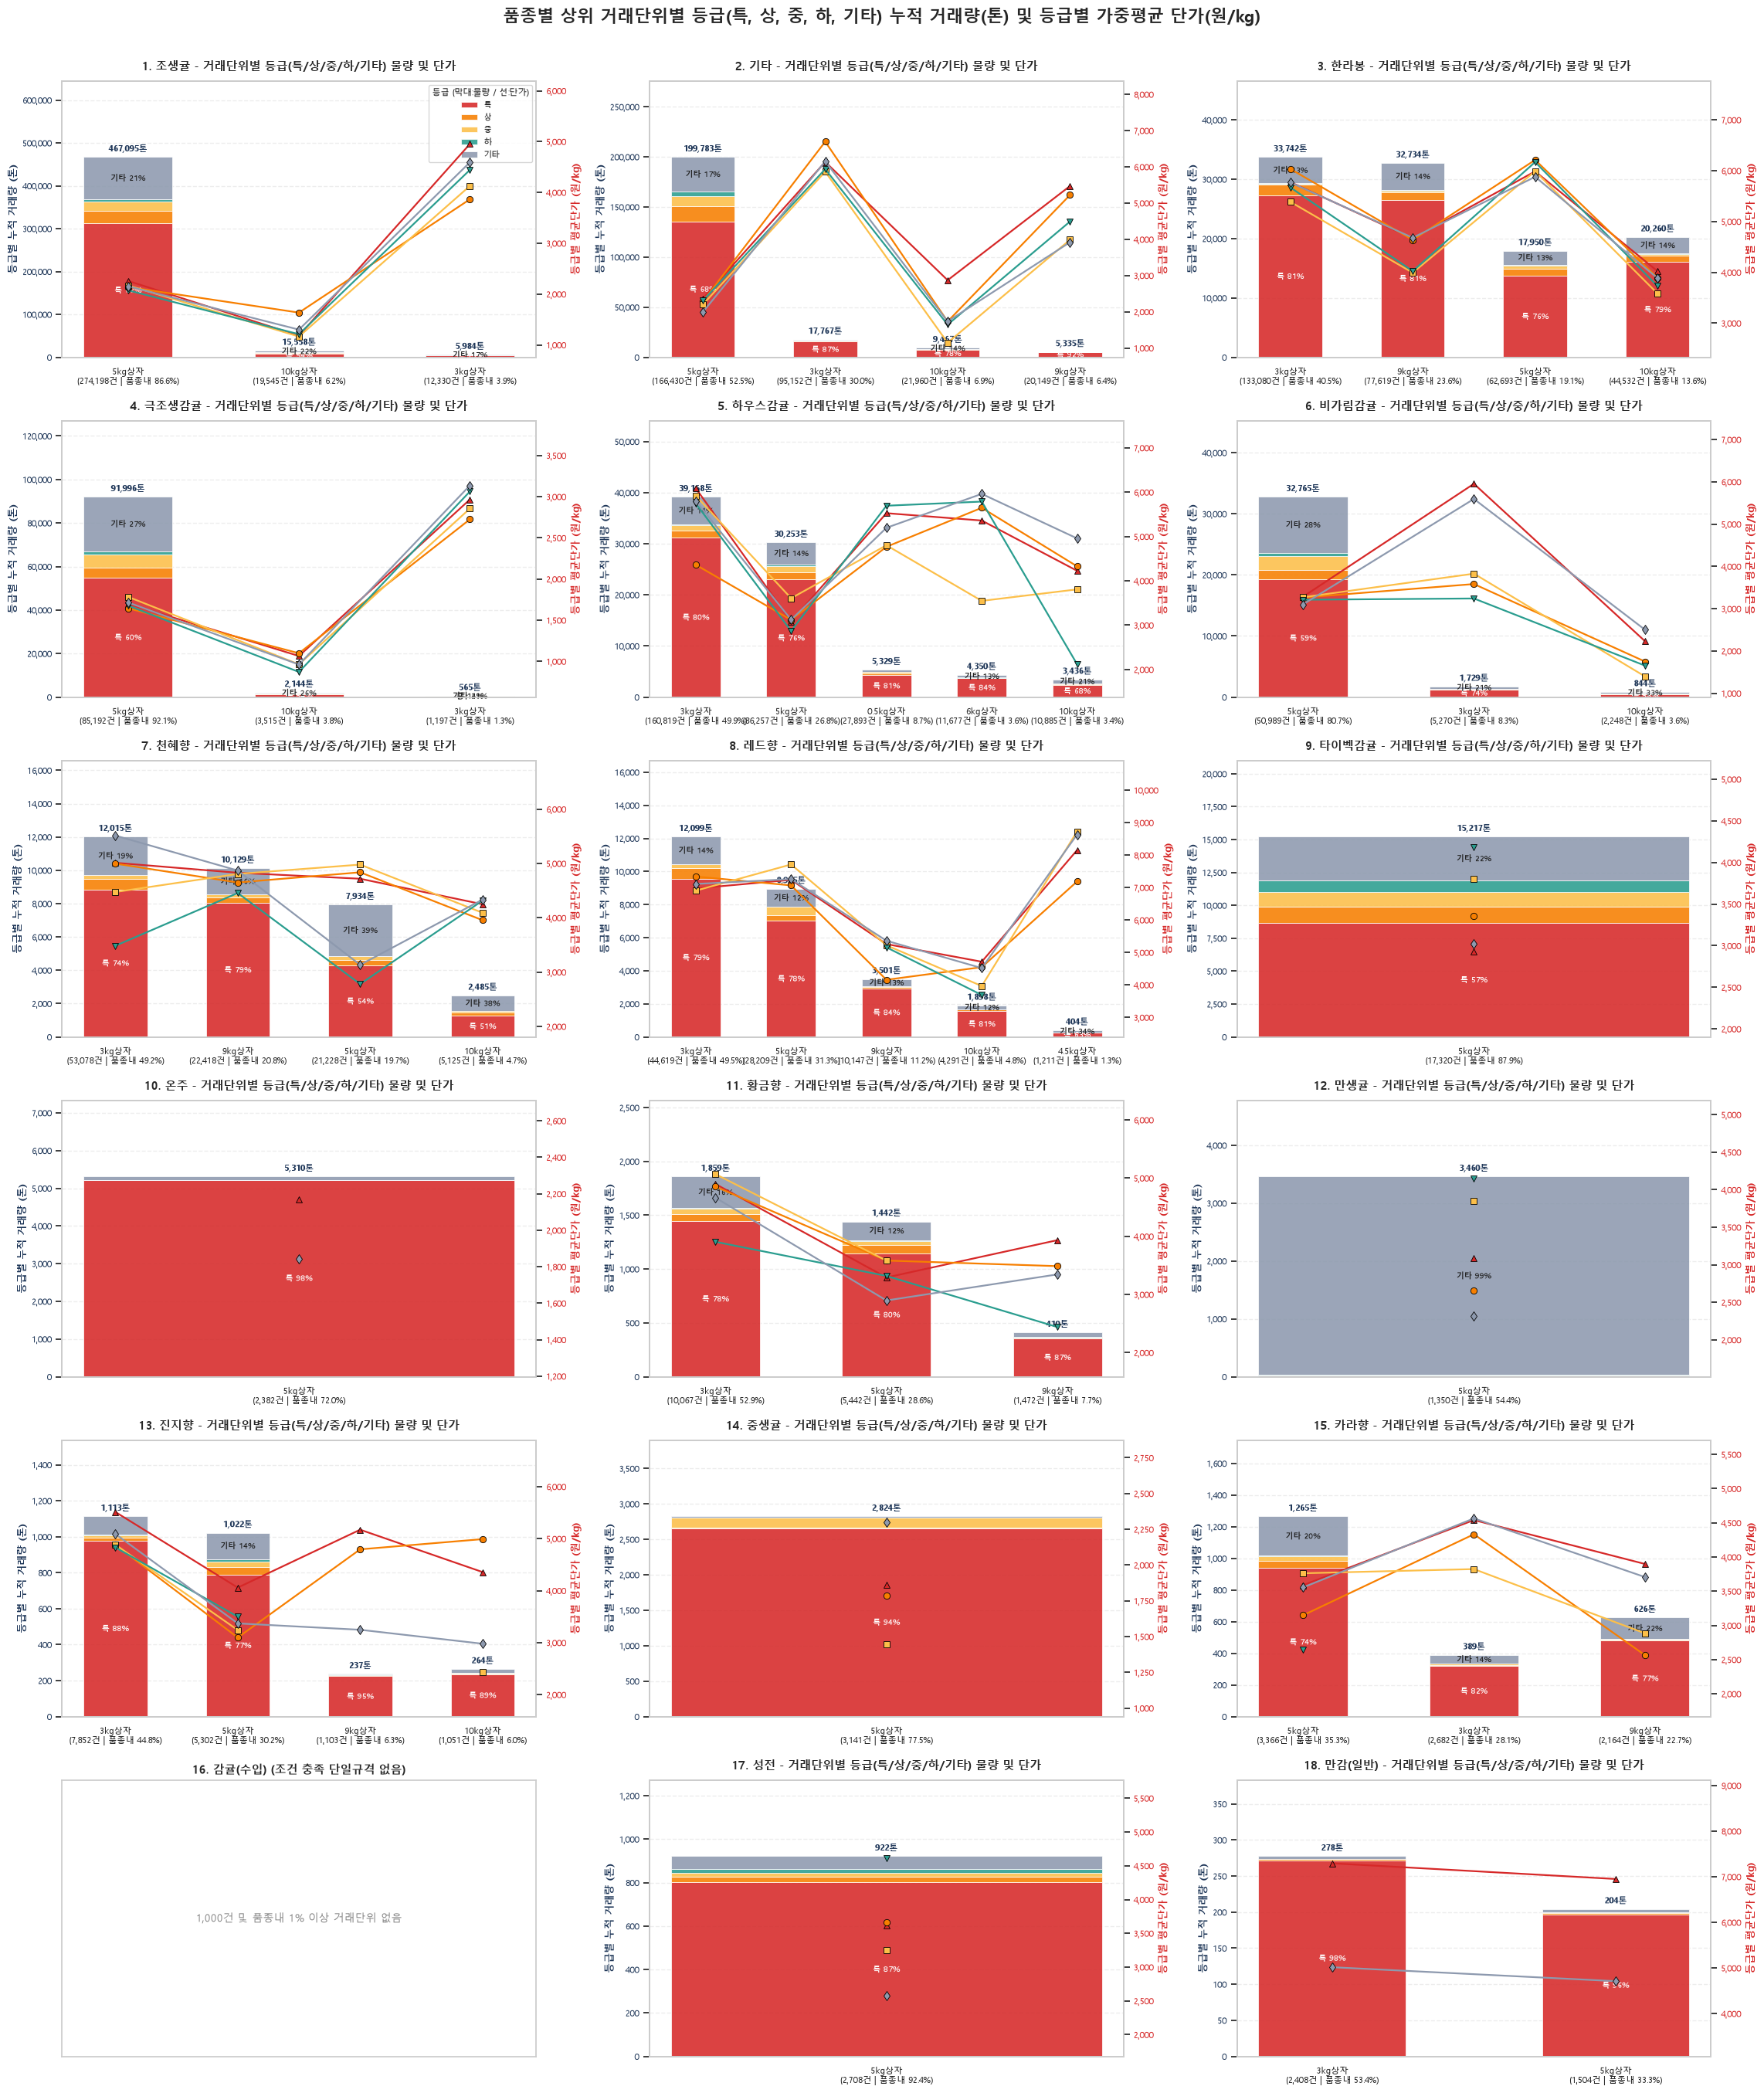

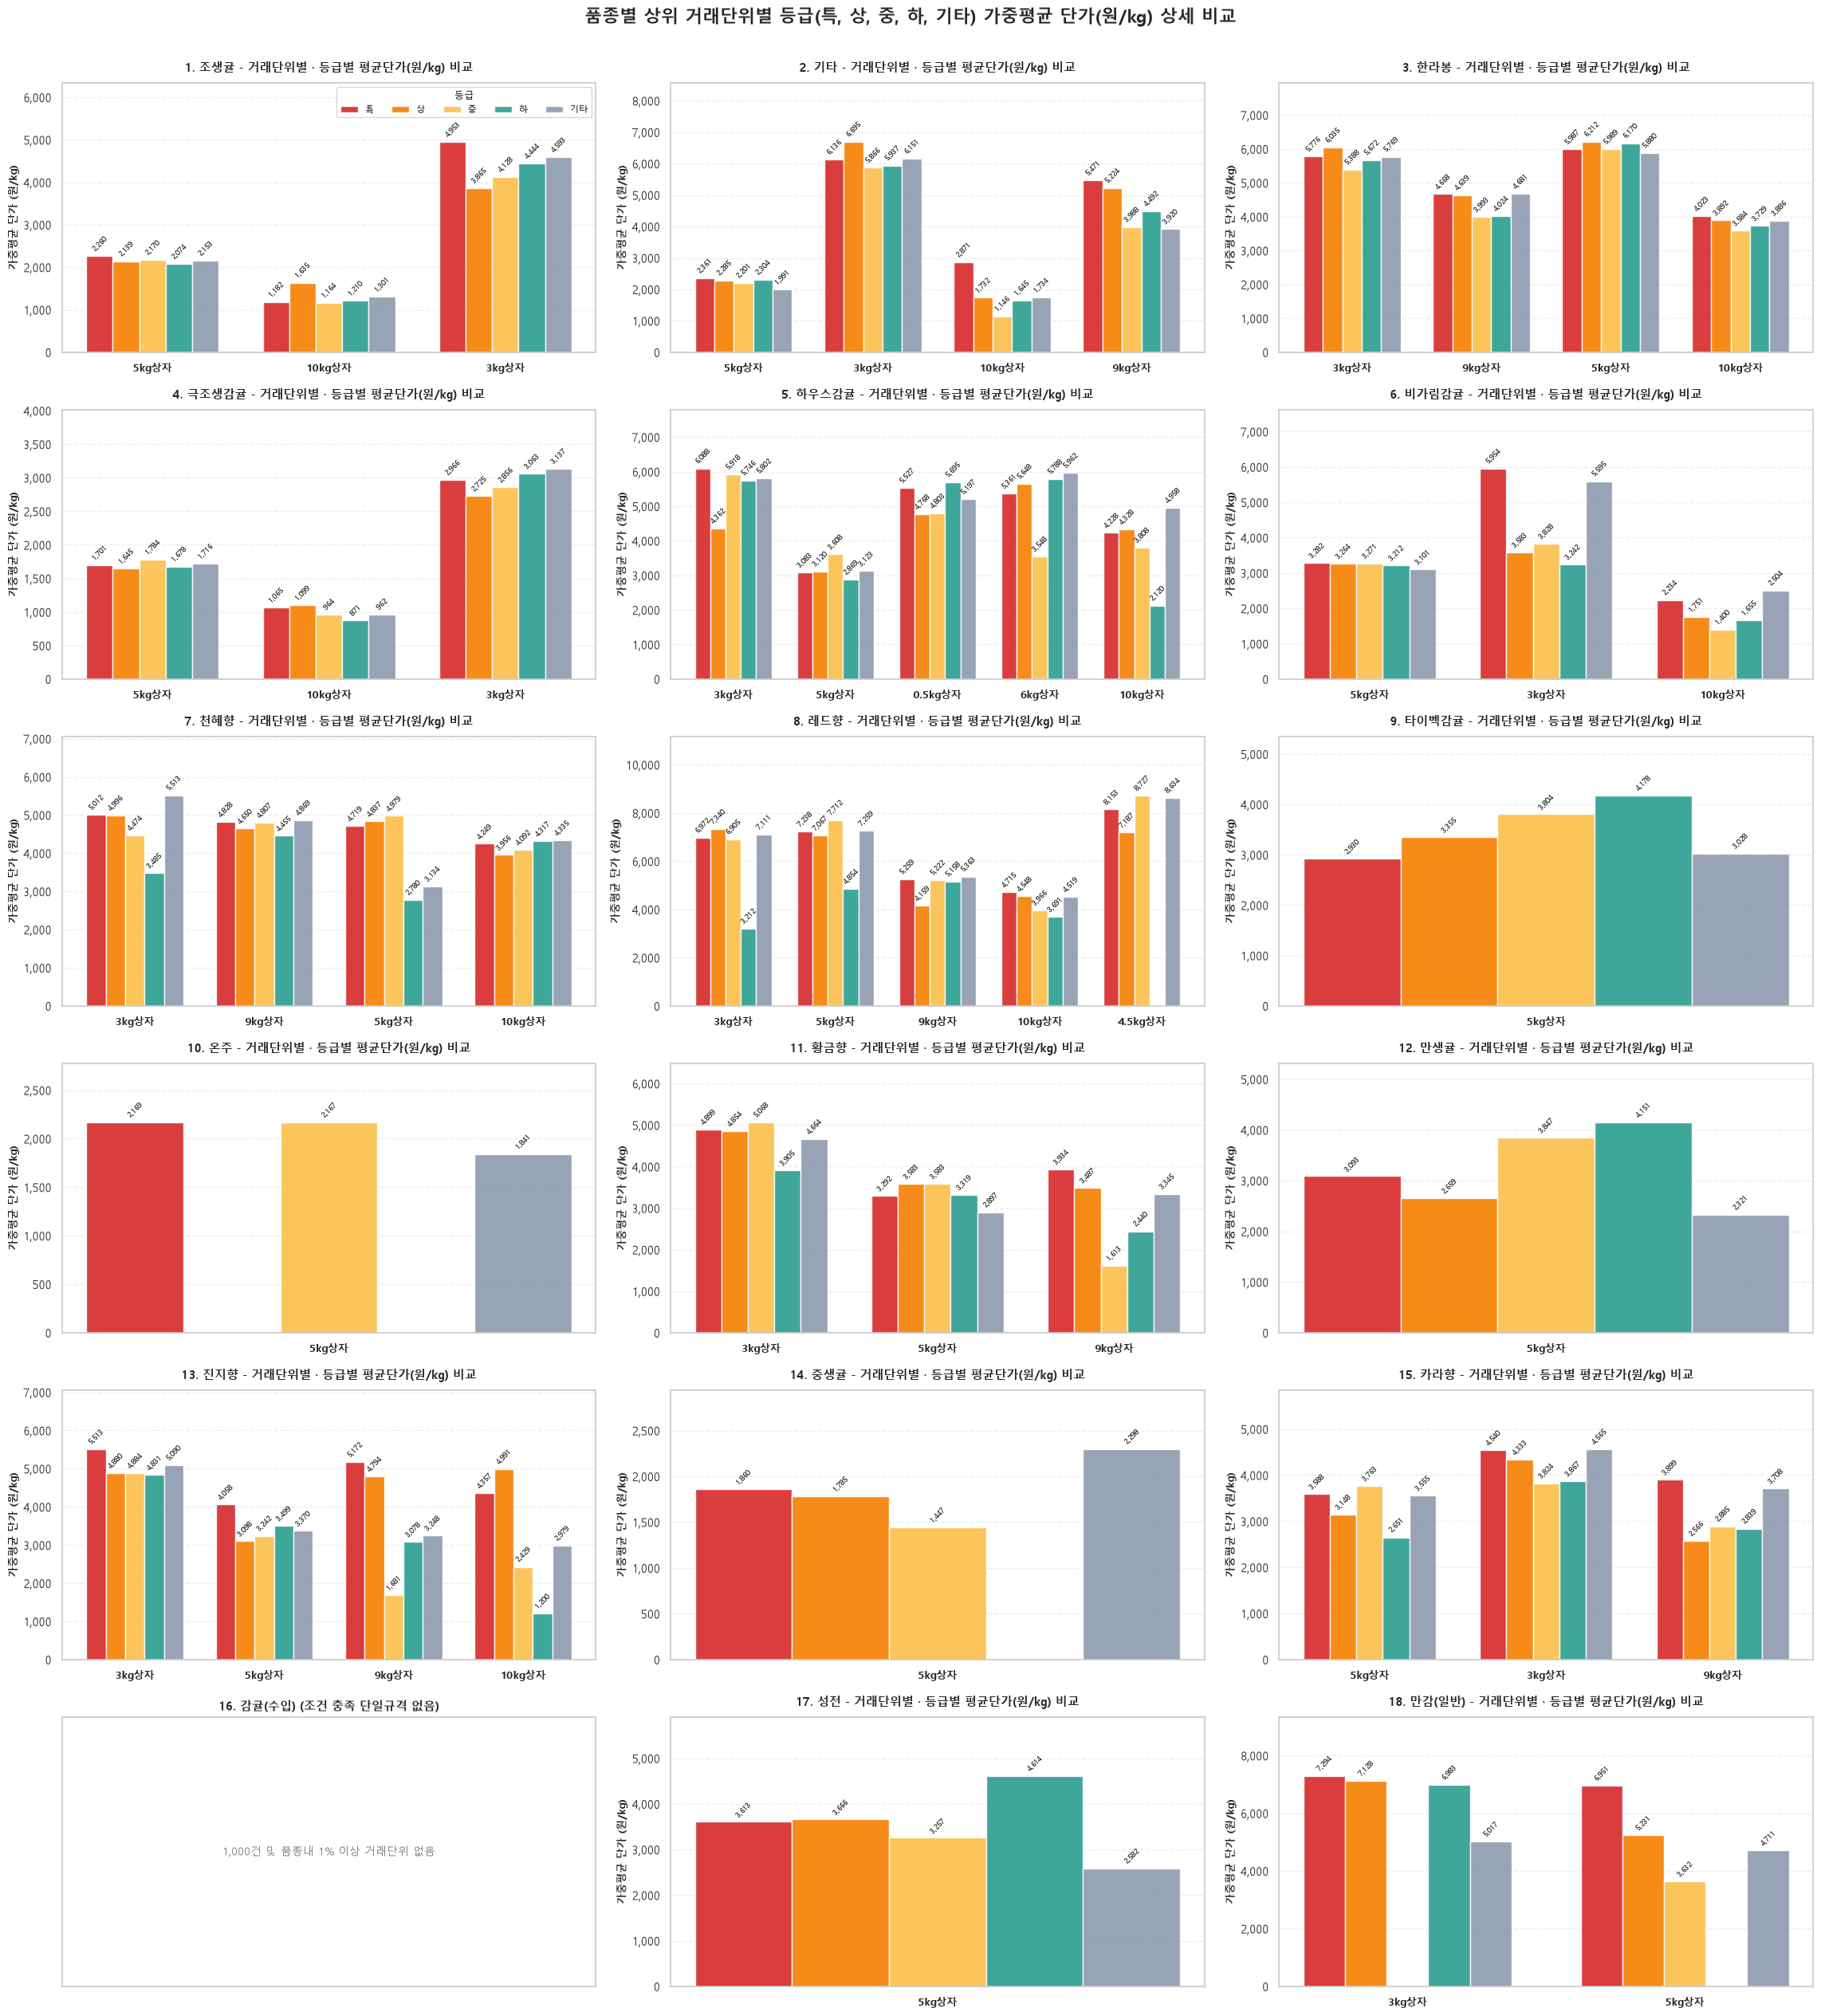

In [18]:
# 1) 등급을 ['특', '상', '중', '하', '기타'] 5개 범주로 표준화
def map_grade_5(g):
    g_str = str(g).strip()
    if g_str in ('특', '특품'):
        return '특'
    elif g_str in ('상', '상품'):
        return '상'
    elif g_str in ('중', '보통', '중품'):
        return '중'
    elif g_str in ('하', '하품'):
        return '하'
    else:
        return '기타'

df['grade_5'] = df['grade'].apply(map_grade_5)
grade_order = ['특', '상', '중', '하', '기타']
grade_colors = {
    '특': '#D62828',   # 진한 빨강
    '상': '#F77F00',   # 주황
    '중': '#FCBF49',   # 노랑/골드
    '하': '#2A9D8F',   # 청록
    '기타': '#8D99AE'  # 회색
}

print("[전체 데이터 등급(특/상/중/하/기타) 분포 건수]")
print(df['grade_5'].value_counts().reindex(grade_order).fillna(0).astype(int))

# 2) 7번에서 정리한 품종별 상위 거래단위(47개 규격) 필터링 및 등급별 집계
valid_pairs = top5_units_per_variety[['variety', 'box_unit', '품종내_순위']].copy()
df_top_units = df.merge(valid_pairs, on=['variety', 'box_unit'], how='inner')

unit_grade_stats = (
    df_top_units.groupby(['variety', '품종내_순위', 'box_unit', 'grade_5'], as_index=False)
    .agg(
        거래건수=('date', 'count'),
        총거래량_kg=('volume_kg', 'sum'),
        총거래금액_원=('total_price', 'sum'),
        평균_상자당가격=('box_price', 'mean')
    )
)
unit_grade_stats['거래량_톤'] = unit_grade_stats['총거래량_kg'] / 1000.0
unit_grade_stats['가중평균_kg단가'] = np.where(
    unit_grade_stats['총거래량_kg'] > 0,
    unit_grade_stats['총거래금액_원'] / unit_grade_stats['총거래량_kg'],
    np.nan
)

# 거래단위 내 등급별 건수/물량 비중 계산
unit_tot = (
    unit_grade_stats.groupby(['variety', 'box_unit'], as_index=False)
    .agg(단위총건수=('거래건수', 'sum'), 단위총물량_톤=('거래량_톤', 'sum'))
)
unit_grade_stats = unit_grade_stats.merge(unit_tot, on=['variety', 'box_unit'], how='left')
unit_grade_stats['단위내_건수비중(%)'] = (unit_grade_stats['거래건수'] / unit_grade_stats['단위총건수']) * 100
unit_grade_stats['단위내_물량비중(%)'] = (unit_grade_stats['거래량_톤'] / unit_grade_stats['단위총물량_톤']) * 100

# 3) 품종별 · 거래단위별 등급(특, 상, 중, 하, 기타) 요약 피벗 테이블 출력
pivot_grade_rows = []
for _, u_row in top5_units_per_variety.iterrows():
    v_name = u_row['variety']
    b_unit = u_row['box_unit']
    r_num = int(u_row['품종내_순위'])
    sub_g = unit_grade_stats[(unit_grade_stats['variety'] == v_name) & (unit_grade_stats['box_unit'] == b_unit)]

    row_data = {
        '품종명': v_name,
        '순위': f"{r_num}위",
        '거래단위': b_unit,
        '단위 총거래량': f"{u_row['거래량_톤']:,.1f}톤",
        '단위 평균단가': f"{u_row['가중평균_kg단가']:,.0f}원/kg"
    }
    for g in grade_order:
        g_match = sub_g[sub_g['grade_5'] == g]
        if len(g_match) > 0:
            gm = g_match.iloc[0]
            row_data[f'{g} 등급 (물량 / 비중 / 단가)'] = (
                f"{gm['거래량_톤']:,.1f}톤 ({gm['단위내_물량비중(%)']:.1f}%) | {gm['가중평균_kg단가']:,.0f}원/kg"
            )
        else:
            row_data[f'{g} 등급 (물량 / 비중 / 단가)'] = "-"
    pivot_grade_rows.append(row_data)

pivot_grade_df = pd.DataFrame(pivot_grade_rows)
print(f"\n[7번 선정 품종별·거래단위별 등급(특/상/중/하/기타) 상세 요약표 (총 {len(pivot_grade_df)}개 규격)]")
display(pivot_grade_df)

# 4) 그래프 1: 품종별 상위 거래단위의 등급별(특/상/중/하/기타) 거래량(누적 막대) 및 등급별 평균단가(꺾은선) (6행 x 3열)
ncols_g = 3
nrows_g = int(np.ceil(len(variety_order) / ncols_g))
fig, axes = plt.subplots(nrows_g, ncols_g, figsize=(23, nrows_g * 4.5))
axes = axes.flatten()

for idx, var_name in enumerate(variety_order):
    ax1 = axes[idx]
    sub_u = top5_units_per_variety[top5_units_per_variety['variety'] == var_name].copy()

    if len(sub_u) == 0:
        ax1.set_title(f"{idx + 1}. {var_name} (조건 충족 단일규격 없음)", fontsize=11, fontweight='bold')
        ax1.text(0.5, 0.5, '1,000건 및 품종내 1% 이상 거래단위 없음', ha='center', va='center', fontsize=10, color='gray')
        ax1.set_xticks([])
        ax1.set_yticks([])
        continue

    units = sub_u['box_unit'].tolist()
    x_pos = np.arange(len(units))
    bottom_vals = np.zeros(len(units))

    # 좌측 Y축: 등급별 누적 거래량 (톤)
    for g in grade_order:
        g_vols = []
        g_pcts = []
        for u in units:
            m = unit_grade_stats[
                (unit_grade_stats['variety'] == var_name) &
                (unit_grade_stats['box_unit'] == u) &
                (unit_grade_stats['grade_5'] == g)
            ]
            g_vols.append(m['거래량_톤'].iloc[0] if len(m) > 0 else 0.0)
            g_pcts.append(m['단위내_물량비중(%)'].iloc[0] if len(m) > 0 else 0.0)
        g_vols = np.array(g_vols)
        bars = ax1.bar(
            x_pos,
            g_vols,
            bottom=bottom_vals,
            color=grade_colors[g],
            alpha=0.88,
            width=0.52,
             edgecolor='white',
            linewidth=0.6,
            label=f"{g}(물량)"
        )
        # 비중이 12% 이상인 등급 구간 내부에 등급명 및 비중 표시
        for xi, (v_val, p_val, b_val) in enumerate(zip(g_vols, g_pcts, bottom_vals)):
            if p_val >= 12.0:
                ax1.text(
                    xi,
                    b_val + v_val / 2,
                    f"{g} {p_val:.0f}%",
                    ha='center',
                    va='center',
                    fontsize=7.5,
                    fontweight='bold',
                    color='white' if g in ('특', '상', '하') else '#222222'
                )
        bottom_vals += g_vols

    max_tot_v = bottom_vals.max()
    ax1.set_ylim(0, max_tot_v * 1.38 if max_tot_v > 0 else 1)
    for xi, tot_v in enumerate(bottom_vals):
        if tot_v > 0:
            vol_str = f"{tot_v:,.0f}톤" if tot_v >= 100 else f"{tot_v:,.1f}톤"
            ax1.text(
                xi,
                tot_v + (max_tot_v * 0.02),
                vol_str,
                ha='center',
                va='bottom',
                fontsize=8,
                fontweight='bold',
                color='#1D3557'
            )

    ax1.set_title(f"{idx + 1}. {var_name} - 거래단위별 등급(특/상/중/하/기타) 물량 및 단가", fontsize=11, fontweight='bold', pad=10)
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(
        [
            f"{row['box_unit']}\n({row['거래건수']:,.0f}건 | 품종내 {row['품종내_건수비중(%)']:.1f}%)"
            for _, row in sub_u.iterrows()
        ],
        fontsize=8.2
    )
    ax1.set_ylabel('등급별 누적 거래량 (톤)', color='#1D3557', fontsize=9, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='#1D3557', labelsize=8)
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax1.grid(axis='y', linestyle='--', alpha=0.35)
    ax1.grid(axis='x', visible=False)

    # 우측 Y축: 등급별 가중평균 단가 (원/kg) 포인트 및 선 표시
    ax2 = ax1.twinx()
    all_prcs = []
    grade_markers = {'특': '^', '상': 'o', '중': 's', '하': 'v', '기타': 'd'}
    for g in grade_order:
        g_prcs = []
        for u in units:
            m = unit_grade_stats[
                (unit_grade_stats['variety'] == var_name) &
                (unit_grade_stats['box_unit'] == u) &
                (unit_grade_stats['grade_5'] == g)
            ]
            val = m['가중평균_kg단가'].iloc[0] if len(m) > 0 and m['거래건수'].iloc[0] >= 10 else np.nan
            g_prcs.append(val)
            if pd.notnull(val):
                all_prcs.append(val)
        ax2.plot(
            x_pos,
            g_prcs,
            color=grade_colors[g],
            marker=grade_markers[g],
            markersize=6,
            linewidth=1.6,
            linestyle='-',
            markeredgecolor='black',
            markeredgewidth=0.6,
            label=f"{g}(단가)"
        )

    ax2.set_ylabel('등급별 평균단가 (원/kg)', color='#D62828', fontsize=9, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#D62828', labelsize=8)
    ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax2.grid(False)
    if len(all_prcs) > 0:
        ax2.set_ylim(max(0, min(all_prcs) * 0.65), max(all_prcs) * 1.25)

    if idx == 0:
        handles1, labels1 = ax1.get_legend_handles_labels()
        ax1.legend(handles1, ['특', '상', '중', '하', '기타'], title='등급 (막대:물량 / 선:단가)', loc='upper right', fontsize=7.5, title_fontsize=8)

for j in range(len(variety_order), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    '품종별 상위 거래단위별 등급(특, 상, 중, 하, 기타) 누적 거래량(톤) 및 등급별 가중평균 단가(원/kg)',
    fontsize=16,
    fontweight='bold',
    y=1.003
)
plt.tight_layout()
plt.show()

# 5) 그래프 2: 품종별 · 상위 거래단위별 등급(특, 상, 중, 하, 기타) 가중평균 단가(원/kg) 그룹 막대그래프 비교 (6행 x 3열)
fig2, axes2 = plt.subplots(nrows_g, ncols_g, figsize=(23, nrows_g * 4.2))
axes2 = axes2.flatten()

bar_w = 0.15
offsets = np.linspace(-2 * bar_w, 2 * bar_w, len(grade_order))

for idx, var_name in enumerate(variety_order):
    ax = axes2[idx]
    sub_u = top5_units_per_variety[top5_units_per_variety['variety'] == var_name].copy()

    if len(sub_u) == 0:
        ax.set_title(f"{idx + 1}. {var_name} (조건 충족 단일규격 없음)", fontsize=11, fontweight='bold')
        ax.text(0.5, 0.5, '1,000건 및 품종내 1% 이상 거래단위 없음', ha='center', va='center', fontsize=10, color='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        continue

    units = sub_u['box_unit'].tolist()
    x_pos = np.arange(len(units))
    max_p_var = 0

    for g_idx, g in enumerate(grade_order):
        g_prcs = []
        for u in units:
            m = unit_grade_stats[
                (unit_grade_stats['variety'] == var_name) &
                (unit_grade_stats['box_unit'] == u) &
                (unit_grade_stats['grade_5'] == g)
            ]
            val = m['가중평균_kg단가'].iloc[0] if len(m) > 0 else 0.0
            g_prcs.append(val)
            if val > max_p_var:
                max_p_var = val

        bars = ax.bar(
            x_pos + offsets[g_idx],
            g_prcs,
            width=bar_w,
            color=grade_colors[g],
            alpha=0.9,
            label=g
        )
        for bar in bars:
            h = bar.get_height()
            if h > 0:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    h + (max_p_var * 0.015),
                    f"{h:,.0f}",
                    ha='center',
                    va='bottom',
                    fontsize=6.5,
                    rotation=45,
                    color='#222222'
                )

    ax.set_title(f"{idx + 1}. {var_name} - 거래단위별 · 등급별 평균단가(원/kg) 비교", fontsize=11, fontweight='bold', pad=10)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(units, fontsize=9, fontweight='bold')
    ax.set_ylabel('가중평균 단가 (원/kg)', fontsize=9, fontweight='bold')
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax.set_ylim(0, max_p_var * 1.28 if max_p_var > 0 else 1)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.grid(axis='x', visible=False)
    if idx == 0:
        ax.legend(title='등급', loc='upper right', fontsize=8, title_fontsize=8.5, ncol=5)

for j in range(len(variety_order), len(axes2)):
    axes2[j].set_visible(False)

fig2.suptitle(
    '품종별 상위 거래단위별 등급(특, 상, 중, 하, 기타) 가중평균 단가(원/kg) 상세 비교',
    fontsize=16,
    fontweight='bold',
    y=1.003
)
plt.tight_layout()
plt.show()

## 9. 품종별 · 상위 거래단위별 크기(`Size`)별 가격 및 거래량 통계 분석 및 시각화
- 7번 섹션에서 선정된 **품종별 상위 거래단위(거래건수 1,000건 이상 & 품종내 비중 1% 이상, 총 48개 규격)** 각각에 대해 **크기(`size`, `sz_nm`)별 거래량(톤), 물량 비중(%), 가중평균 단가(원/kg) 및 평균 상자당 가격(원/상자)**을 집계하고 시각화합니다.
- 공영도매시장의 감귤 크기 표기는 크게 **직접 크기 표기(`특대, 대, 중, 소, 2L, L, M, S, 2S`)**, **상자당 개수 표기(`6개 ~ 25개`, 만감류 중심 — 과수가 적을수록 대과)**, **상자당 과수 표기(`25내 ~ 90내`, 온주·하우스감귤 중심 — 과수가 적을수록 대과)**로 구분됩니다.
- 이에 따라:
  1. **표준 5대 크기 그룹(`대과`, `중과`, `소과`, `기타규격`, `미지정`) 기준 품종·거래단위별 거래량 및 가격 비교표**
  2. **각 `(품종 × 거래단위)`별 실제 가장 많이 거래되는 원본 세부 크기 규격(`Top 1~5위 크기명`, 예: `10개, 12개, 40내, 50내, 특대, 대, 중, 소` 등) 상세 통계표**
  3. **품종별 · 상위 거래단위별 크기 그룹별 누적 거래량(톤) 및 가중평균 단가(원/kg) 시각화 그래프 3종**을 함께 제공합니다.

[전체 데이터 표준 5대 크기 그룹(대과/중과/소과/기타규격/미지정) 분포 건수]
size_5
대과      339395
중과      443258
소과      239662
기타규격     34117
미지정     666199
Name: count, dtype: int64

[전체 데이터 원본 세부 크기(size) 상위 20개 분포 건수]
size
미지정    666199
50내     79848
40내     78595
12개     52955
10개     51733
45내     47340
35내     46592
11개     46063
특대      41306
13개     38145
소       36781
9개      36002
14개     31867
60내     31041
8개      29944
30내     29323
대       28040
중       25246
20개     19898
15개     19649
Name: count, dtype: int64

[1. 7번 선정 품종별·거래단위별 표준 크기 그룹(대과/중과/소과/기타규격/미지정) 가격 및 거래량 요약표 (총 48개 규격)]


,품종명,순위,거래단위,단위 총거래량,단위 평균단가,대과 (물량 / 비중 / 단가),중과 (물량 / 비중 / 단가),소과 (물량 / 비중 / 단가),기타규격 (물량 / 비중 / 단가),미지정 (물량 / 비중 / 단가)
0,조생귤,1위,5kg상자,"467,094.8톤","2,224원/kg (상자 10,155원)","22,759.8톤 (4.9%) | 1,926원/kg (상자 8,021원)","34,556.7톤 (7.4%) | 2,430원/kg (상자 11,189원)","50,363.0톤 (10.8%) | 2,553원/kg (상자 10,224원)","19,172.8톤 (4.1%) | 2,229원/kg (상자 10,118원)","340,242.6톤 (72.8%) | 2,174원/kg (상자 10,185원)"
1,조생귤,2위,10kg상자,"15,558.1톤","1,257원/kg (상자 13,560원)","782.1톤 (5.0%) | 963원/kg (상자 10,329원)","1,933.8톤 (12.4%) | 1,465원/kg (상자 15,023원)","702.6톤 (4.5%) | 1,141원/kg (상자 11,559원)","312.6톤 (2.0%) | 1,520원/kg (상자 13,066원)","11,827.0톤 (76.0%) | 1,242원/kg (상자 13,893원)"
2,조생귤,3위,3kg상자,"5,983.6톤","4,850원/kg (상자 15,788원)","476.5톤 (8.0%) | 4,835원/kg (상자 14,533원)","497.9톤 (8.3%) | 5,323원/kg (상자 16,177원)","500.0톤 (8.4%) | 7,143원/kg (상자 17,752원)","366.7톤 (6.1%) | 4,074원/kg (상자 12,976원)","4,142.5톤 (69.2%) | 4,588원/kg (상자 15,834원)"
3,기타,1위,5kg상자,"199,782.8톤","2,283원/kg (상자 14,582원)","32,898.9톤 (16.5%) | 1,777원/kg (상자 11,180원)","22,159.8톤 (11.1%) | 2,751원/kg (상자 21,437원)","33,058.7톤 (16.5%) | 2,439원/kg (상자 16,534원)","907.5톤 (0.5%) | 3,160원/kg (상자 14,047원)","110,758.0톤 (55.4%) | 2,285원/kg (상자 11,903원)"
4,기타,2위,3kg상자,"17,767.2톤","6,166원/kg (상자 17,910원)","4,404.1톤 (24.8%) | 6,301원/kg (상자 17,665원)","5,794.6톤 (32.6%) | 6,482원/kg (상자 18,449원)","1,211.5톤 (6.8%) | 5,516원/kg (상자 16,212원)","147.2톤 (0.8%) | 6,009원/kg (상자 18,349원)","6,209.8톤 (35.0%) | 5,907원/kg (상자 18,204원)"
5,기타,3위,10kg상자,"9,467.2톤","2,602원/kg (상자 30,406원)","1,533.6톤 (16.2%) | 2,142원/kg (상자 22,010원)","2,059.9톤 (21.8%) | 3,913원/kg (상자 39,945원)","1,576.8톤 (16.7%) | 2,534원/kg (상자 32,894원)","87.7톤 (0.9%) | 4,199원/kg (상자 33,616원)","4,209.2톤 (44.5%) | 2,120원/kg (상자 25,621원)"
6,기타,4위,9kg상자,"5,334.5톤","5,396원/kg (상자 45,048원)","520.9톤 (9.8%) | 4,907원/kg (상자 41,030원)","2,475.6톤 (46.4%) | 5,894원/kg (상자 50,064원)","1,049.8톤 (19.7%) | 5,060원/kg (상자 41,947원)","55.0톤 (1.0%) | 5,118원/kg (상자 41,340원)","1,233.2톤 (23.1%) | 4,901원/kg (상자 42,117원)"
7,한라봉,1위,3kg상자,"33,742.4톤","5,786원/kg (상자 16,495원)","10,897.2톤 (32.3%) | 5,832원/kg (상자 16,836원)","5,544.4톤 (16.4%) | 5,716원/kg (상자 15,609원)","357.3톤 (1.1%) | 5,396원/kg (상자 15,025원)","777.3톤 (2.3%) | 5,945원/kg (상자 17,608원)","16,166.1톤 (47.9%) | 5,780원/kg (상자 16,672원)"
8,한라봉,2위,9kg상자,"32,734.2톤","4,659원/kg (상자 37,441원)","3,166.3톤 (9.7%) | 4,446원/kg (상자 37,419원)","12,649.4톤 (38.6%) | 4,882원/kg (상자 38,210원)","2,690.1톤 (8.2%) | 4,513원/kg (상자 33,984원)","524.3톤 (1.6%) | 4,850원/kg (상자 40,533원)","13,704.1톤 (41.9%) | 4,523원/kg (상자 38,332원)"
9,한라봉,3위,5kg상자,"17,949.5톤","5,989원/kg (상자 28,674원)","1,149.7톤 (6.4%) | 5,515원/kg (상자 27,637원)","4,957.0톤 (27.6%) | 6,294원/kg (상자 30,529원)","2,013.0톤 (11.2%) | 5,502원/kg (상자 25,193원)","423.8톤 (2.4%) | 6,083원/kg (상자 28,572원)","9,406.0톤 (52.4%) | 5,986원/kg (상자 28,437원)"



[2. 품종별·거래단위별 실제 거래 상위 1~5위 세부 크기 규격(50내/40내/10개/12개/특대/대/중/소 등) 상세 통계표]


,품종명,순위,거래단위,미지정 크기 (물량/비중/단가),크기 1위 (규격명: 물량 / 비중 / 단가 / 상자가),크기 2위 (규격명: 물량 / 비중 / 단가 / 상자가),크기 3위 (규격명: 물량 / 비중 / 단가 / 상자가),크기 4위 (규격명: 물량 / 비중 / 단가 / 상자가),크기 5위 (규격명: 물량 / 비중 / 단가 / 상자가)
0,조생귤,1위,5kg상자,"340,242.6톤 (72.8%) | 2,174원/kg","[소] 19,808.9톤 (4.2%) | 2,956원/kg (상자 11,148원)","[1개(내,뿌리)] 13,841.1톤 (3.0%) | 2,080원/kg (상자 8,...","[중] 12,225.5톤 (2.6%) | 2,669원/kg (상자 11,051원)","[대] 10,103.1톤 (2.2%) | 2,166원/kg (상자 8,463원)","[특대] 9,944.1톤 (2.1%) | 1,694원/kg (상자 7,007원)"
1,조생귤,2위,10kg상자,"11,827.0톤 (76.0%) | 1,242원/kg","[특대] 560.0톤 (3.6%) | 910원/kg (상자 8,320원)","[12개] 445.1톤 (2.9%) | 1,644원/kg (상자 17,730원)","[14개] 371.7톤 (2.4%) | 1,216원/kg (상자 14,347원)","[11개] 335.4톤 (2.2%) | 1,600원/kg (상자 16,609원)","[50내] 273.9톤 (1.8%) | 1,194원/kg (상자 10,890원)"
2,조생귤,3위,3kg상자,"4,142.5톤 (69.2%) | 4,588원/kg","[소] 439.5톤 (7.3%) | 7,554원/kg (상자 21,026원)","[특대] 305.7톤 (5.1%) | 5,171원/kg (상자 14,317원)","[1개(내,뿌리)] 219.3톤 (3.7%) | 4,030원/kg (상자 13,071원)","[중] 167.6톤 (2.8%) | 6,771원/kg (상자 22,004원)","[기타] 147.4톤 (2.5%) | 4,139원/kg (상자 12,633원)"
3,기타,1위,5kg상자,"110,758.0톤 (55.4%) | 2,285원/kg","[소] 26,425.0톤 (13.2%) | 2,227원/kg (상자 10,916원)","[특대] 16,350.3톤 (8.2%) | 1,503원/kg (상자 6,686원)","[중] 15,017.1톤 (7.5%) | 2,135원/kg (상자 10,558원)","[대] 14,375.3톤 (7.2%) | 1,880원/kg (상자 8,745원)","[50내] 3,051.7톤 (1.5%) | 2,150원/kg (상자 11,296원)"
4,기타,2위,3kg상자,"6,209.8톤 (35.0%) | 5,907원/kg","[10개] 2,020.5톤 (11.4%) | 6,754원/kg (상자 19,375원)","[12개] 1,637.3톤 (9.2%) | 6,733원/kg (상자 19,352원)","[11개] 1,502.1톤 (8.5%) | 6,715원/kg (상자 19,510원)","[13개] 1,430.1톤 (8.0%) | 6,866원/kg (상자 18,568원)","[9개] 848.8톤 (4.8%) | 6,385원/kg (상자 18,514원)"
5,기타,3위,10kg상자,"4,209.2톤 (44.5%) | 2,120원/kg","[특대] 912.8톤 (9.6%) | 1,825원/kg (상자 11,612원)","[소] 826.9톤 (8.7%) | 954원/kg (상자 10,007원)","[50내] 639.6톤 (6.8%) | 4,620원/kg (상자 43,595원)","[45내] 484.9톤 (5.1%) | 4,929원/kg (상자 47,165원)","[중] 472.1톤 (5.0%) | 1,123원/kg (상자 11,036원)"
6,기타,4위,9kg상자,"1,233.2톤 (23.1%) | 4,901원/kg","[50내] 1,080.9톤 (20.3%) | 6,075원/kg (상자 51,032원)","[60내] 644.0톤 (12.1%) | 5,409원/kg (상자 47,152원)","[40내] 581.0톤 (10.9%) | 5,761원/kg (상자 49,127원)","[45내] 568.2톤 (10.7%) | 5,702원/kg (상자 50,287원)","[35내] 224.7톤 (4.2%) | 5,013원/kg (상자 44,166원)"
7,한라봉,1위,3kg상자,"16,166.1톤 (47.9%) | 5,780원/kg","[10개] 4,093.9톤 (12.1%) | 5,827원/kg (상자 16,772원)","[9개] 2,879.8톤 (8.5%) | 5,661원/kg (상자 16,832원)","[8개] 2,019.0톤 (6.0%) | 5,924원/kg (상자 17,226원)","[13개] 1,738.5톤 (5.2%) | 6,035원/kg (상자 15,678원)","[11개] 1,731.1톤 (5.1%) | 5,499원/kg (상자 15,843원)"
8,한라봉,2위,9kg상자,"13,704.1톤 (41.9%) | 4,523원/kg","[40내] 5,170.5톤 (15.8%) | 4,659원/kg (상자 39,678원)","[50내] 4,172.4톤 (12.7%) | 5,286원/kg (상자 37,623원)","[35내] 1,765.8톤 (5.4%) | 4,387원/kg (상자 38,228원)","[60내] 1,748.2톤 (5.3%) | 4,651원/kg (상자 34,942원)","[45내] 1,206.4톤 (3.7%) | 4,451원/kg (상자 36,632원)"
9,한라봉,3위,5kg상자,"9,406.0톤 (52.4%) | 5,986원/kg","[14개] 1,275.6톤 (7.1%) | 6,415원/kg (상자 30,731원)","[15개] 1,108.5톤 (6.2%) | 5,961원/kg (상자 29,134원)","[16개] 1,033.2톤 (5.8%) | 5,947원/kg (상자 27,822원)","[12개] 970.7톤 (5.4%) | 6,600원/kg (상자 31,975원)","[13개] 884.6톤 (4.9%) | 6,583원/kg (상자 31,916원)"


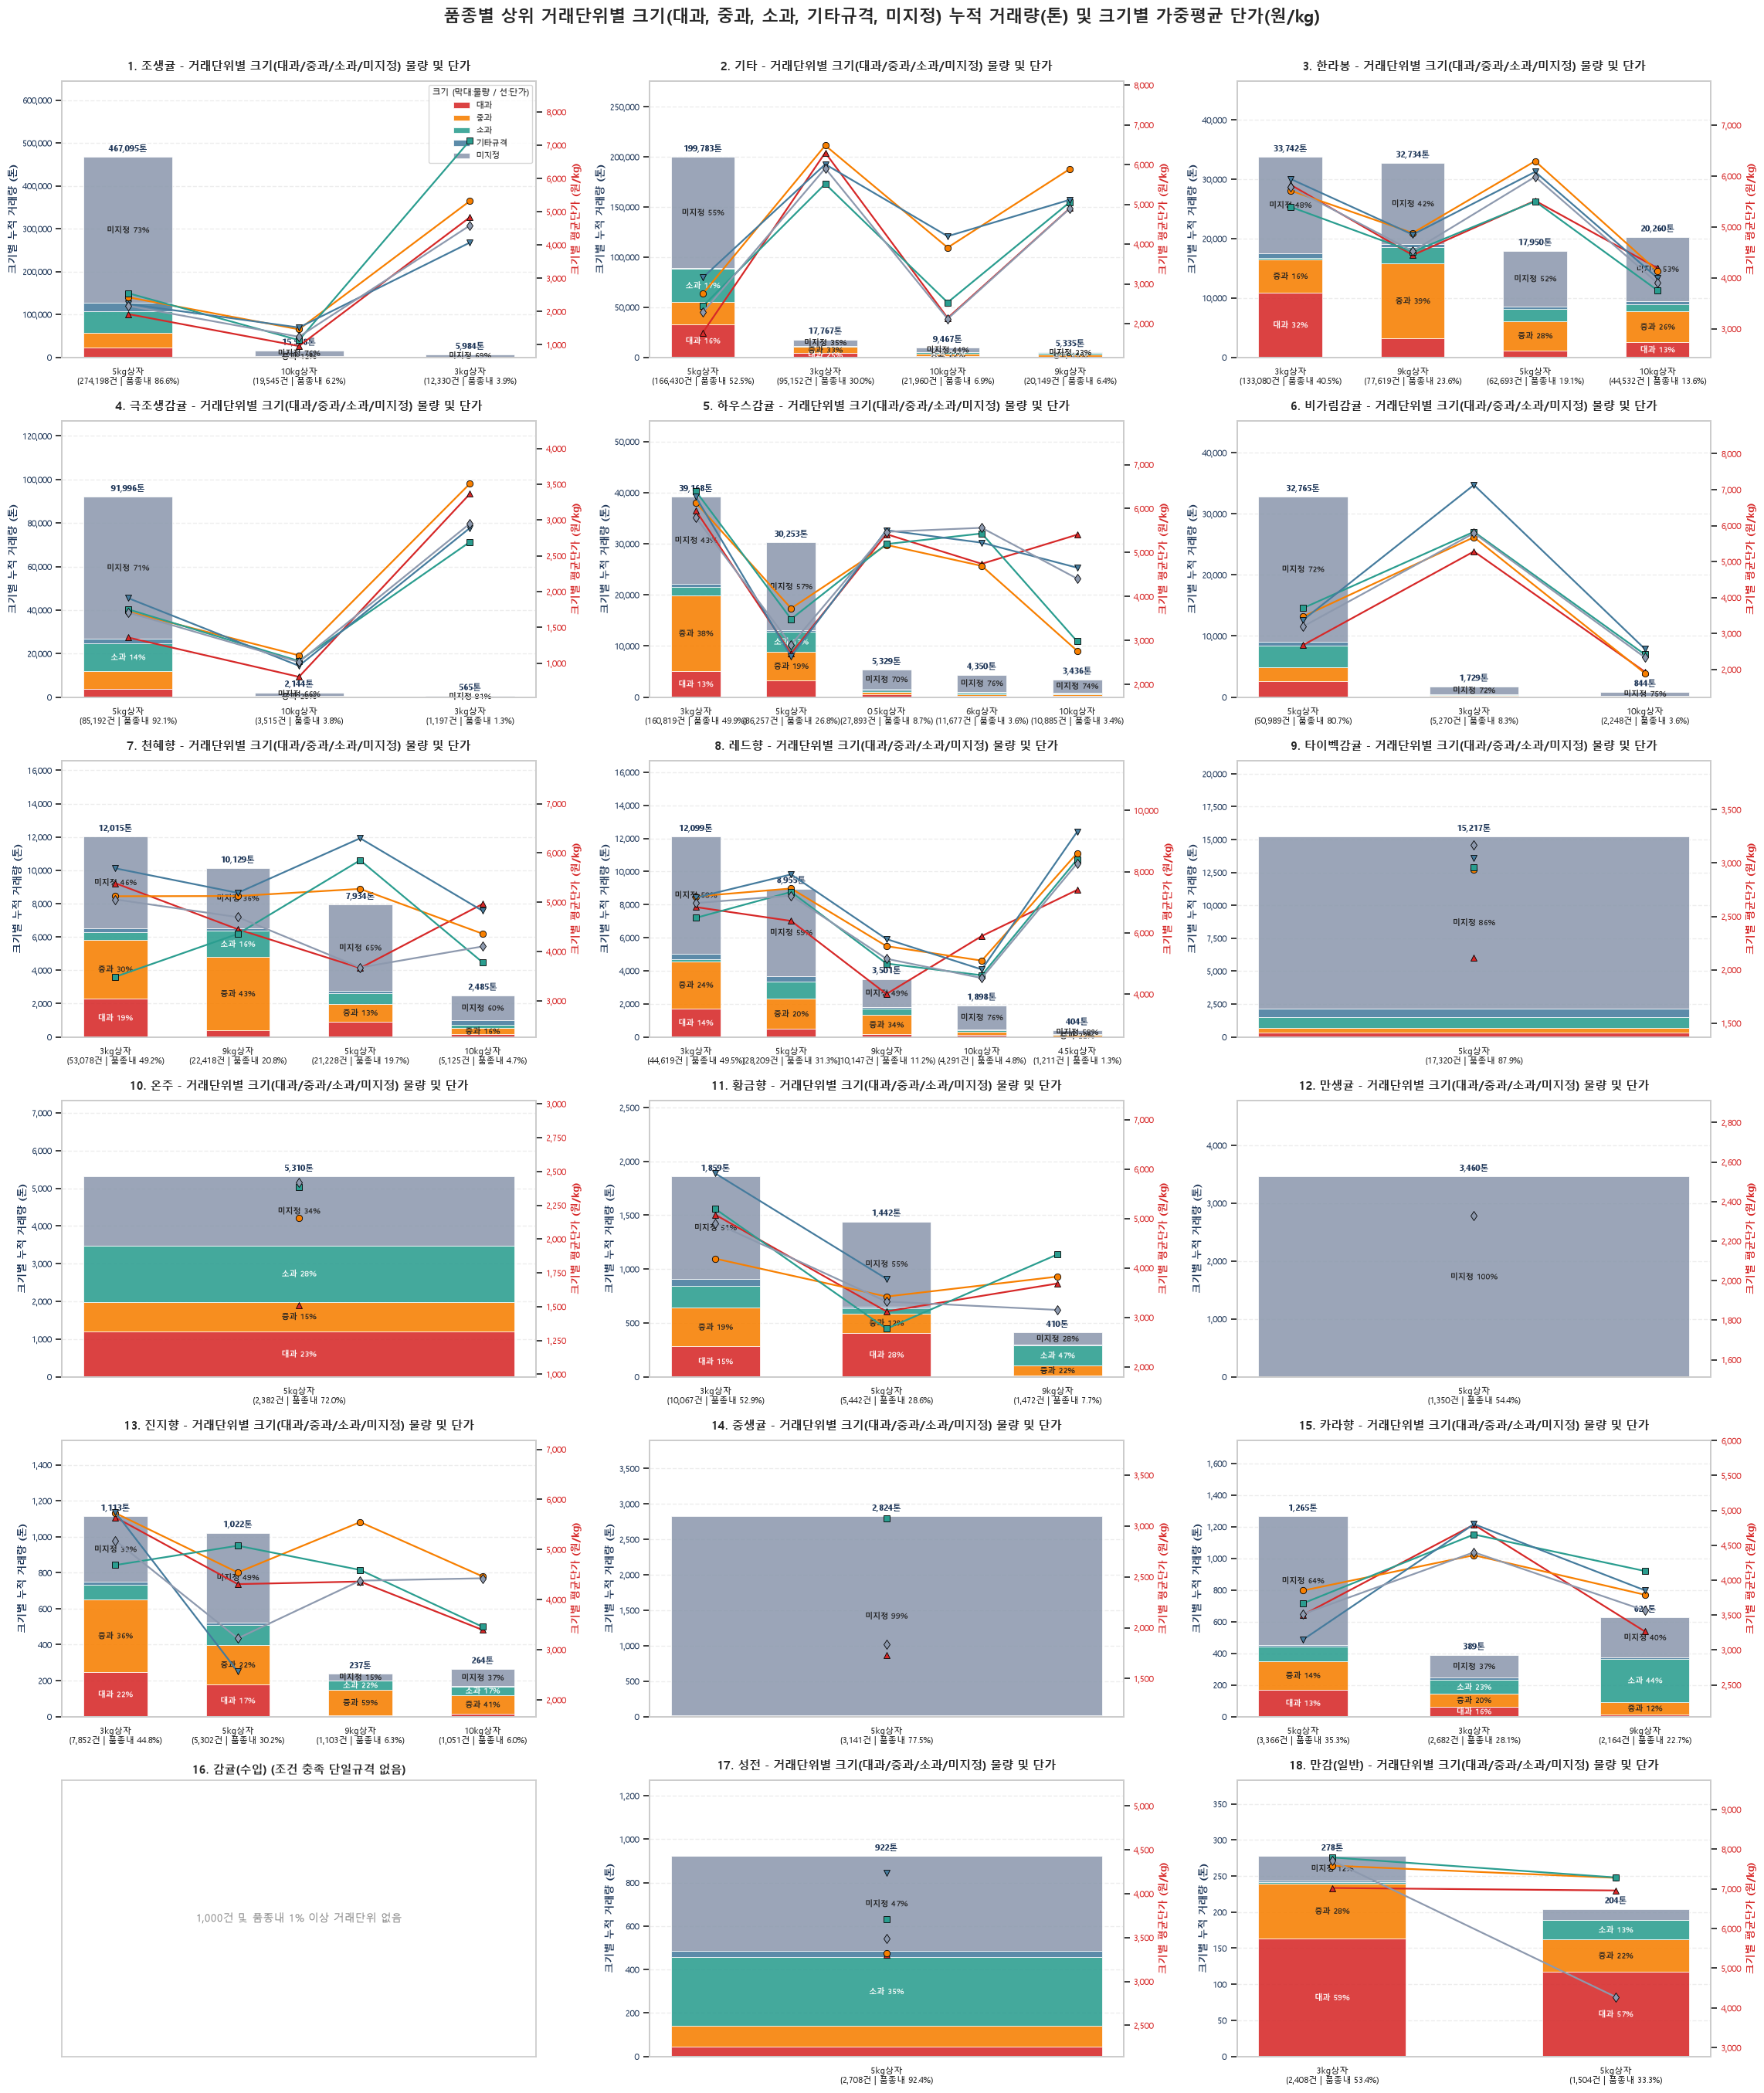

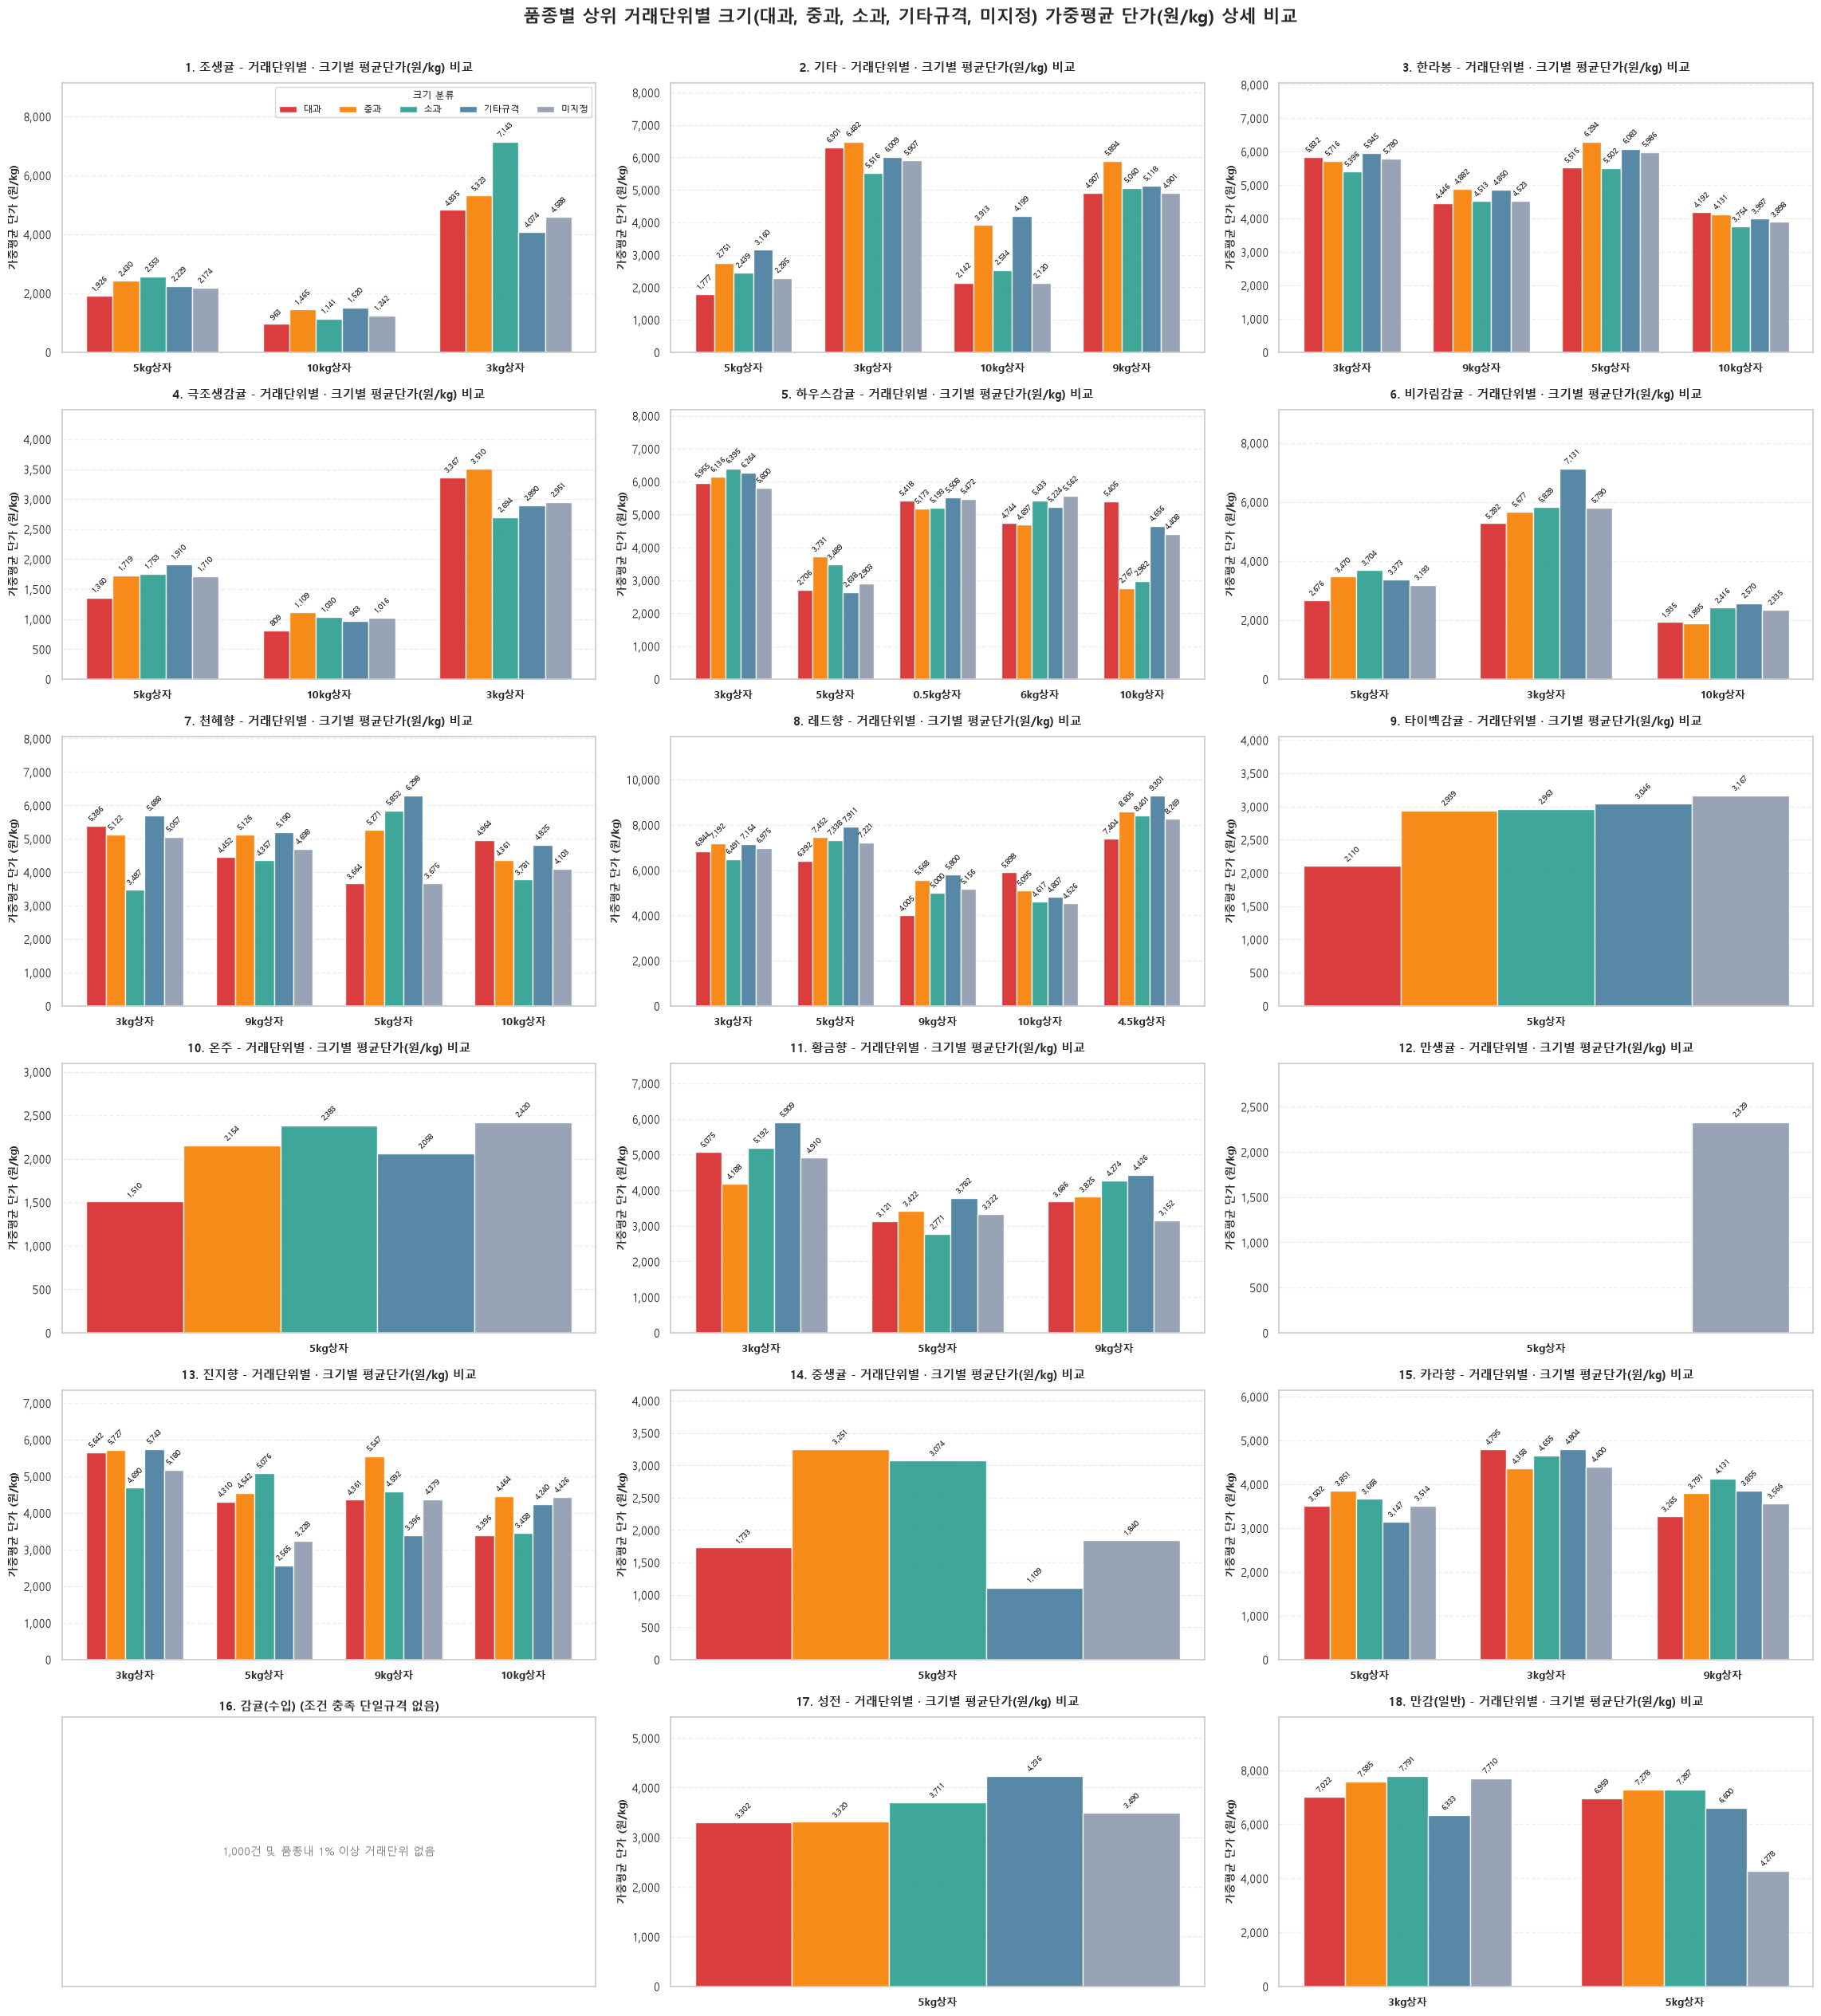

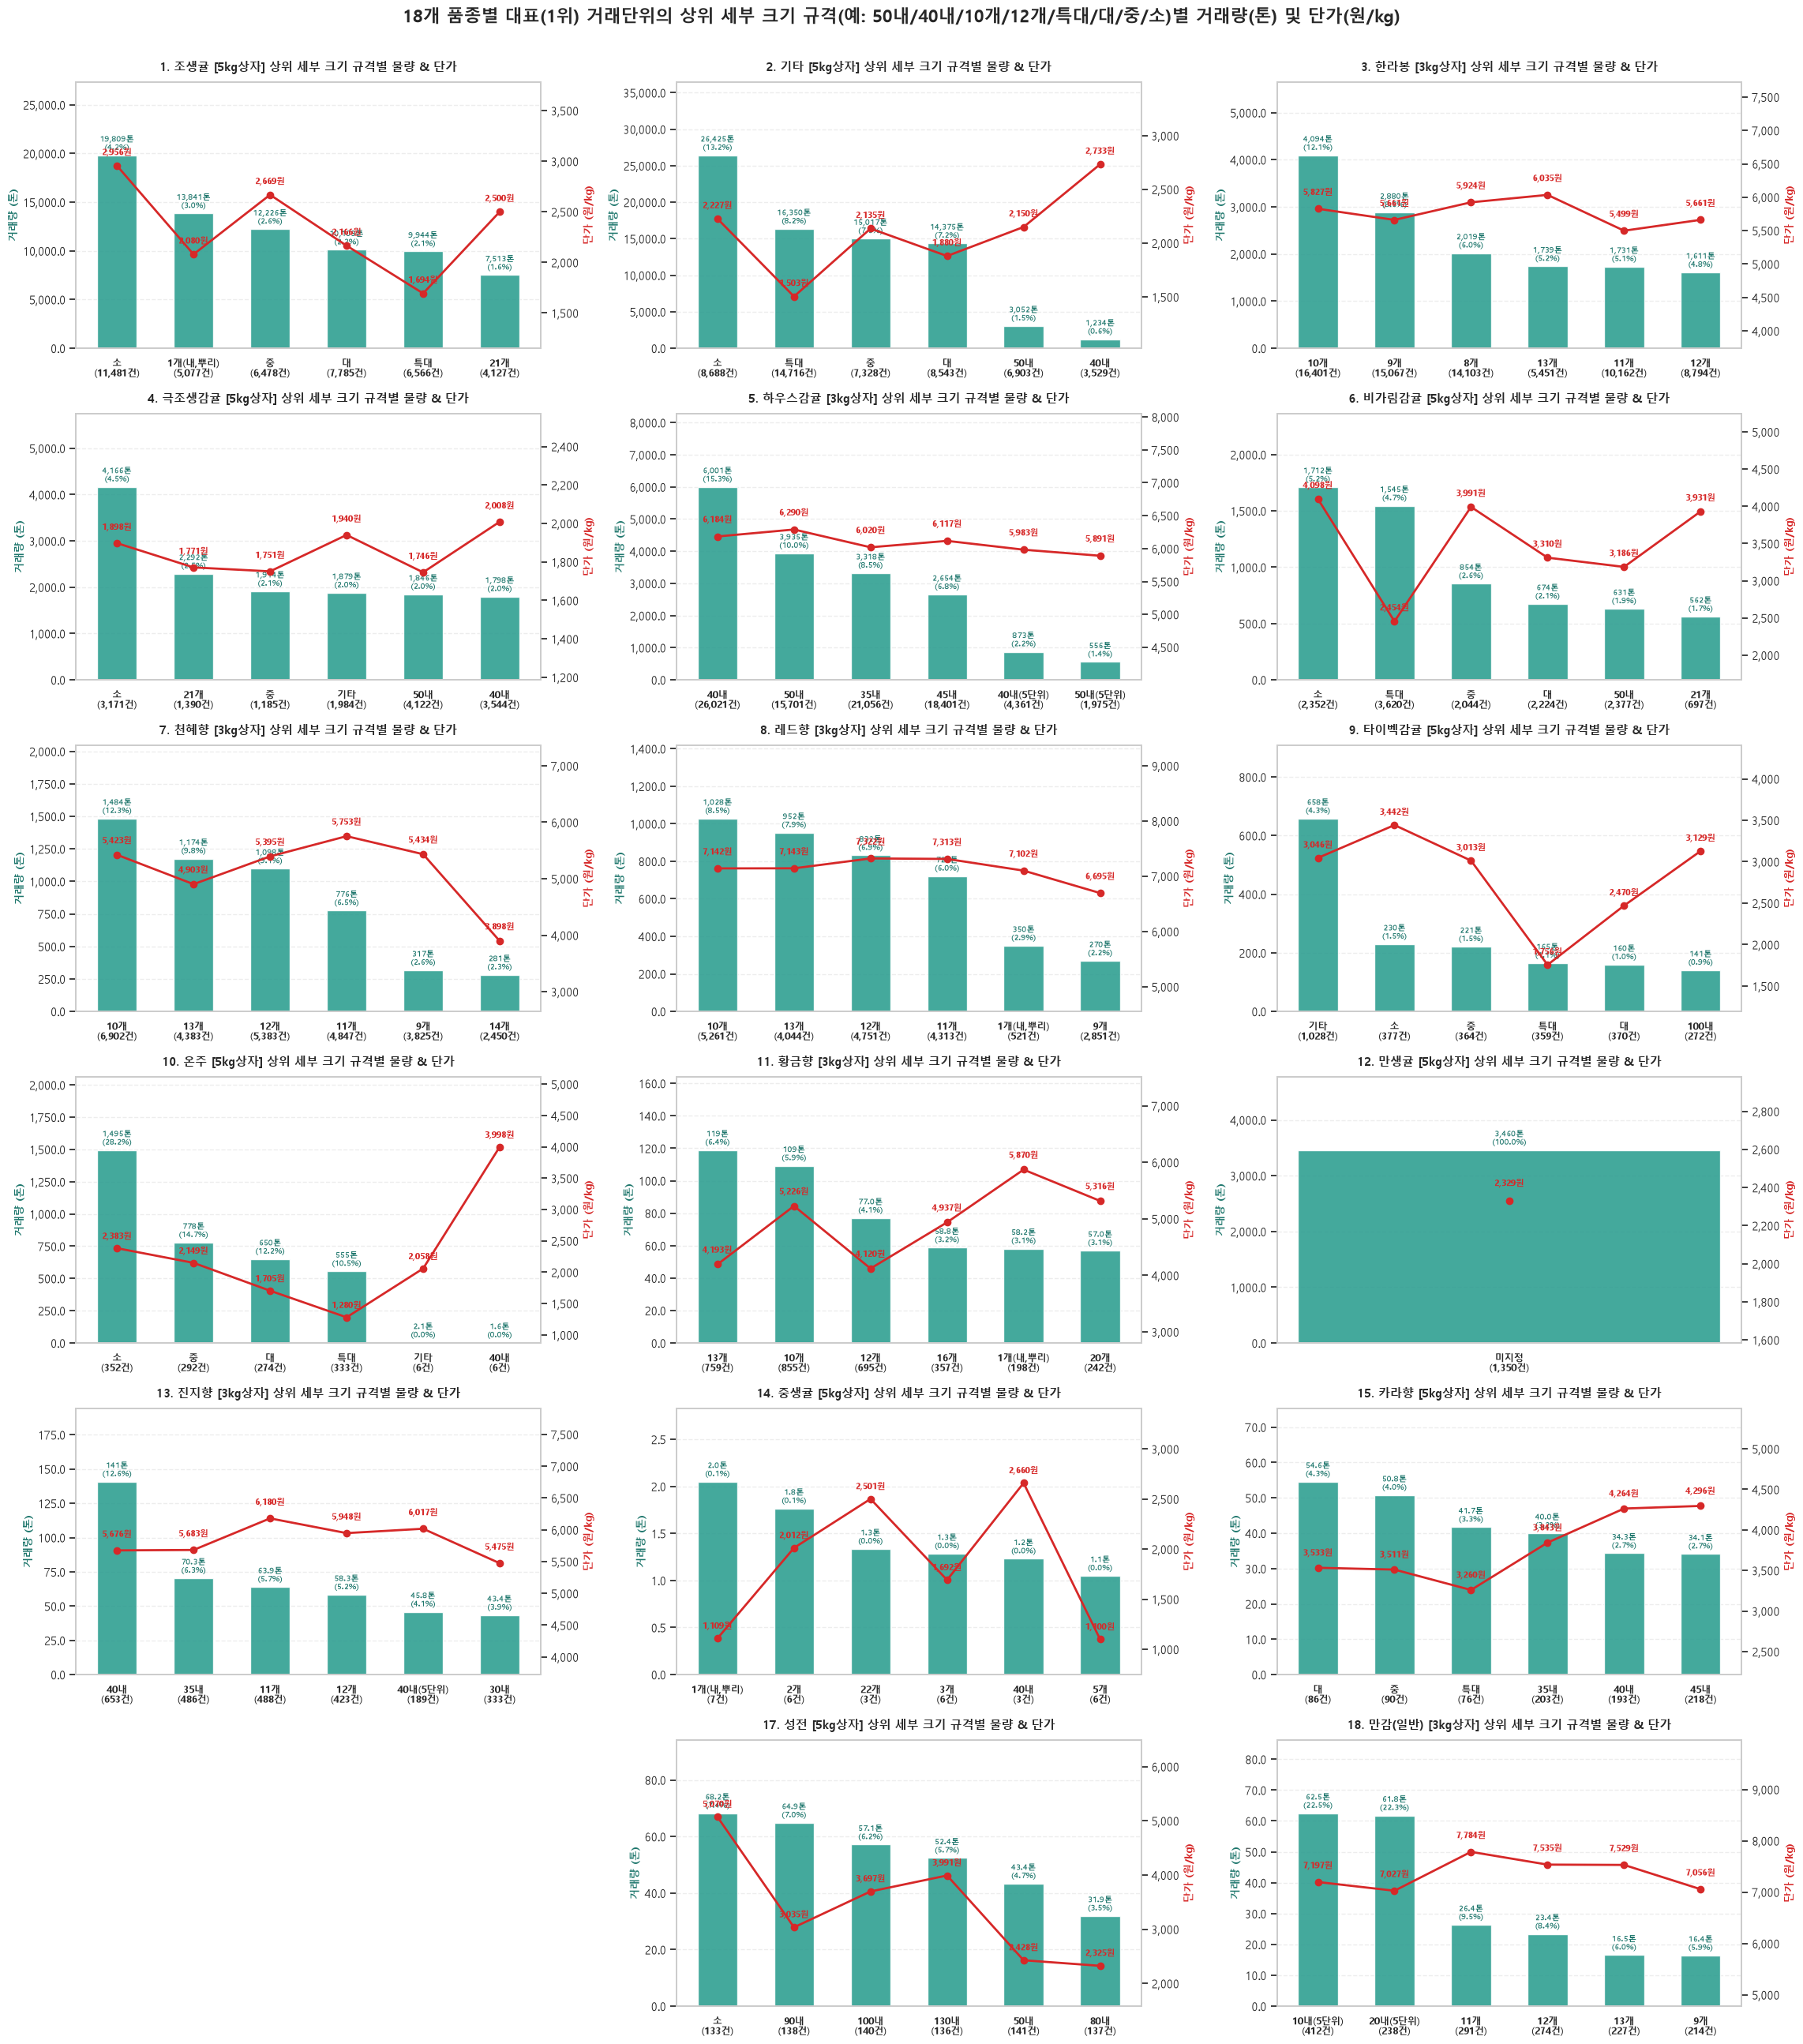

In [19]:
# 1) 감귤 크기(size, sz_nm)를 표준 5대 크기 그룹(['대과', '중과', '소과', '기타규격', '미지정'])으로 분류하는 함수 정의
import re

def map_size_5(sz):
    s = str(sz).strip()
    if s in ('미지정', '.', '', 'nan', 'None'):
        return '미지정'
    # 1. 직접 크기/호수 표기
    if s in ('특대', '대', '왕대', '2L', '3L', 'L', '대과'):
        return '대과'
    if s in ('중', 'M', '중과', '보통'):
        return '중과'
    if s in ('소', '꼬마', 'S', '2S', '3S', '소과', '극소'):
        return '소과'
    # 2. 상자당 개수 표기 (예: '10개', '12개' -> 10개 이하 대과, 11~15개 중과, 16개 이상 소과)
    m_gae = re.match(r'^(\d+)개$', s)
    if m_gae:
        n = int(m_gae.group(1))
        if n <= 10:
            return '대과'
        elif n <= 15:
            return '중과'
        else:
            return '소과'
    # 3. 상자당 과수(내) 표기 (예: '30내', '40내', '50내', '60내' -> 35내 이하 대과, 40~55내 중과, 60내 이상 소과)
    m_nae = re.match(r'^(\d+)내', s)
    if m_nae:
        n = int(m_nae.group(1))
        if n <= 35:
            return '대과'
        elif n <= 55:
            return '중과'
        else:
            return '소과'
    return '기타규격'

df['size_5'] = df['size'].apply(map_size_5)
size_order = ['대과', '중과', '소과', '기타규격', '미지정']
size_colors = {
    '대과': '#D62828',     # 진한 빨강 (대과/고단가)
    '중과': '#F77F00',     # 주황 (중과/주력 표준과)
    '소과': '#2A9D8F',     # 청록 (소과)
    '기타규격': '#457B9D', # 남청색 (특수 규격)
    '미지정': '#8D99AE'    # 회색 (크기 미지정)
}

print("[전체 데이터 표준 5대 크기 그룹(대과/중과/소과/기타규격/미지정) 분포 건수]")
print(df['size_5'].value_counts().reindex(size_order).fillna(0).astype(int))

print("\n[전체 데이터 원본 세부 크기(size) 상위 20개 분포 건수]")
print(df['size'].value_counts().head(20))

# 2) 7번 선정 품종별 상위 거래단위(48개 규격) 필터링 및 표준 5대 크기 그룹별 집계
valid_pairs = top5_units_per_variety[['variety', 'box_unit', '품종내_순위']].copy()
df_top_units_sz = df.merge(valid_pairs, on=['variety', 'box_unit'], how='inner')

unit_size_stats = (
    df_top_units_sz.groupby(['variety', '품종내_순위', 'box_unit', 'size_5'], as_index=False)
    .agg(
        거래건수=('date', 'count'),
        총거래량_kg=('volume_kg', 'sum'),
        총거래금액_원=('total_price', 'sum'),
        평균_상자당가격=('box_price', 'mean')
    )
)
unit_size_stats['거래량_톤'] = unit_size_stats['총거래량_kg'] / 1000.0
unit_size_stats['가중평균_kg단가'] = np.where(
    unit_size_stats['총거래량_kg'] > 0,
    unit_size_stats['총거래금액_원'] / unit_size_stats['총거래량_kg'],
    np.nan
)

unit_sz_tot = (
    unit_size_stats.groupby(['variety', 'box_unit'], as_index=False)
    .agg(단위총건수=('거래건수', 'sum'), 단위총물량_톤=('거래량_톤', 'sum'))
)
unit_size_stats = unit_size_stats.merge(unit_sz_tot, on=['variety', 'box_unit'], how='left')
unit_size_stats['단위내_건수비중(%)'] = (unit_size_stats['거래건수'] / unit_size_stats['단위총건수']) * 100
unit_size_stats['단위내_물량비중(%)'] = (unit_size_stats['거래량_톤'] / unit_size_stats['단위총물량_톤']) * 100

# 3) 표 1: 품종별 · 상위 거래단위별 표준 5대 크기 그룹(대과, 중과, 소과, 기타규격, 미지정) 요약 피벗 테이블
pivot_size_rows = []
for _, u_row in top5_units_per_variety.iterrows():
    v_name = u_row['variety']
    b_unit = u_row['box_unit']
    r_num = int(u_row['품종내_순위'])
    sub_s = unit_size_stats[(unit_size_stats['variety'] == v_name) & (unit_size_stats['box_unit'] == b_unit)]

    row_data = {
        '품종명': v_name,
        '순위': f"{r_num}위",
        '거래단위': b_unit,
        '단위 총거래량': f"{u_row['거래량_톤']:,.1f}톤",
        '단위 평균단가': f"{u_row['가중평균_kg단가']:,.0f}원/kg (상자 {u_row['평균_상자당가격']:,.0f}원)"
    }
    for sz_g in size_order:
        s_match = sub_s[sub_s['size_5'] == sz_g]
        if len(s_match) > 0:
            sm = s_match.iloc[0]
            row_data[f'{sz_g} (물량 / 비중 / 단가)'] = (
                f"{sm['거래량_톤']:,.1f}톤 ({sm['단위내_물량비중(%)']:.1f}%) | "
                f"{sm['가중평균_kg단가']:,.0f}원/kg (상자 {sm['평균_상자당가격']:,.0f}원)"
            )
        else:
            row_data[f'{sz_g} (물량 / 비중 / 단가)'] = "-"
    pivot_size_rows.append(row_data)

pivot_size_df = pd.DataFrame(pivot_size_rows)
print(f"\n[1. 7번 선정 품종별·거래단위별 표준 크기 그룹(대과/중과/소과/기타규격/미지정) 가격 및 거래량 요약표 (총 {len(pivot_size_df)}개 규격)]")
display(pivot_size_df)

# 4) 표 2: 품종별 · 상위 거래단위별 원본 세부 크기(size: 예 50내, 40내, 10개, 12개, 특대, 대, 중, 소 등) 상위 1~5위 상세 통계표
raw_size_stats = (
    df_top_units_sz.groupby(['variety', '품종내_순위', 'box_unit', 'size'], as_index=False)
    .agg(
        거래건수=('date', 'count'),
        총거래량_kg=('volume_kg', 'sum'),
        총거래금액_원=('total_price', 'sum'),
        평균_상자당가격=('box_price', 'mean')
    )
)
raw_size_stats['거래량_톤'] = raw_size_stats['총거래량_kg'] / 1000.0
raw_size_stats['가중평균_kg단가'] = np.where(
    raw_size_stats['총거래량_kg'] > 0,
    raw_size_stats['총거래금액_원'] / raw_size_stats['총거래량_kg'],
    np.nan
)
raw_size_stats = raw_size_stats.merge(unit_sz_tot, on=['variety', 'box_unit'], how='left')
raw_size_stats['단위내_물량비중(%)'] = (raw_size_stats['거래량_톤'] / raw_size_stats['단위총물량_톤']) * 100
raw_size_stats['단위내_건수비중(%)'] = (raw_size_stats['거래건수'] / raw_size_stats['단위총건수']) * 100

detail_size_rows = []
for _, u_row in top5_units_per_variety.iterrows():
    v_name = u_row['variety']
    b_unit = u_row['box_unit']
    r_num = int(u_row['품종내_순위'])
    sub_rs = raw_size_stats[(raw_size_stats['variety'] == v_name) & (raw_size_stats['box_unit'] == b_unit)].copy()
    # '미지정'을 별도 표기하고, 실제 지정된 세부 크기 중 거래량 상위 5개 추출
    unspec = sub_rs[sub_rs['size'] == '미지정']
    unspec_str = (
        f"{unspec['거래량_톤'].iloc[0]:,.1f}톤 ({unspec['단위내_물량비중(%)'].iloc[0]:.1f}%) | {unspec['가중평균_kg단가'].iloc[0]:,.0f}원/kg"
        if len(unspec) > 0 else "-"
    )
    spec_rs = sub_rs[sub_rs['size'] != '미지정'].sort_values('거래량_톤', ascending=False).head(5).reset_index(drop=True)

    d_row = {
        '품종명': v_name,
        '순위': f"{r_num}위",
        '거래단위': b_unit,
        '미지정 크기 (물량/비중/단가)': unspec_str
    }
    for k in range(5):
        if k < len(spec_rs):
            sr = spec_rs.iloc[k]
            d_row[f'크기 {k+1}위 (규격명: 물량 / 비중 / 단가 / 상자가)'] = (
                f"[{sr['size']}] {sr['거래량_톤']:,.1f}톤 ({sr['단위내_물량비중(%)']:.1f}%) | "
                f"{sr['가중평균_kg단가']:,.0f}원/kg (상자 {sr['평균_상자당가격']:,.0f}원)"
            )
        else:
            d_row[f'크기 {k+1}위 (규격명: 물량 / 비중 / 단가 / 상자가)'] = "-"
    detail_size_rows.append(d_row)

detail_size_df = pd.DataFrame(detail_size_rows)
print(f"\n[2. 품종별·거래단위별 실제 거래 상위 1~5위 세부 크기 규격(50내/40내/10개/12개/특대/대/중/소 등) 상세 통계표]")
display(detail_size_df)

# 5) 그래프 1: 품종별 · 상위 거래단위별 크기 그룹(대과/중과/소과/기타규격/미지정) 누적 거래량(톤) 및 크기별 평균단가(원/kg) (6행 x 3열)
ncols_s = 3
nrows_s = int(np.ceil(len(variety_order) / ncols_s))
fig, axes = plt.subplots(nrows_s, ncols_s, figsize=(23, nrows_s * 4.5))
axes = axes.flatten()

for idx, var_name in enumerate(variety_order):
    ax1 = axes[idx]
    sub_u = top5_units_per_variety[top5_units_per_variety['variety'] == var_name].copy()

    if len(sub_u) == 0:
        ax1.set_title(f"{idx + 1}. {var_name} (조건 충족 단일규격 없음)", fontsize=11, fontweight='bold')
        ax1.text(0.5, 0.5, '1,000건 및 품종내 1% 이상 거래단위 없음', ha='center', va='center', fontsize=10, color='gray')
        ax1.set_xticks([])
        ax1.set_yticks([])
        continue

    units = sub_u['box_unit'].tolist()
    x_pos = np.arange(len(units))
    bottom_vals = np.zeros(len(units))

    for sz_g in size_order:
        s_vols, s_pcts = [], []
        for u in units:
            m = unit_size_stats[
                (unit_size_stats['variety'] == var_name) &
                (unit_size_stats['box_unit'] == u) &
                (unit_size_stats['size_5'] == sz_g)
            ]
            s_vols.append(m['거래량_톤'].iloc[0] if len(m) > 0 else 0.0)
            s_pcts.append(m['단위내_물량비중(%)'].iloc[0] if len(m) > 0 else 0.0)
        s_vols = np.array(s_vols)
        ax1.bar(
            x_pos, s_vols, bottom=bottom_vals,
            color=size_colors[sz_g], alpha=0.88, width=0.52,
            edgecolor='white', linewidth=0.6, label=f"{sz_g}(물량)"
        )
        for xi, (v_val, p_val, b_val) in enumerate(zip(s_vols, s_pcts, bottom_vals)):
            if p_val >= 12.0:
                ax1.text(
                    xi, b_val + v_val / 2, f"{sz_g} {p_val:.0f}%",
                    ha='center', va='center', fontsize=7.3, fontweight='bold',
                    color='white' if sz_g in ('대과', '소과', '기타규격') else '#222222'
                )
        bottom_vals += s_vols

    max_tot_v = bottom_vals.max()
    ax1.set_ylim(0, max_tot_v * 1.38 if max_tot_v > 0 else 1)
    for xi, tot_v in enumerate(bottom_vals):
        if tot_v > 0:
            vol_str = f"{tot_v:,.0f}톤" if tot_v >= 100 else f"{tot_v:,.1f}톤"
            ax1.text(xi, tot_v + (max_tot_v * 0.02), vol_str, ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1D3557')

    ax1.set_title(f"{idx + 1}. {var_name} - 거래단위별 크기(대과/중과/소과/미지정) 물량 및 단가", fontsize=11, fontweight='bold', pad=10)
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels([f"{row['box_unit']}\n({row['거래건수']:,.0f}건 | 품종내 {row['품종내_건수비중(%)']:.1f}%)" for _, row in sub_u.iterrows()], fontsize=8.2)
    ax1.set_ylabel('크기별 누적 거래량 (톤)', color='#1D3557', fontsize=9, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='#1D3557', labelsize=8)
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax1.grid(axis='y', linestyle='--', alpha=0.35)
    ax1.grid(axis='x', visible=False)

    ax2 = ax1.twinx()
    all_prcs = []
    size_markers = {'대과': '^', '중과': 'o', '소과': 's', '기타규격': 'v', '미지정': 'd'}
    for sz_g in size_order:
        s_prcs = []
        for u in units:
            m = unit_size_stats[
                (unit_size_stats['variety'] == var_name) &
                (unit_size_stats['box_unit'] == u) &
                (unit_size_stats['size_5'] == sz_g)
            ]
            val = m['가중평균_kg단가'].iloc[0] if len(m) > 0 and m['거래건수'].iloc[0] >= 10 else np.nan
            s_prcs.append(val)
            if pd.notnull(val):
                all_prcs.append(val)
        ax2.plot(
            x_pos, s_prcs, color=size_colors[sz_g], marker=size_markers[sz_g],
            markersize=6, linewidth=1.6, linestyle='-',
            markeredgecolor='black', markeredgewidth=0.6, label=f"{sz_g}(단가)"
        )

    ax2.set_ylabel('크기별 평균단가 (원/kg)', color='#D62828', fontsize=9, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='#D62828', labelsize=8)
    ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax2.grid(False)
    if len(all_prcs) > 0:
        ax2.set_ylim(max(0, min(all_prcs) * 0.65), max(all_prcs) * 1.25)

    if idx == 0:
        handles1, _ = ax1.get_legend_handles_labels()
        ax1.legend(handles1, size_order, title='크기 (막대:물량 / 선:단가)', loc='upper right', fontsize=7.5, title_fontsize=8)

for j in range(len(variety_order), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('품종별 상위 거래단위별 크기(대과, 중과, 소과, 기타규격, 미지정) 누적 거래량(톤) 및 크기별 가중평균 단가(원/kg)', fontsize=16, fontweight='bold', y=1.003)
plt.tight_layout()
plt.show()

# 6) 그래프 2: 품종별 · 상위 거래단위별 크기 그룹(대과, 중과, 소과, 기타규격, 미지정) 가중평균 단가(원/kg) 그룹 막대그래프 비교 (6행 x 3열)
fig2, axes2 = plt.subplots(nrows_s, ncols_s, figsize=(23, nrows_s * 4.2))
axes2 = axes2.flatten()

bar_w = 0.15
offsets = np.linspace(-2 * bar_w, 2 * bar_w, len(size_order))

for idx, var_name in enumerate(variety_order):
    ax = axes2[idx]
    sub_u = top5_units_per_variety[top5_units_per_variety['variety'] == var_name].copy()

    if len(sub_u) == 0:
        ax.set_title(f"{idx + 1}. {var_name} (조건 충족 단일규격 없음)", fontsize=11, fontweight='bold')
        ax.text(0.5, 0.5, '1,000건 및 품종내 1% 이상 거래단위 없음', ha='center', va='center', fontsize=10, color='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        continue

    units = sub_u['box_unit'].tolist()
    x_pos = np.arange(len(units))
    max_p_var = 0

    for s_idx, sz_g in enumerate(size_order):
        s_prcs = []
        for u in units:
            m = unit_size_stats[
                (unit_size_stats['variety'] == var_name) &
                (unit_size_stats['box_unit'] == u) &
                (unit_size_stats['size_5'] == sz_g)
            ]
            val = m['가중평균_kg단가'].iloc[0] if len(m) > 0 else 0.0
            s_prcs.append(val)
            if val > max_p_var:
                max_p_var = val

        bars = ax.bar(x_pos + offsets[s_idx], s_prcs, width=bar_w, color=size_colors[sz_g], alpha=0.9, label=sz_g)
        for bar in bars:
            h = bar.get_height()
            if h > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, h + (max_p_var * 0.015), f"{h:,.0f}", ha='center', va='bottom', fontsize=6.5, rotation=45, color='#222222')

    ax.set_title(f"{idx + 1}. {var_name} - 거래단위별 · 크기별 평균단가(원/kg) 비교", fontsize=11, fontweight='bold', pad=10)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(units, fontsize=9, fontweight='bold')
    ax.set_ylabel('가중평균 단가 (원/kg)', fontsize=9, fontweight='bold')
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax.set_ylim(0, max_p_var * 1.28 if max_p_var > 0 else 1)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.grid(axis='x', visible=False)
    if idx == 0:
        ax.legend(title='크기 분류', loc='upper right', fontsize=8, title_fontsize=8.5, ncol=5)

for j in range(len(variety_order), len(axes2)):
    axes2[j].set_visible(False)

fig2.suptitle('품종별 상위 거래단위별 크기(대과, 중과, 소과, 기타규격, 미지정) 가중평균 단가(원/kg) 상세 비교', fontsize=16, fontweight='bold', y=1.003)
plt.tight_layout()
plt.show()

# 7) 그래프 3: 18개 품종별 주력 1위 거래단위의 세부 크기 규격(Top 6 실제 크기 명칭)별 거래량(톤) 및 단가(원/kg) 비교 (6행 x 3열)
fig3, axes3 = plt.subplots(nrows_s, ncols_s, figsize=(23, nrows_s * 4.3))
axes3 = axes3.flatten()

for idx, var_name in enumerate(variety_order):
    ax1 = axes3[idx]
    sub_u = top5_units_per_variety[top5_units_per_variety['variety'] == var_name]
    if len(sub_u) == 0:
        ax1.set_visible(False)
        continue
    top1_unit = sub_u.iloc[0]['box_unit']
    sub_rs = raw_size_stats[
        (raw_size_stats['variety'] == var_name) &
        (raw_size_stats['box_unit'] == top1_unit) &
        (raw_size_stats['size'] != '미지정')
    ].sort_values('거래량_톤', ascending=False).head(6).reset_index(drop=True)

    if len(sub_rs) == 0:
        sub_rs = raw_size_stats[
            (raw_size_stats['variety'] == var_name) &
            (raw_size_stats['box_unit'] == top1_unit)
        ].sort_values('거래량_톤', ascending=False).head(6).reset_index(drop=True)

    x_p = np.arange(len(sub_rs))
    bars = ax1.bar(x_p, sub_rs['거래량_톤'], width=0.52, color='#2A9D8F', alpha=0.88, label='세부 크기별 거래량(톤)')
    max_rv = sub_rs['거래량_톤'].max() if len(sub_rs) > 0 else 1.0
    ax1.set_ylim(0, max_rv * 1.38 if max_rv > 0 else 1)
    for bar, (_, r_row) in zip(bars, sub_rs.iterrows()):
        h = bar.get_height()
        if h > 0:
            v_txt = f"{h:,.0f}톤" if h >= 100 else f"{h:,.1f}톤"
            ax1.text(bar.get_x() + bar.get_width()/2, h + max_rv*0.02, f"{v_txt}\n({r_row['단위내_물량비중(%)']:.1f}%)", ha='center', va='bottom', fontsize=7.5, fontweight='bold', color='#1F776D')

    ax1.set_title(f"{idx + 1}. {var_name} [{top1_unit}] 상위 세부 크기 규격별 물량 & 단가", fontsize=11, fontweight='bold', pad=10)
    ax1.set_xticks(x_p)
    ax1.set_xticklabels([f"{r['size']}\n({r['거래건수']:,.0f}건)" for _, r in sub_rs.iterrows()], fontsize=8.5, fontweight='bold')
    ax1.set_ylabel('거래량 (톤)', color='#1F776D', fontsize=9, fontweight='bold')
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.1f}'))
    ax1.grid(axis='y', linestyle='--', alpha=0.35)
    ax1.grid(axis='x', visible=False)

    ax2 = ax1.twinx()
    ax2.plot(x_p, sub_rs['가중평균_kg단가'], color='#D62828', marker='o', linewidth=2.0, markersize=6, label='가중평균 단가(원/kg)')
    ax2.set_ylabel('단가 (원/kg)', color='#D62828', fontsize=9, fontweight='bold')
    ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax2.grid(False)
    if len(sub_rs) > 0:
        min_rp, max_rp = sub_rs['가중평균_kg단가'].min(), sub_rs['가중평균_kg단가'].max()
        ax2.set_ylim(max(0, min_rp * 0.68), max_rp * 1.28)
        for xi, pv in enumerate(sub_rs['가중평균_kg단가']):
            ax2.text(xi, pv + max_rp * 0.03, f"{pv:,.0f}원", ha='center', va='bottom', fontsize=8, fontweight='bold', color='#D62828')

for j in range(len(variety_order), len(axes3)):
    axes3[j].set_visible(False)

fig3.suptitle('18개 품종별 대표(1위) 거래단위의 상위 세부 크기 규격(예: 50내/40내/10개/12개/특대/대/중/소)별 거래량(톤) 및 단가(원/kg)', fontsize=15.5, fontweight='bold', y=1.003)
plt.tight_layout()
plt.show()

## 10. 거래시장별 · 각각의 품종별 거래량 및 거래가격 분석
- 전국 **모든 공영도매시장(`whsl_mrkt_nm`)** 및 **5대 주요 도매시장(서울가락시장, 대구북부시장, 부산반여시장, 경기구리시장, 부산엄궁시장)**에 대해 **각각의 품종별 거래량(톤)과 거래가격(가중평균 원/kg · 평균 상자당 가격)**을 집계하고 시각화합니다.
- 거래시장별 전체 감귤 거래량 순위, 시장별 × 품종별 거래량(톤) 및 거래가격(원/kg) 교차표, 그리고 5대 주요 도매시장별 품종별 거래량·거래가격 비교 그래프를 제공합니다.

[10-1] 전국 전체 거래시장(32개 시장) 종합 거래량 및 거래가격 요약


,순위,거래시장명,취급품종수,거래건수,누적 거래량(톤),거래량 비중(%),총 거래금액(억원),가중평균 거래가격(원/kg),평균 상자당 가격(원)
0,1,서울가락,17 종,"258,448 건","282,806.3 톤",24.13%,"9,058.9 억원","3,203 원","23,009 원"
1,2,대구북부,16 종,"148,502 건","113,404.9 톤",9.68%,"3,414.1 억원","3,011 원","18,459 원"
2,3,구리,13 종,"111,959 건","80,361.8 톤",6.86%,"2,396.9 억원","2,983 원","20,467 원"
3,4,광주서부,15 종,"59,715 건","60,415.3 톤",5.16%,"1,959.0 억원","3,243 원","17,627 원"
4,5,서울강서,13 종,"71,984 건","53,809.3 톤",4.59%,"1,404.2 억원","2,610 원","16,842 원"
5,6,부산엄궁,14 종,"77,608 건","49,909.7 톤",4.26%,"1,294.0 억원","2,593 원","18,790 원"
6,7,부산반여,14 종,"73,234 건","49,154.6 톤",4.19%,"1,447.6 억원","2,945 원","19,401 원"
7,8,대전오정,14 종,"54,261 건","45,514.4 톤",3.88%,"1,358.1 억원","2,984 원","19,122 원"
8,9,광주각화,13 종,"72,669 건","44,125.9 톤",3.77%,"1,309.8 억원","2,968 원","17,256 원"
9,10,인천남촌,15 종,"58,672 건","41,137.9 톤",3.51%,"1,160.4 억원","2,821 원","19,011 원"



[10-2] 전체 거래시장별 × 각각의 품종별 누적 거래량 (톤)


variety,조생귤,기타,한라봉,극조생감귤,하우스감귤,비가림감귤,천혜향,레드향,타이벡감귤,온주,황금향,만생귤,진지향,중생귤,카라향,감귤(수입),성전,만감(일반)
whsl_mrkt_nm,,,,,,,,,,,,,,,,,,
서울가락,"101,902.3","66,514.6","36,446.7","19,265.9","25,184.5","8,928.7","9,264.2","4,904.6","3,768.9","3,681.1","1,159.6",0.8,625.9,0.9,775.0,243.6,139.3,0.0
대구북부,"54,179.0","16,196.6","10,631.2","9,759.6","9,352.1","4,839.8","2,163.7","2,387.7","2,782.0",0.0,415.9,12.5,305.1,0.0,256.1,56.3,55.6,11.9
구리,"26,472.7","25,379.9","8,604.0",945.7,"5,263.9","3,839.5","3,680.4","2,377.7","2,915.1",0.0,286.4,0.0,123.1,0.0,342.7,130.8,0.0,0.0
광주서부,"35,064.2","2,954.0","4,690.8","2,997.3","6,033.4","2,175.9","1,598.4","4,082.3",161.1,0.0,284.1,9.0,96.0,0.0,255.3,12.1,1.4,0.0
서울강서,"14,989.0","22,975.5","4,012.3","4,770.1","3,264.0","1,947.9",775.8,676.2,0.0,0.0,244.9,0.0,89.2,1.6,57.7,0.0,0.0,4.9
부산엄궁,"24,229.4","5,837.0","2,566.9","7,989.4","4,646.7","1,262.8","1,715.3",888.5,263.4,0.0,207.7,0.0,112.1,0.0,157.6,32.9,0.0,0.1
부산반여,"26,656.9","3,551.5","3,962.4","3,742.3","4,793.3","1,154.3","1,254.1",440.0,838.1,0.0,57.4,0.0,93.7,"2,407.8",105.8,96.9,0.0,0.0
대전오정,"25,091.3",742.5,"2,757.6","8,947.3","2,697.0","1,368.5","2,092.8","1,225.5",92.5,0.0,191.3,0.0,42.5,0.0,109.4,152.2,4.0,0.0
광주각화,"27,183.6","4,138.4","2,384.2","3,020.7","3,739.5","1,312.5",289.4,"1,791.3",0.0,0.0,146.6,0.0,50.1,11.2,55.7,0.0,2.8,0.0



[10-3] 전체 거래시장별 × 각각의 품종별 가중평균 거래가격 (원/kg)


variety,조생귤,기타,한라봉,극조생감귤,하우스감귤,비가림감귤,천혜향,레드향,타이벡감귤,온주,황금향,만생귤,진지향,중생귤,카라향,감귤(수입),성전,만감(일반)
whsl_mrkt_nm,,,,,,,,,,,,,,,,,,
서울가락,"2,310","2,537","5,327","1,671","5,281","3,741","4,730","6,722","3,022","2,115","4,349","7,132","4,882","7,000","3,968","5,343","4,525",-
대구북부,"2,384","2,142","5,289","1,716","4,794","3,797","4,859","6,819","3,520",-,"4,157","4,080","4,905",-,"3,828","4,847","3,703","4,569"
구리,"2,035","2,106","5,125","1,855","4,874","3,288","5,350","6,841","2,988",-,"4,152",-,"4,366",-,"3,815","4,235",-,-
광주서부,"2,318","4,065","4,809","1,841","4,868","3,451","5,004","6,498","2,479",-,"4,587","3,642","4,510",-,"3,496","5,129","3,252",-
서울강서,"1,843","2,531","4,632","1,495","4,407","2,812","4,197","6,383",-,-,"3,765",-,"4,034",978,"3,185",-,-,"4,000"
부산엄궁,"1,897","3,227","4,454","1,570","4,358","2,958","4,825","6,539","2,525",-,"3,314",-,"4,188",-,"3,816","4,061",-,"3,000"
부산반여,"2,139","5,178","5,154","1,628","4,595","3,215","4,964","6,327","3,279",-,"3,610",-,"3,628","1,647","3,719","4,529",-,-
대전오정,"2,346","6,921","5,045","2,008","5,058","3,334","5,247","6,902","3,165",-,"3,754",-,"3,454",-,"3,751","4,758","2,465",-
광주각화,"2,388","3,259","4,525","1,654","4,954","3,162","3,723","6,710",-,-,"3,854",-,"3,920","1,007","4,515",-,"2,081",-



[10-4] 전체시장 및 5대 주요 도매시장별 × 품종별 누적 거래량 (톤)


시장명,전체시장,서울가락시장,대구북부시장,부산반여시장,경기구리시장,부산엄궁시장
variety,,,,,,
조생귤,"500,214.2 톤","101,902.3 톤","54,179.0 톤","26,656.9 톤","26,472.7 톤","24,229.4 톤"
기타,"236,888.9 톤","66,514.6 톤","16,196.6 톤","3,551.5 톤","25,379.9 톤","5,837.0 톤"
한라봉,"107,411.9 톤","36,446.7 톤","10,631.2 톤","3,962.4 톤","8,604.0 톤","2,566.9 톤"
극조생감귤,"97,957.6 톤","19,265.9 톤","9,759.6 톤","3,742.3 톤",945.7 톤,"7,989.4 톤"
하우스감귤,"89,987.6 톤","25,184.5 톤","9,352.1 톤","4,793.3 톤","5,263.9 톤","4,646.7 톤"
비가림감귤,"36,655.7 톤","8,928.7 톤","4,839.8 톤","1,154.3 톤","3,839.5 톤","1,262.8 톤"
천혜향,"34,270.8 톤","9,264.2 톤","2,163.7 톤","1,254.1 톤","3,680.4 톤","1,715.3 톤"
레드향,"27,305.4 톤","4,904.6 톤","2,387.7 톤",440.0 톤,"2,377.7 톤",888.5 톤
타이벡감귤,"16,247.4 톤","3,768.9 톤","2,782.0 톤",838.1 톤,"2,915.1 톤",263.4 톤



[10-5] 전체시장 및 5대 주요 도매시장별 × 품종별 가중평균 거래가격 (원/kg)


시장명,전체시장,서울가락시장,대구북부시장,부산반여시장,경기구리시장,부산엄궁시장
variety,,,,,,
조생귤,"2,233 원","2,310 원","2,384 원","2,139 원","2,035 원","1,897 원"
기타,"2,699 원","2,537 원","2,142 원","5,178 원","2,106 원","3,227 원"
한라봉,"5,144 원","5,327 원","5,289 원","5,154 원","5,125 원","4,454 원"
극조생감귤,"1,721 원","1,671 원","1,716 원","1,628 원","1,855 원","1,570 원"
하우스감귤,"4,869 원","5,281 원","4,794 원","4,595 원","4,874 원","4,358 원"
비가림감귤,"3,381 원","3,741 원","3,797 원","3,215 원","3,288 원","2,958 원"
천혜향,"4,729 원","4,730 원","4,859 원","4,964 원","5,350 원","4,825 원"
레드향,"6,722 원","6,722 원","6,819 원","6,327 원","6,841 원","6,539 원"
타이벡감귤,"3,127 원","3,022 원","3,520 원","3,279 원","2,988 원","2,525 원"


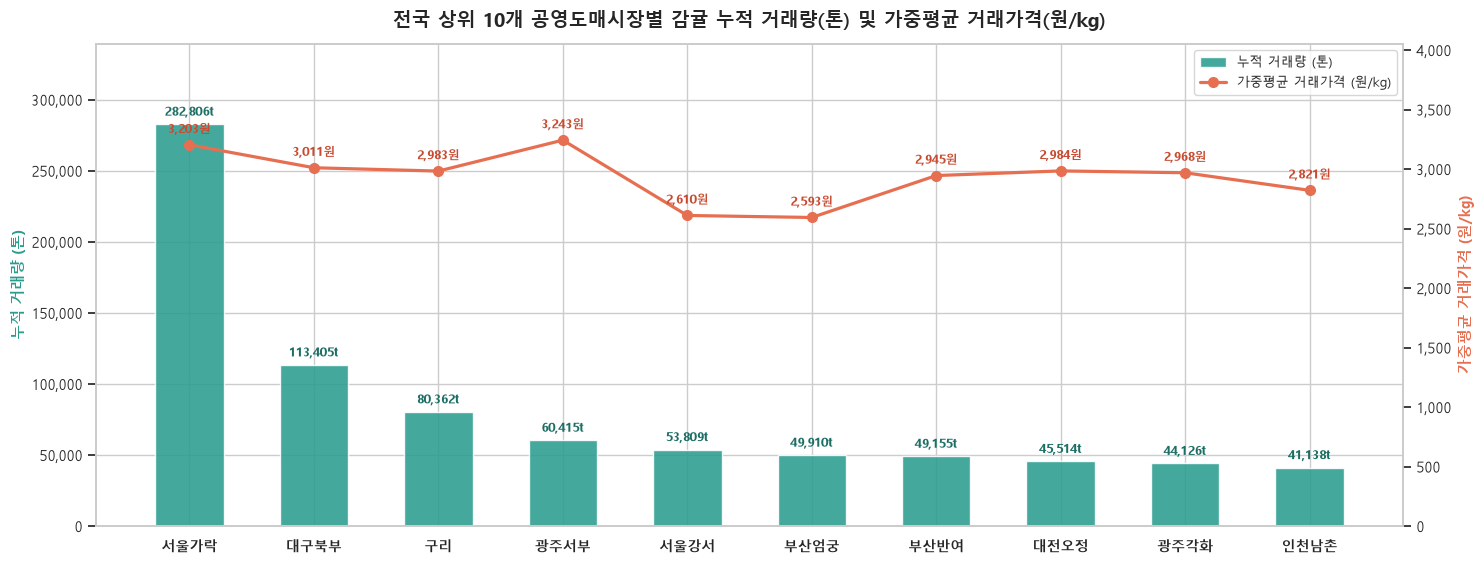

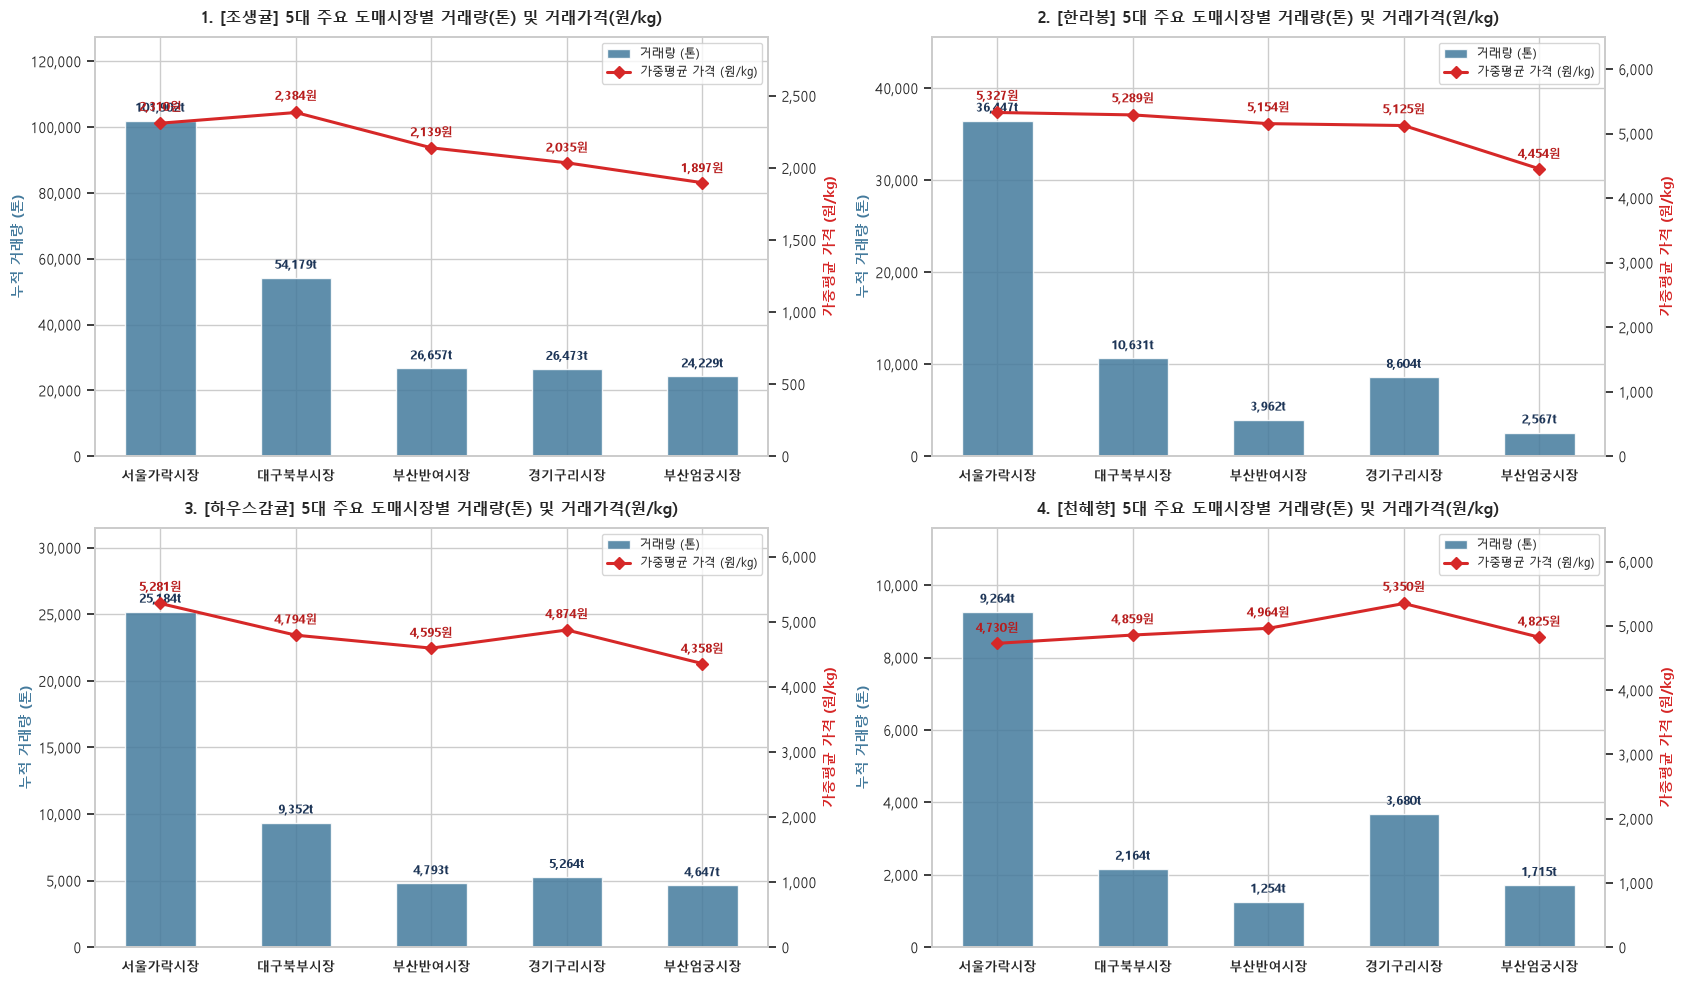

In [20]:
# 1) 전국 모든 거래시장별 종합 거래량 및 평균 거래가격 요약 (거래량 내림차순)
mkt_summary = (
    df.groupby('whsl_mrkt_nm', as_index=False)
    .agg(
        거래건수=('date', 'count'),
        취급품종수=('variety', 'nunique'),
        총거래량_kg=('volume_kg', 'sum'),
        총거래금액_원=('total_price', 'sum'),
        평균_상자당가격=('box_price', 'mean'),
    )
)
mkt_summary['거래량_톤'] = mkt_summary['총거래량_kg'] / 1000.0
mkt_summary['거래량_비중(%)'] = mkt_summary['총거래량_kg'] / mkt_summary['총거래량_kg'].sum() * 100.0
mkt_summary['총거래금액_억원'] = mkt_summary['총거래금액_원'] / 1e8
mkt_summary['가중평균_kg단가'] = mkt_summary['총거래금액_원'] / (mkt_summary['총거래량_kg'] + 1e-8)
mkt_summary = mkt_summary.sort_values('거래량_톤', ascending=False).reset_index(drop=True)

mkt_summary_disp = pd.DataFrame({
    '순위': np.arange(1, len(mkt_summary) + 1),
    '거래시장명': mkt_summary['whsl_mrkt_nm'],
    '취급품종수': mkt_summary['취급품종수'].map('{:d} 종'.format),
    '거래건수': mkt_summary['거래건수'].map('{:,.0f} 건'.format),
    '누적 거래량(톤)': mkt_summary['거래량_톤'].map('{:,.1f} 톤'.format),
    '거래량 비중(%)': mkt_summary['거래량_비중(%)'].map('{:.2f}%'.format),
    '총 거래금액(억원)': mkt_summary['총거래금액_억원'].map('{:,.1f} 억원'.format),
    '가중평균 거래가격(원/kg)': mkt_summary['가중평균_kg단가'].map('{:,.0f} 원'.format),
    '평균 상자당 가격(원)': mkt_summary['평균_상자당가격'].map('{:,.0f} 원'.format),
})
print(f"[10-1] 전국 전체 거래시장({len(mkt_summary)}개 시장) 종합 거래량 및 거래가격 요약")
display(mkt_summary_disp)

# 2) 전체 거래시장별 × 각각의 품종별 거래량(톤) 및 거래가격(원/kg) 상세 집계
all_mkt_var_stats = (
    df.groupby(['whsl_mrkt_nm', 'variety'], as_index=False)
    .agg(
        거래건수=('date', 'count'),
        총거래량_kg=('volume_kg', 'sum'),
        총거래금액_원=('total_price', 'sum'),
        중앙값_kg단가=('unit_price_kg', 'median'),
        평균_상자당가격=('box_price', 'mean'),
    )
)
all_mkt_var_stats['거래량_톤'] = all_mkt_var_stats['총거래량_kg'] / 1000.0
all_mkt_var_stats['가중평균_kg단가'] = all_mkt_var_stats['총거래금액_원'] / (all_mkt_var_stats['총거래량_kg'] + 1e-8)

all_mkt_order = mkt_summary['whsl_mrkt_nm'].tolist()
var_order_10 = (
    df.groupby('variety')['volume_kg'].sum().sort_values(ascending=False).index.tolist()
)

# 전체 거래시장(행) × 품종(열) 거래량(톤) & 가중평균 거래가격(원/kg) 교차표
all_mkt_vol_pivot = (
    all_mkt_var_stats.pivot(index='whsl_mrkt_nm', columns='variety', values='거래량_톤')
    .reindex(index=all_mkt_order, columns=var_order_10)
    .fillna(0.0)
)
all_mkt_prc_pivot = (
    all_mkt_var_stats.pivot(index='whsl_mrkt_nm', columns='variety', values='가중평균_kg단가')
    .reindex(index=all_mkt_order, columns=var_order_10)
)

print("\n[10-2] 전체 거래시장별 × 각각의 품종별 누적 거래량 (톤)")
display(all_mkt_vol_pivot.style.format('{:,.1f}').background_gradient(cmap='YlGn', axis=0))

print("\n[10-3] 전체 거래시장별 × 각각의 품종별 가중평균 거래가격 (원/kg)")
display(all_mkt_prc_pivot.style.format('{:,.0f}', na_rep='-').background_gradient(cmap='YlOrRd', axis=0))

# 3) 5대 주요 도매시장(서울가락·대구북부·부산반여·경기구리·부산엄궁) 및 전체시장 기준 품종별 비교표
TOP5_MARKETS = [
    ('서울가락시장', '서울가락'),
    ('대구북부시장', '대구북부'),
    ('부산반여시장', '부산반여'),
    ('경기구리시장', '구리'),
    ('부산엄궁시장', '부산엄궁'),
]
mkt_label_map = {raw: disp for disp, raw in TOP5_MARKETS}
top5_mkt_order = ['전체시장'] + [disp for disp, _ in TOP5_MARKETS]

df_all_tag = df[['variety', 'date', 'volume_kg', 'total_price']].copy()
df_all_tag['시장명'] = '전체시장'
df_top5_tag = df[df['whsl_mrkt_nm'].isin(mkt_label_map.keys())][['whsl_mrkt_nm', 'variety', 'date', 'volume_kg', 'total_price']].copy()
df_top5_tag['시장명'] = df_top5_tag['whsl_mrkt_nm'].map(mkt_label_map)
df_mkt_comb = pd.concat([df_all_tag, df_top5_tag[['시장명', 'variety', 'date', 'volume_kg', 'total_price']]], ignore_index=True)

top5_mkt_var = (
    df_mkt_comb.groupby(['시장명', 'variety'], as_index=False)
    .agg(
        거래건수=('date', 'count'),
        총거래량_kg=('volume_kg', 'sum'),
        총거래금액_원=('total_price', 'sum'),
    )
)
top5_mkt_var['거래량_톤'] = top5_mkt_var['총거래량_kg'] / 1000.0
top5_mkt_var['가중평균_kg단가'] = top5_mkt_var['총거래금액_원'] / (top5_mkt_var['총거래량_kg'] + 1e-8)

top5_vol_pivot = (
    top5_mkt_var.pivot(index='variety', columns='시장명', values='거래량_톤')
    .reindex(index=var_order_10, columns=top5_mkt_order)
    .fillna(0.0)
)
top5_prc_pivot = (
    top5_mkt_var.pivot(index='variety', columns='시장명', values='가중평균_kg단가')
    .reindex(index=var_order_10, columns=top5_mkt_order)
)

print("\n[10-4] 전체시장 및 5대 주요 도매시장별 × 품종별 누적 거래량 (톤)")
display(top5_vol_pivot.style.format('{:,.1f} 톤').background_gradient(cmap='YlGn', axis=0))

print("\n[10-5] 전체시장 및 5대 주요 도매시장별 × 품종별 가중평균 거래가격 (원/kg)")
display(top5_prc_pivot.style.format('{:,.0f} 원', na_rep='-').background_gradient(cmap='YlOrRd', axis=1))

# 4) 시각화 ①: 상위 10개 거래시장별 누적 거래량(톤) 및 가중평균 거래가격(원/kg)
top10_mkts = mkt_summary.head(10)
fig1, ax1 = plt.subplots(figsize=(15, 5.8))
xm10 = np.arange(len(top10_mkts))
bars10 = ax1.bar(xm10, top10_mkts['거래량_톤'], width=0.55, color='#2A9D8F', alpha=0.88, label='누적 거래량 (톤)')
ax1.set_xticks(xm10)
ax1.set_xticklabels(top10_mkts['whsl_mrkt_nm'], fontsize=10, fontweight='bold')
ax1.set_ylabel('누적 거래량 (톤)', color='#2A9D8F', fontsize=11, fontweight='bold')
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax1.set_ylim(0, top10_mkts['거래량_톤'].max() * 1.2)
for b in bars10:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width() / 2, h + top10_mkts['거래량_톤'].max() * 0.015,
             f"{h:,.0f}t", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1D6F65')

ax2 = ax1.twinx()
ax2.plot(xm10, top10_mkts['가중평균_kg단가'], color='#E76F51', marker='o', linewidth=2.3, markersize=7, label='가중평균 거래가격 (원/kg)')
for xi, pv in enumerate(top10_mkts['가중평균_kg단가']):
    ax2.text(xi, pv + 80, f"{pv:,.0f}원", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#C84B31')
ax2.set_ylabel('가중평균 거래가격 (원/kg)', color='#E76F51', fontsize=11, fontweight='bold')
ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax2.set_ylim(0, top10_mkts['가중평균_kg단가'].max() * 1.25)
ax2.grid(False)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=9.5)
ax1.set_title('전국 상위 10개 공영도매시장별 감귤 누적 거래량(톤) 및 가중평균 거래가격(원/kg)', fontsize=13.5, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# 5) 시각화 ②: 5대 주요 도매시장별 × 4대 핵심 품종(조생귤·한라봉·하우스감귤·천혜향) 거래량(톤) 및 거래가격(원/kg) (2x2)
CORE_4_VARS = ['조생귤', '한라봉', '하우스감귤', '천혜향']
five_mkts_only = [disp for disp, _ in TOP5_MARKETS]

fig2, axes2 = plt.subplots(2, 2, figsize=(17, 10))
axes2 = axes2.flatten()

for idx_v, v_name in enumerate(CORE_4_VARS):
    ax_l = axes2[idx_v]
    sub_mv = (
        top5_mkt_var[(top5_mkt_var['variety'] == v_name) & (top5_mkt_var['시장명'].isin(five_mkts_only))]
        .set_index('시장명')
        .reindex(five_mkts_only)
        .fillna(0.0)
    )
    xm = np.arange(len(five_mkts_only))
    b_m = ax_l.bar(xm, sub_mv['거래량_톤'], width=0.52, color='#457B9D', alpha=0.86, label='거래량 (톤)')
    ax_l.set_xticks(xm)
    ax_l.set_xticklabels(five_mkts_only, fontsize=9.5, fontweight='bold')
    ax_l.set_ylabel('누적 거래량 (톤)', color='#457B9D', fontsize=10, fontweight='bold')
    ax_l.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    max_v = max(sub_mv['거래량_톤'].max(), 1.0)
    ax_l.set_ylim(0, max_v * 1.25)
    for b in b_m:
        h = b.get_height()
        ax_l.text(b.get_x() + b.get_width() / 2, h + max_v * 0.02, f"{h:,.0f}t", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1D3557')

    ax_r = ax_l.twinx()
    p_vals = sub_mv['가중평균_kg단가'].replace(0, np.nan)
    ax_r.plot(xm, p_vals, color='#D62828', marker='D', linewidth=2.2, markersize=6.5, label='가중평균 가격 (원/kg)')
    for xi, pv in enumerate(p_vals):
        if pd.notnull(pv):
            ax_r.text(xi, pv * 1.03, f"{pv:,.0f}원", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#B71C1C')
    ax_r.set_ylabel('가중평균 가격 (원/kg)', color='#D62828', fontsize=10, fontweight='bold')
    ax_r.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    if p_vals.notnull().any():
        ax_r.set_ylim(0, p_vals.max() * 1.22)
    ax_r.grid(False)

    hl1, ll1 = ax_l.get_legend_handles_labels()
    hl2, ll2 = ax_r.get_legend_handles_labels()
    ax_l.legend(hl1 + hl2, ll1 + ll2, loc='upper right', fontsize=8.5)
    ax_l.set_title(f"{idx_v + 1}. [{v_name}] 5대 주요 도매시장별 거래량(톤) 및 거래가격(원/kg)", fontsize=11.5, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()